# LangGraph 中断、工具与部署


## 阅读路线与中断恢复

章节 8 学人工介入，章节 9 学本地服务与 UI 对接，章节 10 学工具调用。先掌握“暂停 → 外部决策 → 恢复”的流程，再看审批和工具节点如何组合。

| 机制 | 用途 | 恢复方式 |
| --- | --- | --- |
| 动态中断 `interrupt()` | 在业务条件下等待输入或审批 | 同一线程调用 `Command(resume=...)` |
| 静态断点 | 调试节点执行前后的状态 | 同一线程以 `None` 输入继续 |
| 工具节点 | 执行模型给出的工具调用 | 用 ToolMessage 回写结果，再交模型决定下一步 |

**恢复不是跳到 Python 代码的下一行**：动态中断恢复时，包含中断的节点从头执行；已有恢复值会在对应 `interrupt()` 调用处返回。因此暂停之前的数据库写入、发送或扣款等副作用要幂等（重复执行也不会产生重复业务结果），或者拆到可独立记录的任务/节点中。

工具审批只把外部决策接入流程；应用仍要明确用户、工具权限和可编辑参数范围。本篇所有代码都是 Markdown 示例。


## 8. 中断

**`LangGraph`** 提供了两种中断机制：

- **动态中断**：在图的任意节点中调用 **`interrupt()`** 函数实现

  它可以放在代码的任意位置，并且可以根据应用逻辑设置条件触发，所以是**动态**的。

  动态中断提供了人机交互接口，使得调用者可以人为干预计算图的运行，**是业务逻辑的一部分**。

- **静态中断**：在编译或调用状态图时通过 **`interrupt_before`** 和 **`interrupt_after`** 参数设置断点

  它是在运行前确定的，不能根据业务逻辑条件触发，所以是**静态**的。

  静态中断主要用于调试，**不是业务逻辑的一部分**。


## 8.1.1. 概述


**`LangGraph`** 的动态中断机制允许用户在图执行过程中设置暂停点，等待外部输入后再继续执行，提供了人机交互接口。

当中断触发时，**`LangGraph`** 会通过持久化机制保存当前图状态，并无限期等待直到用户恢复执行。

中断通过在任意图节点中调用 **`interrupt()`** 函数实现，该函数可以接收任何可 **`JSON`** 序列化的值，并将该值暴露给调用方。

中断触发后，调用方根据 **`interrupt()`** 暴露的信息生成反馈，重新调用图时通过 **`Command`** 将反馈传递给计算图，恢复图的运行。

恢复运行后，调用方通过 **`Command`** 传递的反馈会作为 **`interrupt()`** 函数的返回值，参与后续计算。


## 8.1.2. 启用中断

1. 配置检查点存储器

2. 设置 **`thread_id`**

   如果要确保中断后可以恢复执行，就需要保存运行图的完整状态，所以必须**启用可恢复执行**。

3. 在需要中断的位置调用 **`interrupt()`**


## 8.1.3. 恢复中断

满足以下要求：

- 基于相同的配置再次调用计算图

- 将输入替换为 **`Command()`** 实例即可恢复运行。

**`LangGraph`** 会从中断节点继续运行，该节点会被再次执行。

通过 **`Command`** 实例的 **`resume`** 属性将用户反馈传递给计算图，中断节点重新运行时，传递给 **`resume`** 属性的值将会作为 **`interrupt()`** 函数的返回值。


## 8.1.4. 常见使用模式

根据中断发生的位置、业务场景以及执行结构，动态中断可以衍生出多种常见的使用模式。本节将介绍以下模式：

1. **基础 HITL 模式**：状态图触发一次中断，获取人类输入后继续执行。
2. **多个并行中断**：多个并行任务分别产生中断，并根据 **中断 `ID`** 接收各自的恢复数据。
3. **审批模式**：根据人类审批（批准、拒绝或其它处理方式），决定后续执行路径。
4. **审核与编辑模式**：将模型生成的内容交给人类检查，并允许人类直接修改后继续处理。
5. **工具执行审批模式**：在调用工具或执行具有副作用的操作之前，由人类确认是否允许执行。
6. **单节点串行中断模式**：在同一个节点内多次触发中断，上一个中断恢复后才能触发下一个。
7. **人类输入验证模式**：对人类输入进行校验；当输入不符合要求时，再次中断并要求重新输入。

需要注意，这些模式并不是完全互斥的。例如，工具执行审批本质上也是审批模式的一种，只是它专门应用于工具调用场景。


## 8.1.4.1. 基础**`HITL`**模式

### 8.1.4.1.1. 什么是`HITL`

**`HITL(Human In The Loop)`** 即**人在环**，是一种经典的人机协同设计模式，它允许计算图在运行过程中暂停，等待人工审批、修正意见或补充信息，然后从暂停位置恢复执行。

### 8.1.4.1.2. 基础`HITL`模式的实现

调用 **`interrupt()`** 可以暂停状态图的执行，并等待外部输入后恢复运行。因此它是实现 **`HITL`** 的核心机制。

不过，仅仅调用 **`interrupt()`** 并不一定构成 **`HITL`**。只有当中断后的决策、输入或修改确实由人类完成时，才能称为 **`HITL`**；如果恢复数据完全由程序自动提供，本质上仍然是普通的中断与恢复机制。


```python
from typing import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver


#1. 声明状态
class OverAllState(TypedDict):
    username:str

#2. 声明节点
def node_a(state:OverAllState)->OverAllState:
    username = interrupt("请输入您的姓名")
    return {
        "username":username
    }

#3. 构建图
builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a",node_a)
builder.add_edge(START,"node_a")
builder.add_edge("node_a",END)

#4. 想要使用中断 => 必须配置检查点
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

config = {"configurable":{"thread_id":"123"}}
interrupt_res = graph.invoke({},config=config)
print(interrupt_res)

prompt = interrupt_res['__interrupt__'][0].value
print(prompt)
username = input(prompt)
# 5. 恢复图的中断执行
resume_res = graph.invoke(Command(resume=username),config=config)
print(resume_res)
```


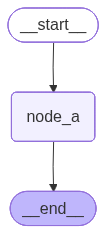


```text
============================== -> interrupt_res <- ==============================

{'__interrupt__': [Interrupt(value='请输入您的姓名', id='3543beca616d469fe1ccd35250ef5acf')]}

============================== -> resumed_res <- ==============================

{'username': '小黄'}
```


## 8.1.4.2. 多个并行中断


```python
from typing import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, interrupt
from langgraph.checkpoint.memory import InMemorySaver

class OverAllState(TypedDict):
    username: str
    age: int

def node_a(state: OverAllState) -> OverAllState:
    username = interrupt("请输入您的姓名")
    return {
        "username": username
    }

def node_b(state: OverAllState) -> OverAllState:
    age = interrupt("请输入您的年龄")
    return {
        "age": age
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

config = {"configurable": {"thread_id": "123"}}
interrupted_res = graph.invoke({}, config=config)
print('=' * 30, '-> interrupt_res <-', '=' * 30)
print(interrupted_res)

# 构建 中断ID -> 恢复指令 的映射
resume_map = {}
for i in interrupted_res['__interrupt__']:
    user_input = input(f"{i.value}: ")
    if "年龄" in i.value:
        resume_map[i.id] = int(user_input)
    else:
        resume_map[i.id] = user_input

resumed_res = graph.invoke(Command(resume=resume_map), config=config)
print('=' * 30, '-> resumed_res <-', '=' * 30)
print(resumed_res)
```


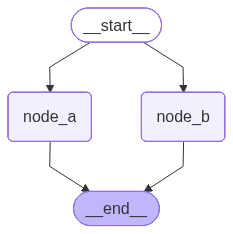


```text
============================== -> interrupt_res <- ==============================

{'__interrupt__': [Interrupt(value='请输入您的年龄', id='2770f00729006c756d481fffa712bb27'), Interrupt(value='请输入您的姓名', id='db7e81e1d4f5cab611f07e0469e99854')]}

============================== -> resumed_res <- ==============================

{'username': '小黄', 'age': 19}
```


## 8.1.4.3. 审批模式


```python
from time import sleep
from typing import TypedDict, Literal

from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph,START,END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
load_dotenv(override=True)

model =ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking":{
            "type":"disabled"
        }
    }
)

#1. 声明状态
class OverAllState(TypedDict):
    topic:str
    poem:str
    is_approved:bool

#2. 声明节点
def approve_node(state:OverAllState) -> Command[Literal["llm_node","default_node"]]:
    is_approved = interrupt("是否同意调用模型?")
    goto = "llm_node" if is_approved else "default_node"
    return Command(
        goto=goto,
        update={"is_approved":is_approved}
    )

def llm_node(state:OverAllState) -> OverAllState:
    topic = state["topic"]
    res = model.invoke([HumanMessage(content=f"帮我写一首关于{topic}主题的七言绝句,只写诗句,不需要赏析")]).content

    return {
        "poem":res
    }

def default_node(state:OverAllState) -> OverAllState:
    return {
        "poem":"请求被拒绝"
    }

#3. 构建图
builder = StateGraph(state_schema=OverAllState)

builder.add_node("approve_node",approve_node)
builder.add_node("llm_node",llm_node)
builder.add_node("default_node",default_node)
builder.add_edge(START,"approve_node")
builder.add_edge("llm_node",END)
builder.add_edge("default_node",END)

#4. 添加检查点后端
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

#5. 首次执行 -> 触发中断
config = {"configurable":{"thread_id":"234"}}
interrupt_res = graph.invoke({"topic":"菊花"},config=config)
print(interrupt_res)
#6. 人工审核
user_approved = input("是否同意调用模型?(y/n)").strip().lower() == 'y'
# 重新调用图
approved_res = graph.invoke(Command(resume=user_approved),config=config)
print(approved_res)

#7. 审核不通过
config1 = {"configurable":{"thread_id":"456"}}
interrupt_res = graph.invoke({"topic":"牡丹花"},config=config1)
print(interrupt_res)

user_approved = input("是否同意调用模型?(y/n)").strip().lower() == 'y'
# 重新调用图
approved_res = graph.invoke(Command(resume=user_approved),config=config1)
print(approved_res)
```


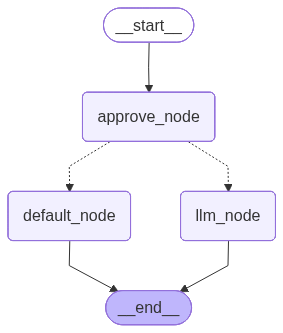


```text
{'topic': '菊花', '__interrupt__': [Interrupt(value='是否同意调用模型?', id='91edf41ecf736a242c18fd61d40ad5b4')]}

{'topic': '菊花', 'poem': '《咏菊》\n西风猎猎卷霜华，独抱秋心隐士家。\n冷艳不争桃李色，寒香偏入野人茶。', 'is_approved': True}

{'topic': '牡丹花', '__interrupt__': [Interrupt(value='是否同意调用模型?', id='47958afc1277b7ce6bf850a5f27f2e46')]}
{'topic': '牡丹花', 'poem': '请求被拒绝', 'is_approved': False}
```


## 8.1.4.4. 审核与编辑模式


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, interrupt
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    reviewed_poem: str

def llm_node(state: OverAllState) -> OverAllState:
    topic = state['topic']

    res = model.invoke([HumanMessage(content=f"帮我写一首关于 {topic} 的七言绝句，只给出诗句，不要赏析")]).content
    return {
        "poem": res
    }

def review_node(state: OverAllState) -> OverAllState:
    reviewed_poem = interrupt({
        "instruction": "请审核并修改大模型生成的七言绝句",
        "poem": state['poem']
    })
    return {
        "reviewed_poem": reviewed_poem
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("llm_node", llm_node)
builder.add_node("review_node", review_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", "review_node")
builder.add_edge("review_node", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

config = {"configurable": {"thread_id": "review_test"}}
interrupted_res = graph.invoke({"topic": "布偶猫"}, config=config)
print('=' * 30, '-> interrupt_res <-', '=' * 30)
print(interrupted_res)

print("原始诗句：")
print(interrupted_res['__interrupt__'][0].value['poem'])
user_review = input("请审核并修改诗句（直接回车保留原诗）: ")
if not user_review.strip():
    user_review = interrupted_res['__interrupt__'][0].value['poem']
reviewed_res = graph.invoke(Command(resume=user_review), config=config)
print('=' * 30, '-> reviewed_res <-', '=' * 30)
print(reviewed_res)
```


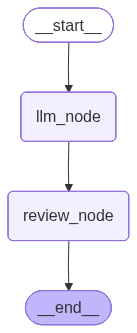


```text
============================== -> interrupt_res <- ==============================

{'topic': '布偶猫', 'poem': '《布偶猫》\n冰眸玉骨雪团身，蓝影衔春卧月轮。\n偶启朱唇呼入梦，云鬟一枕醉红尘。', '__interrupt__': [Interrupt(value={'instruction': '请审核并修改大模型生成的七言绝句', 'poem': '《布偶猫》\n冰眸玉骨雪团身，蓝影衔春卧月轮。\n偶启朱唇呼入梦，云鬟一枕醉红尘。'}, id='de13581234c57fb8b5d9620295b8239e')]}

============================== -> reviewed_res <- ==============================

{'topic': '布偶猫', 'poem': '《布偶猫》\n冰眸玉骨雪团身，蓝影衔春卧月轮。\n偶启朱唇呼入梦，云鬟一枕醉红尘。', 'reviewed_poem': '已审核：《布偶猫》\n冰眸玉骨雪团身，蓝影衔春卧月轮。\n偶启朱唇呼入梦，云鬟一枕醉红尘。'}
```


## 8.1.4.5. 工具执行审批模式


```python
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, interrupt
from langgraph.graph.message import MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langchain.messages import HumanMessage, ToolMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek

from loguru import logger
from dotenv import load_dotenv
load_dotenv(override=True)

@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    查询指定城市的当日天气

    Args:
        city: 城市名称
    """
    is_approved = interrupt({
        "action": "get_weather",
        "question": "是否同意查询天气？"
    })

    logger.info("is_approved: {}", is_approved)
    if is_approved:
        return f"{city} 今天天气不错"
    else:
        return "用户拒绝查询天气"

tools_by_name = {"get_weather": get_weather}

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)
model_with_tools = model.bind_tools([get_weather])

def llm_node(state: MessagesState) -> MessagesState:
    messages = state['messages']
    response = model_with_tools.invoke(messages)

    return {
        "messages": [response]
    }

def tool_node(state: MessagesState) -> MessagesState:
    last_msg = state['messages'][-1]

    tool_msgs = []
    for tool_call in last_msg.tool_calls:
        tool = tools_by_name[tool_call["name"]]
        logger.info("工具 {} 被调用, 对应的 tool_call: {}", tool_call["name"], tool_call)
        tool_res = tool.invoke(tool_call["args"])
        tool_msg = ToolMessage(
            name = tool_call["name"],
            content = tool_res,
            tool_call_id = tool_call["id"]
        )
        tool_msgs.append(tool_msg)

    return {
        "messages": tool_msgs
    }

def router(state: MessagesState) -> Literal["tool_node", END]:
    if state['messages'][-1].tool_calls:
        return "tool_node"
    return END

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_edge(START, "llm_node")
builder.add_conditional_edges("llm_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "llm_node")

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

config = {"configurable": {"thread_id": "tool_test"}}
interrupted_res = graph.invoke({"messages": [HumanMessage("今天北京天气如何？")]}, config=config)
print('=' * 30, '-> interrupt_res <-', '=' * 30)
for msg in interrupted_res['messages']:
    msg.pretty_print()
print('=' * 30, '-> interrupt_info <-', '=' * 30)
print(interrupted_res['__interrupt__'])

user_approved = input("是否同意查询天气？(y/n): ").strip().lower() == 'y'
approved_res = graph.invoke(Command(resume=user_approved), config=config)
print('=' * 30, '-> approved_res <-', '=' * 30)
for msg in approved_res['messages']:
    msg.pretty_print()
```


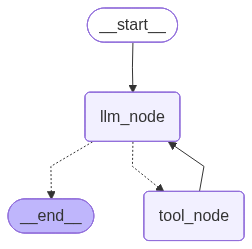


**示例输出（精简）**

```text
============================== -> interrupt_res <- ==============================
================================ Human Message =================================
今天北京天气如何？
================================== Ai Message ==================================
好的，我来查询一下今天北京的天气情况。
Tool Calls:
  get_weather (call_00_EGxsgveRV6mFkXsTtN4H9369)
 Call ID: call_00_EGxsgveRV6mFkXsTtN4H9369
  Args:
    city: 北京
============================== -> interrupt_info <- ==============================
...（中间日志/重复事件省略）...
    city: 北京
================================= Tool Message =================================
Name: get_weather
北京 今天天气不错
================================== Ai Message ==================================
今天北京的天气**不错**哦！☀️ 是个适合出行的好天气。如果需要更详细的天气信息（如温度、风力等），可以随时告诉我，我帮你进一步查询！
```


## 8.1.4.6. 单节点串行中断模式


```python
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command

class OverAllState(TypedDict):
    username: str # 姓名
    age: int # 年龄
    gender: Literal["male", "female"] # 性别

def get_info_node(state: OverAllState) -> OverAllState:
    username = interrupt("请输入您的用户名：")
    age = interrupt("请输入您的年龄：")
    gender = interrupt("请输入您的性别：(male/female)")

    return {
        "username": username,
        "age": age,
        "gender": gender
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("get_info_node", get_info_node)
builder.add_edge(START, "get_info_node")
builder.add_edge("get_info_node", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "seq_interrupt_test"}}
username_interrupted_res = graph.invoke({}, config=config)
print('=' * 30, '-> username_interrupted_res <-', '=' * 30)
print(username_interrupted_res)

user_name = input("请输入您的用户名：")
age_interrupted_res = graph.invoke(Command(resume=user_name), config=config)
print('=' * 30, '-> age_interrupted_res <-', '=' * 30)
print(age_interrupted_res)

user_age = input("请输入您的年龄：")
gender_interrupted_res = graph.invoke(Command(resume=int(user_age)), config=config)
print('=' * 30, '-> gender_interrupted_res <-', '=' * 30)
print(gender_interrupted_res)

user_gender = input("请输入您的性别：(male/female): ")
resumed_res = graph.invoke(Command(resume=user_gender), config=config)
print('=' * 30, '-> resumed_res <-', '=' * 30)
print(resumed_res)
```


```text
============================== -> username_interrupted_res <- ==============================
{'__interrupt__': [Interrupt(value='请输入您的用户名：', id='0359f8a0b1ca357d2d092d5c55d80ec1')]}
============================== -> age_interrupted_res <- ==============================
{'__interrupt__': [Interrupt(value='请输入您的年龄：', id='0359f8a0b1ca357d2d092d5c55d80ec1')]}
============================== -> gender_interrupted_res <- ==============================
{'__interrupt__': [Interrupt(value='请输入您的性别：(male/female)', id='0359f8a0b1ca357d2d092d5c55d80ec1')]}
============================== -> resumed_res <- ==============================
{'username': '小黄', 'age': 15, 'gender': 'male'}
```


中断恢复时，整个被中断的节点函数都会重新运行。

单个节点中串行地多次调用 **`interrupt()`** 函数时，检查点存储器会记录历史的 **`resume`** 信息，**`LangGraph`** 运行时会读取这些信息，并在 **`interrupt()`** 函数中维护索引，按照节点内调用 **`interrupt()`** 函数的顺序，逐个取出历史 **`resume`** 的值，并将它们作为 **`interrupt()`** 函数的返回值。

所以，已经被恢复的 **`interrupt()`** 不会被重复触发。并且，由此可以推断，我们要保证历史 **`resume`** 可以被正确应用，就应保证中断恢复前后的多次 **`interrupt()`** 相对顺序保持不变。

当历史 **`resume`** 耗尽后，本次恢复运行时传入的 **`resume`** 会作为本次中断的返回值，然后节点函数继续运行。

所有中断都触发并恢复后，计算图正常结束。


## 8.1.5.1. 不要用`try/catch`包裹`interrupt()`调用


中断的触发是通过抛出 **`GraphInterrupt`** 异常实现的，如果用 **`try/catch`** 包裹，则底层运行时无法感知断点，不会中断计算图。

**正确用法**


```python
def node_a(state: State):
    # ✅ 正确用法：先打断点，再处理异常
    interrupt("What's your name?")
    try:
        fetch_data()  # 这一步可能失败
    except Exception as e:
        print(e)
    return state
```


**错误用法**


```python
def node_a(state: State):
    # ❌ 错误用法，用 try/catch 包裹 interrupt()，这将会导致 GraphInterrupt 被捕获而无法触发中断
    try:
        interrupt("What's your name?")
        fetch_data()  # 这一步可能失败
    except Exception as e:
        print(e)
    return state
```


## 8.1.5.2. 不要更改单个节点内`interrupt`的调用顺序

上文提到：

1. 恢复运行时整个节点函数都会重新运行，而非精确地从断点继续
2. 同一节点中存在多个断点时：历史恢复记录被记录在检查点中，并在恢复运行时按顺序加载

一旦中断恢复前后的断点顺序、数量不完全一致，将会导致语义混乱，程序执行结果无法满足预期。

这条规范就是为了避免这样的情况。

**正确用法**


```python
def node_a(state: State):
    # ✅ 正确用法，断点顺序固定
    name = interrupt("What's your name?")
    age = interrupt("What's your age?")
    city = interrupt("What's your city?")

    return {
        "name": name,
        "age": age,
        "city": city
    }
```


**错误用法**

**1. 可能跳过其中部分断点**


```python
def node_a(state: State):
    # ❌ 错误用法，以状态为条件，可能跳过部分断点
    name = interrupt("What's your name?")

    # 第一次运行到此处时，可能不会触发分支内的断点
    # 恢复时，resume 本应作为 city，但如果分支内断点触发，将被错误地作为 age，导致语义混乱
    if state.get("needs_age"):
        age = interrupt("What's your age?")

    city = interrupt("What's your city?")

    return {"name": name, "city": city}
```


断点以状态为条件，如果中断恢复前后状态发生了变化，断点的顺序和数量可能发生变化，导致语义混乱。

**2. 基于不确定的数据循环，并在其中设置断点**


```python
def node_a(state: State):
    # ❌ 错误用法：基于不确定的数据循环
    # 每次调用时的断点数量可能不同
    results = []
    for item in state.get("dynamic_list", []):  # List might change between runs
        result = interrupt(f"Approve {item}?")
        results.append(result)

    return {"results": results}
```


基于状态中可变的值循环，并在循环中设置断点，如果中断恢复前后状态发生变化，断点数量可能变化，导致语义混乱。


## 8.1.5.3. 不要在`interrupt()`中传递复杂类型

**`LangGraph`** 运行时会将 **`interrupt()`** 函数接收到的参数经过 **`JSON` 序列化** 之后传递给调用者。

如果传递不支持 **`JSON` 序列化** 的复杂类型，如函数，将会抛出异常，如下所示


```text
TypeError: Type is not msgpack serializable: Interrupt
```


**正确用法**

**1. 简单类型**


```python
def node_a(state: State):
    # ✅ 正确用法：传递可以序列化的简单类型数据
    name = interrupt("What's your name?")
    count = interrupt(42)
    approved = interrupt(True)

    return {"name": name, "count": count, "approved": approved}
```


**2. 结构化数据**


```python
def node_a(state: State):
    # ✅ 正确用法：传递仅包含基本数据类型的可序列化字典
    response = interrupt({
        "question": "Enter user details",
        "fields": ["name", "email", "age"],
        "current_values": state.get("user", {})
    })

    return {"user": response}
```


**错误用法**

**1. 函数**


```python
def validate_input(value):
    return len(value) > 0

def node_a(state: State):
    # ❌ 错误用法：传递函数
    # 函数不支持 JSON 序列化
    response = interrupt({
        "question": "What's your name?",
        "validator": validate_input  # 此处会导致失败
    })
    return {"name": response}
```


**2. 类的实例**


```python
class DataProcessor:
    def __init__(self, config):
        self.config = config

def node_a(state: State):
    processor = DataProcessor({"mode": "strict"})

    # ❌ 错误用法：传递类的实例
    # 此处的自定义实例不支持 JSON 序列化
    response = interrupt({
        "question": "Enter data to process",
        "processor": processor  # 这将会导致失败
    })
    return {"result": response}
```


## 8.1.5.4. 断点之前的副作用操作必须是幂等的

- **副作用操作**：修改了外部环境的操作，如
  - 写数据库
  - 写文件
  - 发送邮件或消息
- **幂等性**：多次执行的结果等价于一次执行。

我们知道，中断恢复时，断点所在的函数会被重复执行，所以，如果断点之前存在不满足幂等性的副作用操作，将会导致多次调用结果不一致。

如：写数据操作不满足幂等性，可能导致写入多条重复记录。

**正确用法**

**1. 在断点之前使用满足幂等性的操作**


```python
def node_a(state: State):
    # ✅ 正确用法：使用幂等的 upsert 操作
    # 多次运行结果一致
    db.upsert_user(
        user_id=state["user_id"],
        status="pending_approval"
    )

    approved = interrupt("Approve this change?")

    return {"approved": approved}
```


**`upsert`** 的语义是：**写入或更新**，如果有相同记录则覆盖更新，否则新增。满足幂等性。

**2. 将副作用操作放在断点之后**


```python
def node_a(state: State):
    # ✅ 正确用法：将副作用操作放在断点之后
    # 确保副作用操作只运行一次
    approved = interrupt("Approve this change?")

    if approved:
        db.create_audit_log(
            user_id=state["user_id"],
            action="approved"
        )

    return {"approved": approved}
```


上述代码将副作用操作置于断点之后，之后中断触发并恢复运行之后，副作用操作才会被执行，后者只会被执行一次。

**3. 将副作用操作和断点置于不同的节点**


```python
def approval_node(state: State):
    # ✅ 正确用法：当前节点只做中断
    approved = interrupt("Approve this change?")

    return {"approved": approved}

def notification_node(state: State):
    # ✅ 正确用法：副作用操作发生在独立的节点中
    # 当前节点独立于中断，所以副作用操作，不会因为中断恢复而重复执行
    if (state.approved):
        send_notification(
            user_id=state["user_id"],
            status="approved"
        )

    return state
```


这种方式更彻底，将中断和副作用操作完全隔离。

**错误用法**

**1. 在断点之前向数据库中新增数据**


```python
def node_a(state: State):
    # ❌ 错误用法：在断点之前向数据库中新增数据
    # 中断恢复会导致数据重复
    audit_id = db.create_audit_log({
        "user_id": state["user_id"],
        "action": "pending_approval",
        "timestamp": datetime.now()
    })

    approved = interrupt("Approve this change?")

    return {"approved": approved, "audit_id": audit_id}
```


**2. 将数据追加到已存在的列表**


```python
def node_a(state: State):
    # ❌ 错误用法：在断点之前向列表追加数据
    # 这将会在中断恢复时导致列表数据重复
    db.append_to_history(state["user_id"], "approval_requested")

    approved = interrupt("Approve this change?")

    return {"approved": approved}
```


## 8.1.6.1. 基础`HITL`模式


### 8.1.6.1.1. 示例代码


```python
from typing import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, interrupt
from langgraph.checkpoint.memory import InMemorySaver

class OverAllState(TypedDict):
    username: str
    age: int

def node_a(state: OverAllState) -> OverAllState:
    username = interrupt("请输入您的姓名")
    age = interrupt("请输入您的年龄")
    return {
        "username": username,
        "age": age
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

config = {"configurable": {"thread_id": "123"}}
username_interrupted_res = graph.invoke({}, config=config)
print('=' * 30, '-> username_interrupted_res <-', '=' * 30)
print(username_interrupted_res)
username_interrupted_his = list(graph.get_state_history(config=config))
print('=' * 30, '-> username_interrupted_his <-', '=' * 30)
print(username_interrupted_his)

age_interrupted_res = graph.invoke(Command(resume="小黄"), config=config)
print('=' * 30, '-> age_interrupted_res <-', '=' * 30)
print(age_interrupted_res)
age_interrupted_his = list(graph.get_state_history(config=config))
print('=' * 30, '-> age_interrupted_his <-', '=' * 30)
print(age_interrupted_his)

resumed_res = graph.invoke(Command(resume=123), config=config)
print('=' * 30, '-> resumed_res <-', '=' * 30)
print(resumed_res)
resumed_his = list(graph.get_state_history(config=config))
print('=' * 30, '-> resumed_his <-', '=' * 30)
print(resumed_his)
```


### 8.1.6.1.2. 运行结果分析

#### 8.1.6.1.2.1. 第一次中断

**调用结果**


```text
============================== -> username_interrupted_res <- ==============================
{'__interrupt__': [Interrupt(value='请输入您的姓名', id='488d1fa95a4053d41ab09786f5260ae9')]}
```


**历史检查点**


**示例输出（精简）**

```text
# 快照关键字段摘录（非完整 Python 对象；随机 ID 用 <id> 表示）
============================== -> username_interrupted_his <- ==============================
[
        values={},
        next=('node_a',),
        config={
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
            }
            'source': 'loop',
            'step': 0,
            'parents': {}
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
            }
...（中间快照省略）...
                interrupts=(),
                state=None,
                result={}
            ),
        interrupts=()
    )
```


当前工作流只有一个节点，所以只有一个真正执行用户自定义节点的超步，对应的超步编号为 **`1`**

中断触发时，检查点存储器中记录的最新检查点超步为 **`0`**，中断信息只能和这个超步绑定

中断信息存了两份：

- **`StateSnapshot`** 的 **`tasks`** 属性下记录的 **`PregelTask`** 实例的 **`interrupts`** 字段记录了当前任务触发的中断信息。

- **`StateSnapshot`** 的 **`interrupts`** 属性记录了当前超步发生的所有中断

当存在多个并行中断时

- 中断信息被记录在各自所属任务的 **`PregelTask`** 实例中
- 同时也会被汇总在 **`StateSnapshot`** 的 **`tasks`** 属性中

#### 8.1.6.1.2.2. 第一次恢复

**调用结果**


```text
============================== -> age_interrupted_res <- ==============================
{'__interrupt__': [Interrupt(value='请输入您的年龄', id='488d1fa95a4053d41ab09786f5260ae9')]}
```


**历史检查点**


**示例输出（精简）**

```text
# 快照关键字段摘录（非完整 Python 对象；随机 ID 用 <id> 表示）
============================== -> age_interrupted_his <- ==============================

        values={},
        next=('node_a',),
        config={
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
            }
            'source': 'loop',
            'step': 0,
            'parents': {}
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
            }
...（中间快照省略）...
                interrupts=(),
                state=None,
                result={}
            ),
        interrupts=()
    )
```


**`checkpoint_id`、任务`id`、中断`id`** 和历史检查点完全一致，只是 **`Interrupt`** 实例的 **`value`** 属性变成了第二次中断的值。

由此可见，恢复运行时检查点的更新确实是覆盖写入，历史中断信息不会被保留。

并且，中断恢复时传递的 **`resume`** 在 **`graph.get_state_history()`** 时也不可见。

#### 8.1.6.1.2.3. 第二次恢复

**调用结果**


```text
============================== -> resumed_res <- ==============================
{'username': '小黄', 'age': 123}
```


**历史检查点**


**示例输出（精简）**

```text
# 快照关键字段摘录（非完整 Python 对象；随机 ID 用 <id> 表示）
        values={
            'username': '小黄',
            'age': 123
        },
        next=(),
        config={
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
            }
            'source': 'loop',
            'step': 1,
            'parents': {}
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
...（中间快照省略）...
                interrupts=(),
                state=None,
                result={}
            ),
        interrupts=()
    )
```


两个断点全部恢复运行后，编号为 **`1`** 的超步终于完成，任务实例的 **`result`** 被更新，状态被更新，最后一个超步的 **`values`** 是更新后的状态值，计算图运行完成。


## 8.1.6.2. 多个并行中断触发时的检查点

### 8.1.6.2.1. 示例代码


```python
from typing import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, interrupt
from langgraph.checkpoint.memory import InMemorySaver

class OverAllState(TypedDict):
    username: str
    age: int

def node_a(state: OverAllState) -> OverAllState:
    username = interrupt("请输入您的姓名")
    return {
        "username": username
    }

def node_b(state: OverAllState) -> OverAllState:
    age = interrupt("请输入您的年龄")
    return {
        "age": age
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

config = {"configurable": {"thread_id": "123"}}
interrupted_res = graph.invoke({}, config=config)
print('=' * 30, '-> interrupt_res <-', '=' * 30)
print(interrupted_res)

list(graph.get_state_history(config=config))

# 6. 恢复执行
resume_map = {}
for i in interrupted_res['__interrupt__']:
    user_input = input(f"{i.value}:")
    if "年龄" in i.value:
        resume_map[i.id] = int(user_input)
    else:
        resume_map[i.id] = user_input

resumed_res = graph.invoke(Command(resume=resume_map),config=config)
print(resumed_res)

list(graph.get_state_history(config=config))
```


### 8.1.6.2.2. 结果分析

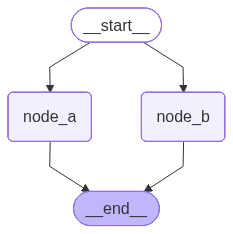

**计算图返回值**


```text
============================== -> interrupt_res <- ==============================

{
    '__interrupt__': [
        Interrupt(
            value='请输入您的姓名',
            id='0cae1932a74087f02711c6f1677b4b17'
        ),
        Interrupt(
            value='请输入您的年龄',
            id='cd216e1ad6907c2432636ff5f32cfcf3'
        )
    ]
}
```


同一个超步中并行触发的中断信息被放在列表中返回。

**历史检查点列表**


**示例输出（精简）**

```text
# 快照关键字段摘录（非完整 Python 对象；随机 ID 用 <id> 表示）
        values={},

        next=(
            'node_a',
            'node_b'
        ),
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
            }
            'source': 'loop',
            'step': 0,
            'parents': {}
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
...（中间快照省略）...
                interrupts=(),
                state=None,
                result={}
            ),
        interrupts=()
    )
```


如前所述，编号为 **`1`** 的超步执行时中断触发，此时检查点后端中存储的最新的超步编号为 **`0`**，因此中断信息记录在超步 **`0`** 的 **`StateSnapshot`** 实例中。

- 快照实例的 **`interrupts`** 属性记录了并行触发的两个中断的信息。

- 并且，各自的中断信息被记录在对应的任务实例中。


## 8.1.6.3. 同一超步部分任务触发中断时的检查点

### 8.1.6.3.1. 示例代码


```python
from typing import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, interrupt
from langgraph.checkpoint.memory import InMemorySaver

class OverAllState(TypedDict):
    username: str
    age: int

def node_a(state: OverAllState) -> OverAllState:
    username = interrupt("请输入您的姓名")
    return {
        "username": username
    }

def node_b(state: OverAllState) -> OverAllState:
    age = 12
    return {
        "age": age
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

from IPython.display import display
display(graph)

config = {"configurable": {"thread_id": "123"}}
interrupted_res = graph.invoke({}, config=config)
print('=' * 30, '-> interrupt_res <-', '=' * 30)
print(interrupted_res)

list(graph.get_state_history(config=config))
```


### 8.1.6.3.2. 结果分析

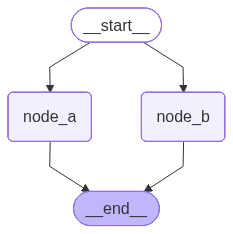

**计算图返回值**


```text
============================== -> interrupt_res <- ==============================

{
    'age': 12,
    '__interrupt__': [
        Interrupt(
            value='请输入您的姓名',
            id='bbff88193340fd0ed196be702608e385'
        )
    ]
}
```


**历史检查点列表**


**示例输出（精简）**

```text
# 快照关键字段摘录（非完整 Python 对象；随机 ID 用 <id> 表示）
        values={},
        next=(
            'node_a',
            'node_b'
        ),
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
            }
            'source': 'loop',
            'step': 0,
            'parents': {}
        parent_config={
            'configurable': {
                'thread_id': '123',
                'checkpoint_ns': '',
                'checkpoint_id': '<id>'
            }
...（中间快照省略）...
                interrupts=(),
                state=None,
                result={}
            ),
        interrupts=()
    )
```


由上可知，同一个超步中：

- 发生中断的任务，其中断信息被记录在任务实例和快照的 **`interrupts`** 字段中

- 未触发中断的任务正常结束，其结果被记录在任务实例的 **`result`** 字段中

底层负责执行节点逻辑的是超步的第二阶段，如果存在多个并行任务，则会将任务提交到线程池，在独立的线程中运行，负责执行第二阶段的 **`PregelRunner`** 实例会收集提交后的 **`future`** 对象，并等待所有任务完成。

当中断触发时，对应的线程会抛出 **`GraphInterrupt`**，对应的 **`future`** 对象会收集异常。

**`PregelRunner`** 实例在 **`future`** 对应的任务完成后，收集中断信息或任务执行结果，写入检查点存储器。

所以一个超步中某个任务触发中断，不会导致其它并行任务的终止，正常运行的任务结果、中断任务的中断信息都被记录在检查点后端。


## 8.2. 静态断点

**`LangGraph`** 提供了用于调试的 **静态断点**。

它是在状态图编译或调用时设置的，断点位置在运行前确定，执行到对应边界才会暂停；它主要用于调试，所以称为 **静态** 断点。

动态中断提供业务提示和 `Command(resume=...)` 的反馈接口。静态断点返回当前状态供调试，没有同样的业务提示/恢复值协议；需要修改状态时可以显式使用 update_state，再以 None 输入继续。


## 8.2.1. 用法说明

1. 静态断点也需要基于检查点恢复，所以必须配置检查点，启用可恢复运行机制。

2. 计算图会在 **`interrupt_before`** 指定的节点执行之前产生中断，暂停计算

3. 计算图会在 **`interrupt_after`** 指定的节点执行之后产生中断，暂停计算

4. 计算图运行到断点位置会中断，和动态断点不同的是，它会在超步边界而非内部中断。

   断点前的超步：三个阶段全部完成；断点后的超步：三个阶段都没有开始。

5. 静态断点不会返回任何中断信息，只会将当前最新的状态返回。

   因此，我们可以用静态断点查看每个超步边界的中间状态。

6. 传入相同的配置并将 **`None`** 作为输入，再次调用计算图，会从断点位置继续运行。

7. 支持在两个阶段设置静态断点

   - 状态图编译时


```text
     graph = builder.compile(
         checkpointer=checkpointer,
         interrupt_before=["node_a", "node_b"],
         interrupt_after=["node_a", "node_b"]
     )
```


   - 计算图调用时


```text
     first_res = graph.invoke(
         {},
         config=config,
         interrupt_before=["node_a", "node_b"],
         interrupt_after=["node_a", "node_b"]
     )
```


   断点都是在运行时生效，计算图调用时设置的断点优先级更高。

   如果调用时传入的断点列表不为空，则会覆盖编译时配置。


## 8.2.2. 底层原理

1. 编译时设置的静态断点保存在编译图的 **`interrupt_before_nodes`** 和 **`interrupt_after_nodes`** 中。

   运行时采用调用参数优先、编译配置兜底的规则。

   调用时传入非空节点列表会完全覆盖编译配置，而 **`None`** 或空列表会回退到编译配置。

2. **`interrupt_before`** 在超步的第一阶段：当前超步的任务列表计算完成后、节点任务开始执行前进行检查。

   - 如果检查点中的状态和上一次静态断点或图的初始状态相比，产生了变化
   - 并且当前超步的任务列表和 **`interrupt_before`** 列表存在交集

   则抛出 **`GraphInterrupt`**。

3. **`interrupt_after`** 在超步的第三阶段：当前超步的任务全部执行完成、写入应用到通道并创建检查点之后进行检查。

   - 如果检查点中的状态和上一次静态断点或图的初始状态相比，产生了变化
   - 并且当前超步的任务列表和 **`interrupt_after`** 列表存在交集

   则抛出 **`GraphInterrupt`**。

4. 如果存在这样的拓扑图


```text
   node_a -> node_b
```


   那么在 **`node_a` 之后** 和 **`node_b` 之前** 设置断点只会中断一次。

   因为二者对应同一个超步边界，如果同时配置：

   - **`node_a`** 的 **`after`** 先触发；

   - 恢复运行时检查点中记录的上次断点可见状态会被更新，和最新状态保持一致

   - 而产生中断之前已经保存了检查点，恢复运行时会从 **`node_b`** 的超步开始
   - **`node_b`** 的超步第一阶段，检查点和上次静态断点相比，没有变化，所以不会中断
   - 因此，**`node_a` 之后** 和 **`node_b` 之前** 设置断点只会中断一次


## 8.2.3.1. 编译时设置断点


### 8.2.3.1.1. 顺序结构设置断点


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

from loguru import logger

class OverAllState(TypedDict):
    final_res: str

def node_a(state: OverAllState) -> OverAllState:
    logger.info("node_a 被执行")
    return {
        "final_res": "node_a 运行的中间结果"
    }

def node_b(state: OverAllState) -> OverAllState:
    logger.info("node_b 被执行")
    return {
        "final_res": "node_b 运行的中间结果"
    }

def node_c(state: OverAllState) -> OverAllState:
    logger.info("node_c 被执行")
    return {
        "final_res": "node_c 运行的中间结果"
    }


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", "node_c")
builder.add_edge("node_c", END)

checkpointer = InMemorySaver()
graph = builder.compile(
    checkpointer=checkpointer,
    interrupt_before=["node_a", "node_b"],
    interrupt_after=["node_a", "node_b"]
)

from IPython.display import display
display(graph)

config = {"configurable": {"thread_id": "123"}}

logger.info("{}-> 第一次执行 <-{}", "=" * 10, "=" * 10)
first_res = graph.invoke({}, config=config)
logger.info("第一次执行结果：{}", first_res)

logger.info("{}-> 第二次执行 <-{}", "=" * 10, "=" * 10)
second_res = graph.invoke(None, config=config)
logger.info("第二次执行结果：{}", second_res)

logger.info("{}-> 第三次执行 <-{}", "=" * 10, "=" * 10)
third_res = graph.invoke(None, config=config)
logger.info("第三次执行结果：{}", third_res)

logger.info("{}-> 第四次执行 <-{}", "=" * 10, "=" * 10)
final_res = graph.invoke(None, config=config)
logger.info("第四次执行结果：{}", final_res)

logger.info("{}-> 完毕 <-{}", "=" * 10, "=" * 10)
```


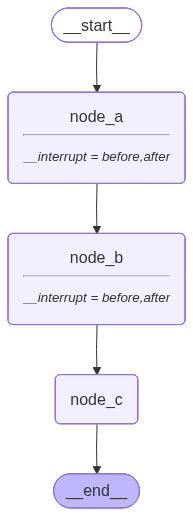

编译时设置的断点在渲染拓扑结构时被感知，图中对应结点新增了断点标记：


```python
__interrupt = before,after
```


这表示该节点之前和之后都设置了断点。

**日志如下**


**示例输出（精简）**

```text

```


由日志可知，**`node_a`** 和 **`node_b`** 之间只产生了一次中断，和分析相符。

### 8.2.3.1.2. 存在并行节点时设置断点

为了确定断点是 **以节点** 为边界还是 **以超步** 为边界设置的，我们在存在并行节点的计算图中测试


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

from loguru import logger

class OverAllState(TypedDict):
    final_res: str

def node_a(state: OverAllState) -> OverAllState:
    logger.info("node_a 被执行")
    return {
        "final_res": "node_a 运行的中间结果"
    }

def node_b(state: OverAllState) -> OverAllState:
    logger.info("node_b 被执行")
    return {
        "final_res": "node_b 运行的中间结果"
    }

def node_c(state: OverAllState) -> OverAllState:
    logger.info("node_c 被执行")
    return {
        "final_res": "node_c 运行的中间结果"
    }

def node_d(state: OverAllState) -> OverAllState:
    logger.info("node_d 被执行")
    return {}

def node_e(state: OverAllState) -> OverAllState:
    logger.info("node_e 被执行")
    return {}

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_node("node_d", node_d)
builder.add_node("node_e", node_e)

builder.add_edge(START, "node_a")
builder.add_edge(START, "node_d")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_d", "node_e")
builder.add_edge(["node_b", "node_e"], "node_c")
builder.add_edge("node_c", END)

checkpointer = InMemorySaver()
graph = builder.compile(
    checkpointer=checkpointer,
    interrupt_before=["node_a", "node_b"],
    interrupt_after=["node_a", "node_b"]
)

from IPython.display import display
display(graph)

config = {"configurable": {"thread_id": "123"}}

logger.info("{}-> 第一次执行 <-{}", "=" * 10, "=" * 10)
first_res = graph.invoke({}, config=config)
logger.info("第一次执行结果：{}", first_res)

logger.info("{}-> 第二次执行 <-{}", "=" * 10, "=" * 10)
second_res = graph.invoke(None, config=config)
logger.info("第二次执行结果：{}", second_res)

logger.info("{}-> 第三次执行 <-{}", "=" * 10, "=" * 10)
third_res = graph.invoke(None, config=config)
logger.info("第三次执行结果：{}", third_res)

logger.info("{}-> 第四次执行 <-{}", "=" * 10, "=" * 10)
final_res = graph.invoke(None, config=config)
logger.info("第四次执行结果：{}", final_res)

logger.info("{}-> 完毕 <-{}", "=" * 10, "=" * 10)
```


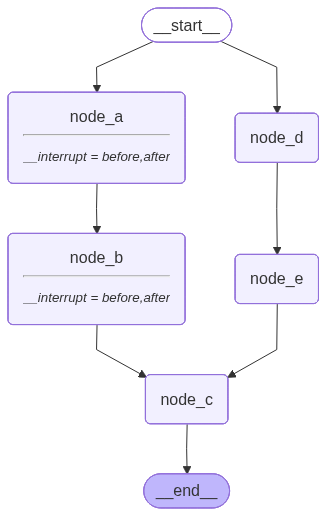


**示例输出（精简）**

```text

```


**`node_a`** 和 **`node_d`** 属于同一个超步

**`node_b`** 和 **`node_e`** 属于同一个超步

我们只在 **`node_a`** 和 **`node_b`** 前后设置了超步，但它们的并行节点也被中断了。

显然，中断发生在超步边界，而非节点边界，与分析相符。


## 8.2.3.2. 调用时设置断点

调用时的断点配置只对本次调用生效。

### 8.2.3.2.1. 正确用法：恢复调用时设置相同的断点


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

from loguru import logger

class OverAllState(TypedDict):
    final_res: str

def node_a(state: OverAllState) -> OverAllState:
    logger.info("node_a 被执行")
    return {
        "final_res": "node_a 运行的中间结果"
    }

def node_b(state: OverAllState) -> OverAllState:
    logger.info("node_b 被执行")
    return {
        "final_res": "node_b 运行的中间结果"
    }

def node_c(state: OverAllState) -> OverAllState:
    logger.info("node_c 被执行")
    return {
        "final_res": "node_c 运行的中间结果"
    }


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", "node_c")
builder.add_edge("node_c", END)

checkpointer = InMemorySaver()
graph = builder.compile(
    checkpointer=checkpointer
)

from IPython.display import display
display(graph)

config = {"configurable": {"thread_id": "123"}}

logger.info("{}-> 第一次执行 <-{}", "=" * 10, "=" * 10)
first_res = graph.invoke(
    {},
    config=config,
    interrupt_before=["node_a", "node_b"],
    interrupt_after=["node_a", "node_b"]
)
logger.info("第一次执行结果：{}", first_res)

logger.info("{}-> 第二次执行 <-{}", "=" * 10, "=" * 10)
second_res = graph.invoke(
    None,
    config=config,
    interrupt_before=["node_a", "node_b"],
    interrupt_after=["node_a", "node_b"]
)
logger.info("第二次执行结果：{}", second_res)

logger.info("{}-> 第三次执行 <-{}", "=" * 10, "=" * 10)
third_res = graph.invoke(
    None,
    config=config,
    interrupt_before=["node_a", "node_b"],
    interrupt_after=["node_a", "node_b"]
)
logger.info("第三次执行结果：{}", third_res)

logger.info("{}-> 第四次执行 <-{}", "=" * 10, "=" * 10)
final_res = graph.invoke(
    None,
    config=config,
    interrupt_before=["node_a", "node_b"],
    interrupt_after=["node_a", "node_b"]
)
logger.info("第四次执行结果：{}", final_res)

logger.info("{}-> 完毕 <-{}", "=" * 10, "=" * 10)
```


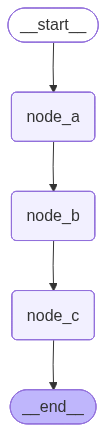


**示例输出（精简）**

```text

```


我们期望在 **`node_a`** 和 **`node_b`** 前后中断，此时运行结果和预期相符。

### 8.2.3.2.2. 错误用法：恢复调用时不再设置断点


```python
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

from loguru import logger

class OverAllState(TypedDict):
    final_res: str

def node_a(state: OverAllState) -> OverAllState:
    logger.info("node_a 被执行")
    return {
        "final_res": "node_a 运行的中间结果"
    }

def node_b(state: OverAllState) -> OverAllState:
    logger.info("node_b 被执行")
    return {
        "final_res": "node_b 运行的中间结果"
    }

def node_c(state: OverAllState) -> OverAllState:
    logger.info("node_c 被执行")
    return {
        "final_res": "node_c 运行的中间结果"
    }


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", "node_c")
builder.add_edge("node_c", END)

checkpointer = InMemorySaver()
graph = builder.compile(
    checkpointer=checkpointer
)

from IPython.display import display
display(graph)

config = {"configurable": {"thread_id": "123"}}

logger.info("{}-> 第一次执行 <-{}", "=" * 10, "=" * 10)
first_res = graph.invoke(
    {},
    config=config,
    interrupt_before=["node_a", "node_b"],
    interrupt_after=["node_a", "node_b"]
)
logger.info("第一次执行结果：{}", first_res)

logger.info("{}-> 第二次执行 <-{}", "=" * 10, "=" * 10)
second_res = graph.invoke(
    None,
    config=config,
    interrupt_before=["node_a", "node_b"],
    interrupt_after=["node_a", "node_b"]
)
logger.info("第二次执行结果：{}", second_res)

logger.info("{}-> 第三次执行 <-{}", "=" * 10, "=" * 10)
third_res = graph.invoke(None, config=config)
logger.info("第三次执行结果：{}", third_res)

logger.info("{}-> 第四次执行 <-{}", "=" * 10, "=" * 10)
final_res = graph.invoke(None, config=config)
logger.info("第四次执行结果：{}", final_res)

logger.info("{}-> 完毕 <-{}", "=" * 10, "=" * 10)
```


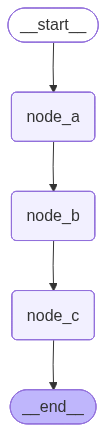


**示例输出（精简）**

```text

```


本例中，我们只在初次调用和第一次恢复运行时设置断点。

由日志可知，按照期望，第二次恢复运行之后，**`node_b`** 执行完成后还应中断一次，然而，因为本次没有设置断点，因此计算图不再中断，**`node_b`** 和 **`node_c`** 都在本次调用完成，计算图结束。

在第四次调用时，计算图已经运行完毕，恢复运行实际上不会执行任何逻辑，只是将计算图的最终状态返回。


## 9.1. 本地部署并对接`LangSmith`


**`LangSmith`** 是 **`LangChain`** 官方提供的 **`Agent`** 应用工程平台，主要用于对基于 **`LangGraph`**、**`LangChain`** 等框架开发的 **`Agent`** 应用进行运行链路追踪、调试、评估和生产监控。

**`LangChain`** 官方提供了开箱即用的 **`LangSmith` 云服务**，访问地址为：

> [https://smith.langchain.com](https://smith.langchain.com/)

此外，**`LangSmith`** 也支持混合部署和私有化部署。

除了基本的运行链路追踪，**`LangSmith` 云服务** 还提供了用于调试的 **`studio`**，要使用这个模块的功能，需要在本地部署 **`LangGraph`** 项目，这正是本节要完成的任务。

本节将部署一个经典的 **`HITL`** 应用，并在 **`LangSmith` 云服务** 的 **`studio`** 中调试。


## 9.1.1. 补充依赖

本章用命令行工具 **`langgraph-cli`** 部署项目，需要补充相关依赖，如下所示。

在 **`requirements_full.txt`** 中补充依赖


```text
# LangGraph 本地 Agent Server、Studio、热重载
langgraph-cli[inmem]==0.4.30
```


放在


```text
# =========================================================
# LangGraph / Agent 编排
# 作用：构建 Agent、状态图、多步骤工作流、检查点、PostgreSQL 持久化
# =========================================================
```


模块下

然后命令行启用项目的 **`conda`** 环境，执行


```powershell
(langgraph) PS C:\Users\Lenovo\OneDrive\文档\AI\langgraph> pip install -r .\requirements_full.txt
```


即可。


## 9.1.2. 准备本地项目

在项目任意位置创建 **`hitl_demo`** 目录，作为 **`LangGraph`** 本地项目的根目录。

### 9.1.2.1. 项目结构

项目结构如下所示


```powershell
hitl_demo/
├── src
    ├── __init__.py
│   └── agent.py
├── .env
└── langgraph.json
```


其中：

- **`src`**：源码包，存放业务代码
  - **`__init__.py`**：**`Python`** 包的初始化文件
  - **`agent.py`**：源码文件，包含业务逻辑，**`langgraph-cli`** 会根据配置文件读取其中的 **`Agent`** 或 **`Graph`** 对象。

- **`.env`**：当前项目的环境变量，本次部署时，**`langgraph-cli`** 会从中加载环境变量。对接 **`LangSmith` 云服务** 时，需要确保该文件中包含相关的环境变量。
- **`langgraph.json`**：项目配置文件，用于管理依赖并定位源码中的 **`agent`** 对象。

### 9.1.2.2. 代码清单

#### 9.1.2.2.1. `__init__.py`

留空即可。

#### 9.1.2.2.2. `agent.py`

写入以下内容


```python
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langgraph.types import interrupt

class OverAllState(TypedDict):
    username: str # 姓名
    age: int # 年龄
    gender: Literal["male", "female"] # 性别

def get_info_node(state: OverAllState) -> OverAllState:
    username = interrupt("请输入您的用户名：")
    age = interrupt("请输入您的年龄：")
    gender = interrupt("请输入您的性别：(male/female)")

    return {
        "username": username,
        "age": age,
        "gender": gender
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("get_info_node", get_info_node)
builder.add_edge(START, "get_info_node")
builder.add_edge("get_info_node", END)

graph = builder.compile()
```


**`graph`** 对象是我们希望调试的计算图实例。

**注意：** **`langgraph-cli`** 启动的本地服务会帮我们管理检查点，所以代码中不要传递检查点存储器，否则启动本地服务时将报错。

#### 9.1.2.2.3. `.env`

确保该文件中有 **`LANGSMITH_API_KEY`** 变量


```properties
LANGSMITH_API_KEY=xxx
```


可以根据需求添加所需的环境变量。

如果希望同时启用 **`LangSmith`** 的追踪功能，需要添加以下环境变量


```properties
LANGSMITH_TRACING=true
LANGSMITH_ENDPOINT=https://api.smith.langchain.com
LANGSMITH_PROJECT="hitl-demo" # 项目名称，自定义
```


配置后，可以在 **`LangSmith` 云服务** 的以下界面根据项目名称追踪应用运行的详细信息。

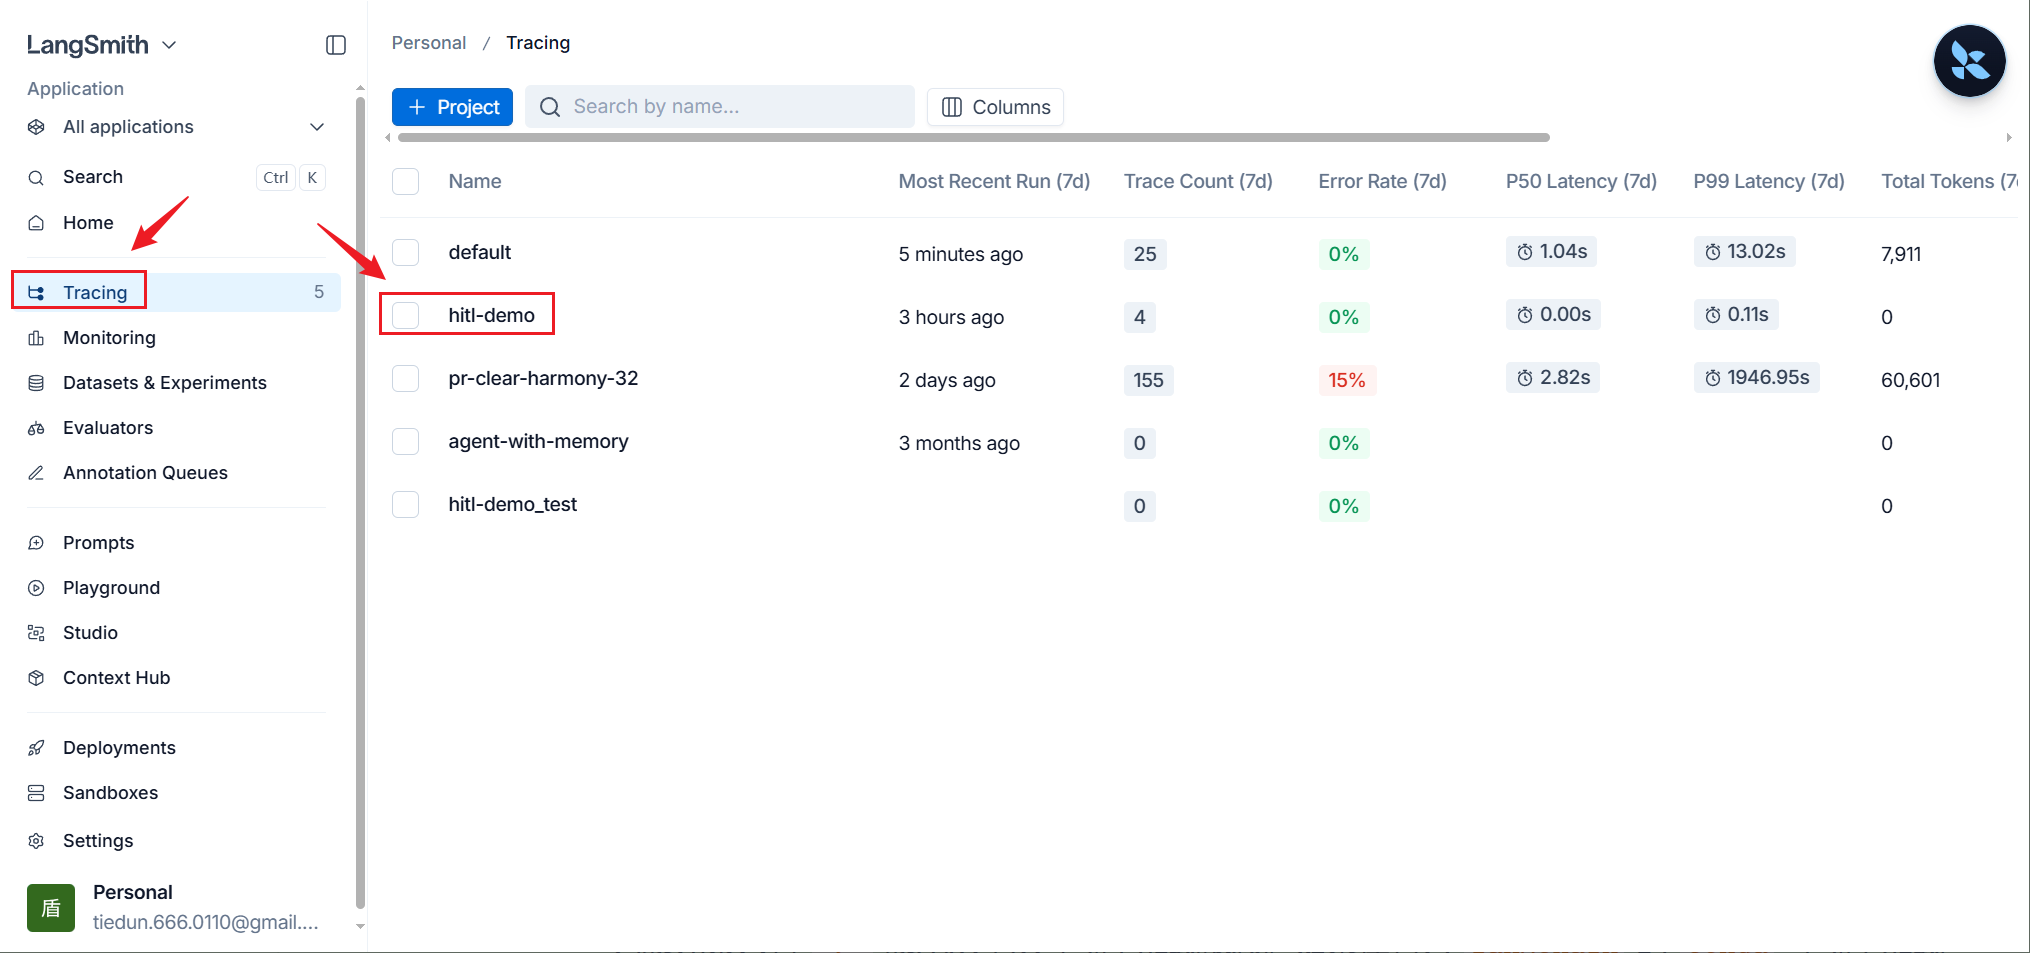

#### 9.1.2.2.4. `langgraph.json`

写入以下内容


```json
{
  "dependencies": ["."],
  "graphs": {
    "graph": "./src/agent.py:graph"
  },
  "env": ".env"
}
```


- **`dependencies`**：**`langgraph-cli`** 启动的本地服务的依赖项，接收类型为列表的值

  列表元素只有 **`"."`** 表示从本次环境中加载依赖。如果在名为 **`langchain`** 的 **`conda`** 环境中加载启动 **`LangGraph`** 本地服务，则会从该环境中加载依赖。

- **`graphs`**：计算图或 **`Agent`** 对象的映射

  这是个字典，其中每个键值对表示一条映射关系

  - **`Key`**：在 **`LangSmith Studio`** 中显示的应用名称
  - **`Value`**：相应的**应用实例**在项目源码中的路径
    - **`:`** 之前为应用实例所在的代码
    - **`:`** 之后为应用实例在代码中的**变量名**

- **`env`**：环境变量文件路径


## 9.1.3. 启动项目

在命令行执行 


```powershell
langgraph dev
```


该命令将会启动一个轻量的本地服务，用于测试。


```text
#报错
UnicodeDecodeError: 'gbk' codec can't decode byte 0xaf in position 60: illegal multibyte sequence
#原因
  agent.py 里有中文注释（# 姓名、# 年龄），在 Windows 下 Python 默认用 GBK 编码读取 .py 文件，遇到 GBK 无法解码的字节就报
  UnicodeDecodeError。
  
  解决方法

  在 PowerShell 中（你平时用的终端），执行前先设置环境变量：

conda activate langgraph
$env:PYTHONUTF8 = "1"
langgraph dev
  
  或者一行搞定：

conda activate langgraph; $env:PYTHONUTF8 = "1"; langgraph dev

  永久修复（推荐）

  在 conda 的 langgraph 环境中设置该变量，之后 activate 就自动生效：

conda activate langgraph
conda env config vars set PYTHONUTF8=1
conda deactivate
conda activate langgraph

  这样以后每次 langgraph dev 都不用再手动设置了。
```


**如下所示**


```powershell
(langgraph) PS C:\Users\Lenovo\OneDrive\文档\AI\langgraph\tutorials\hitl_demo> langgraph dev
```


**启动日志如下**

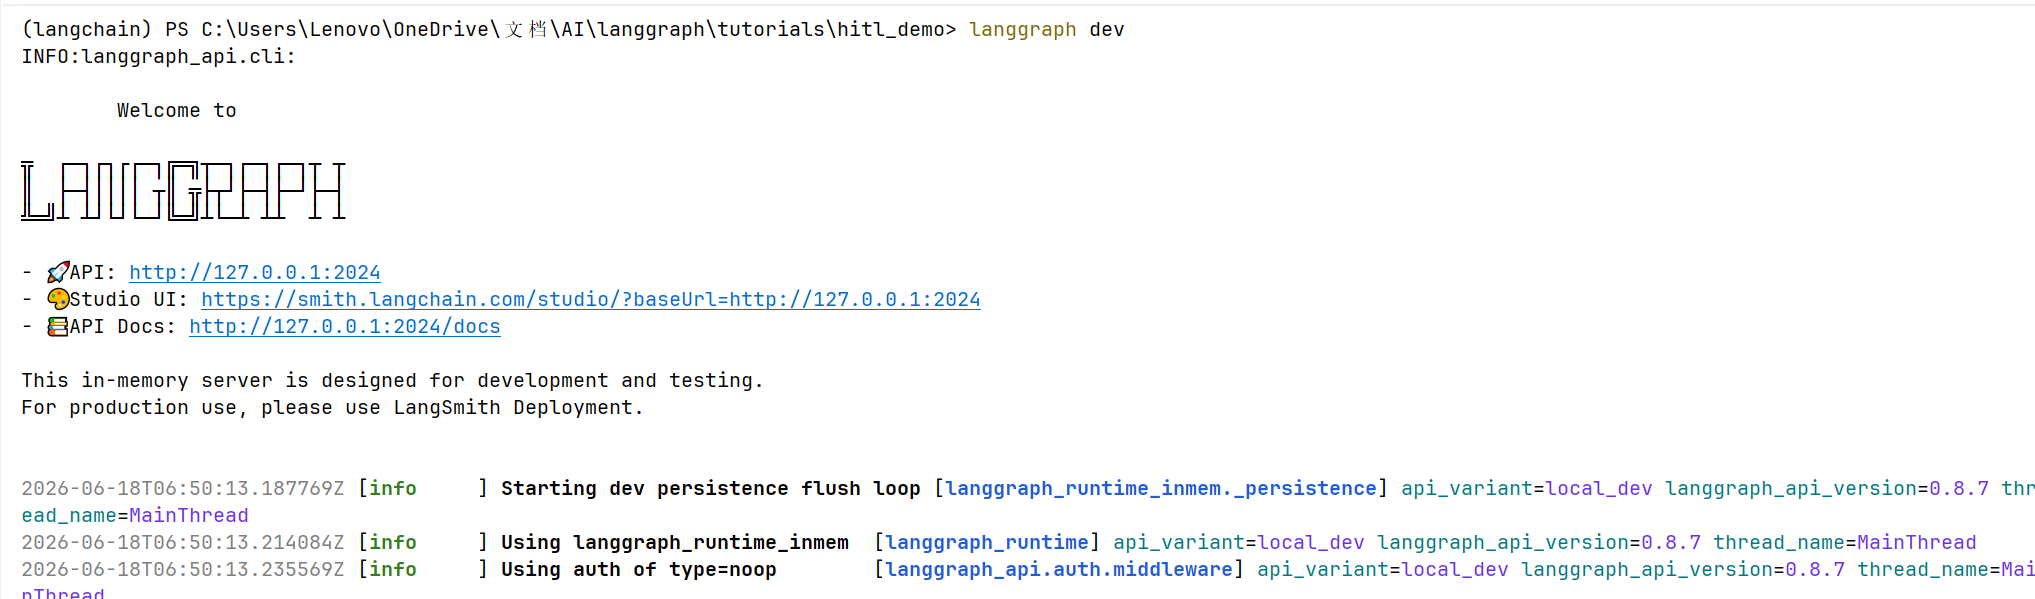

如果配置无误，执行命令后通常会自动跳转至

**`Studio UI`** 路径 

> https://smith.langchain.com/studio/?baseUrl=http://127.0.0.1:2024

如果没有跳转，在浏览器输入链接即可。

**页面如下所示**

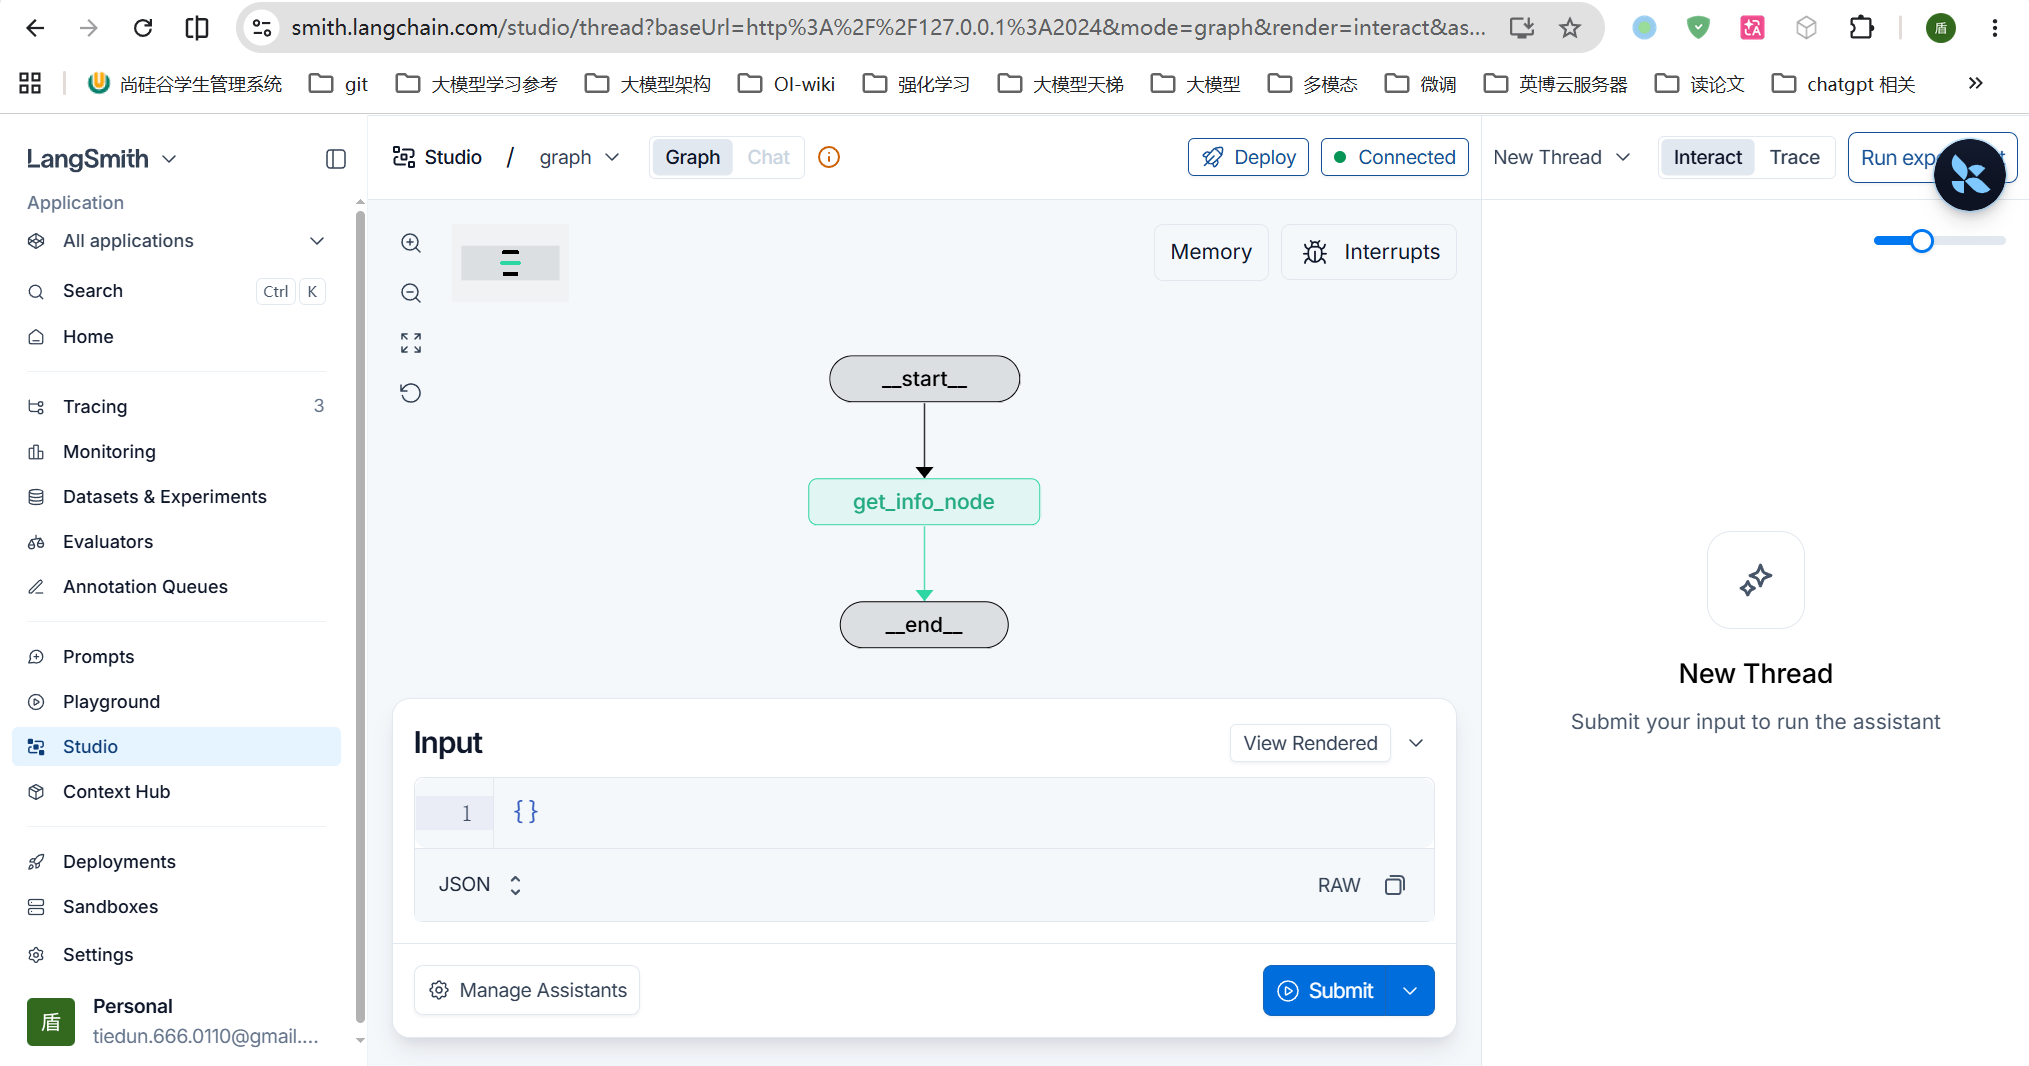

可以看到计算图的拓扑结构。


## 9.1.4. 调试

### 9.1.4.1. 首次调用

该应用不需要任何输入状态，**`Input`** 字典留空即可

点击 **`Submit`** 启动计算图

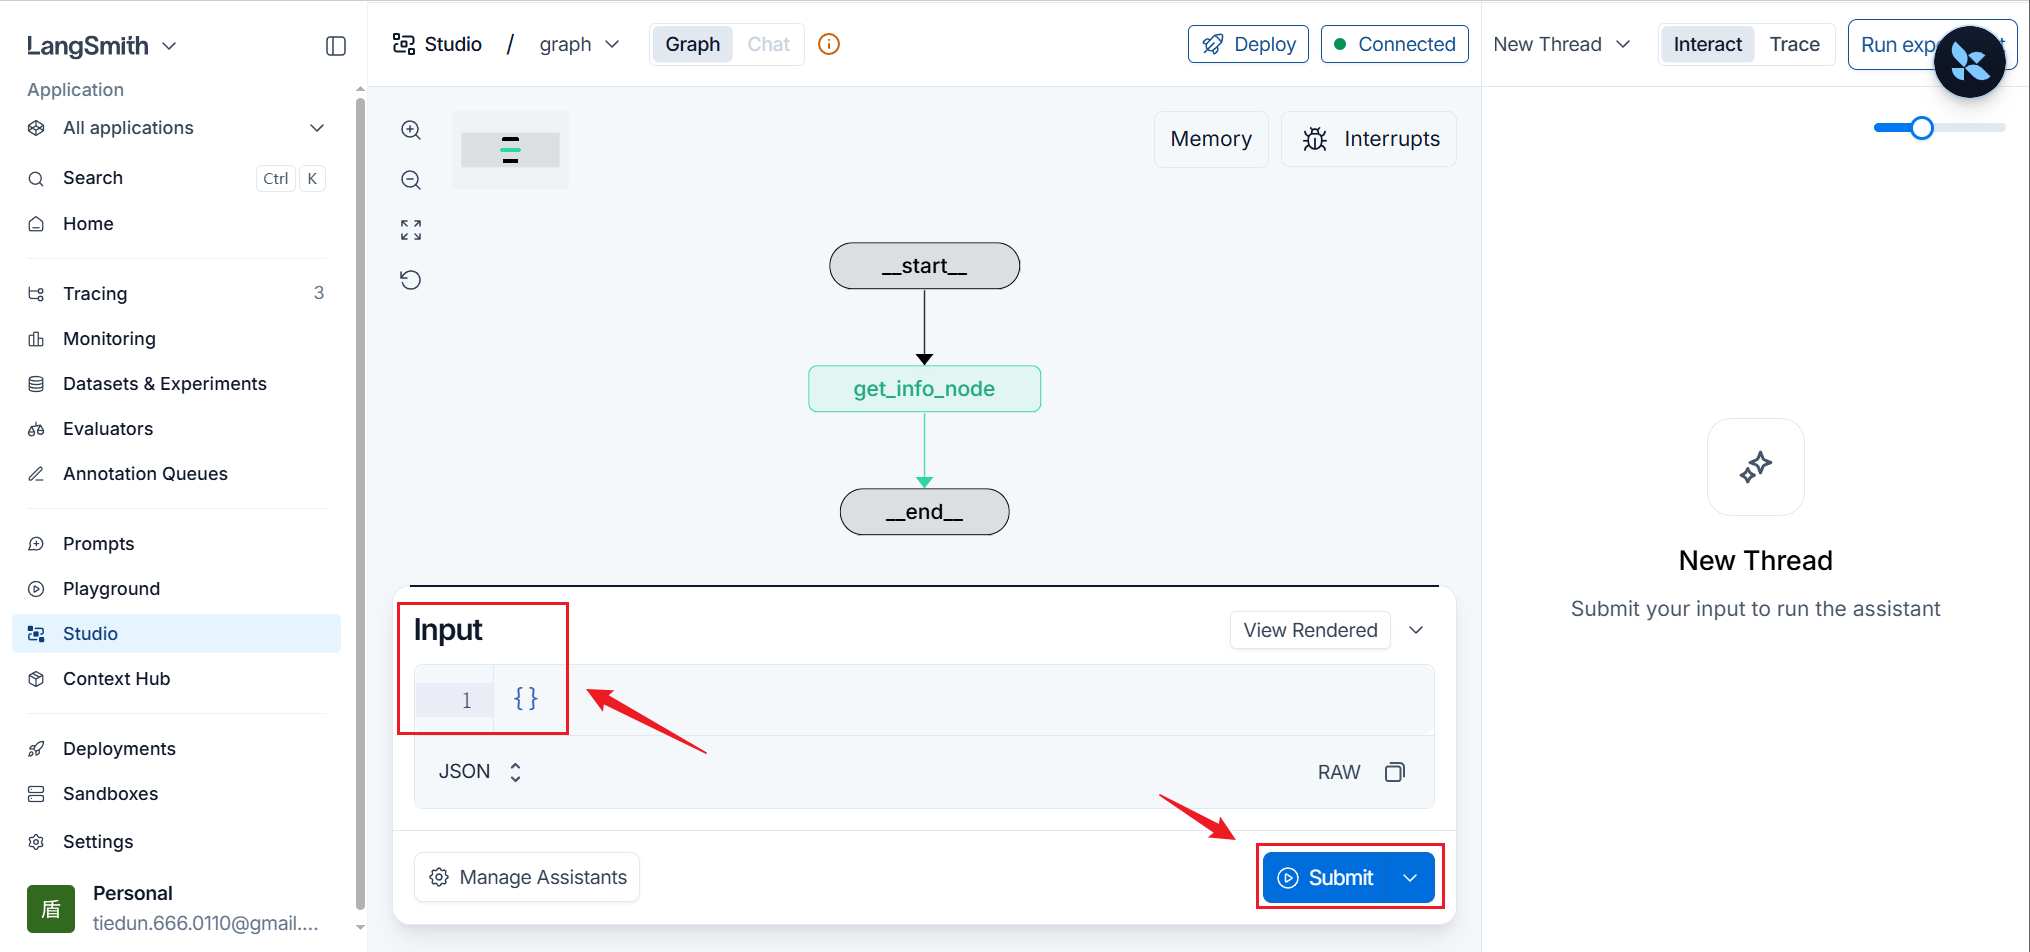

### 9.1.4.2. 第一次恢复运行

计算图触发第一个断点，只需要输入本地开发时传递给 **`Command(resume)`** 的值即可

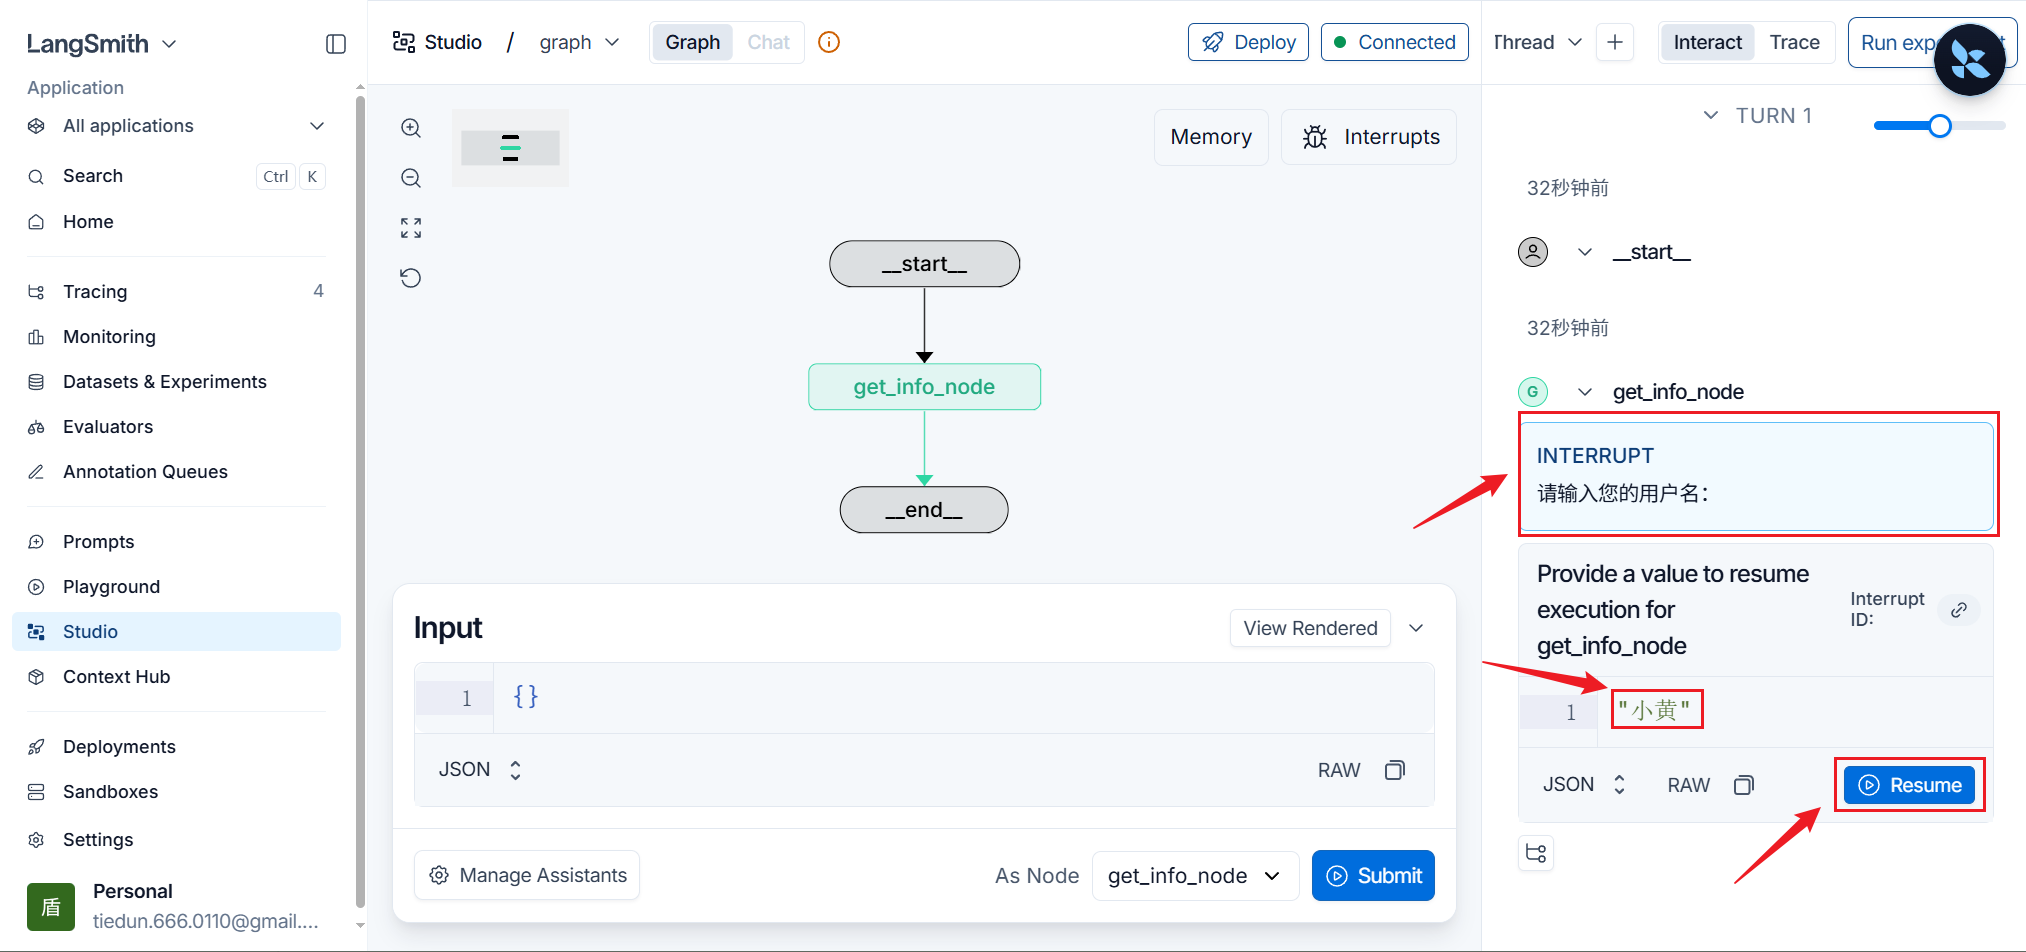

### 9.1.4.3. 第二次恢复运行

输入年龄

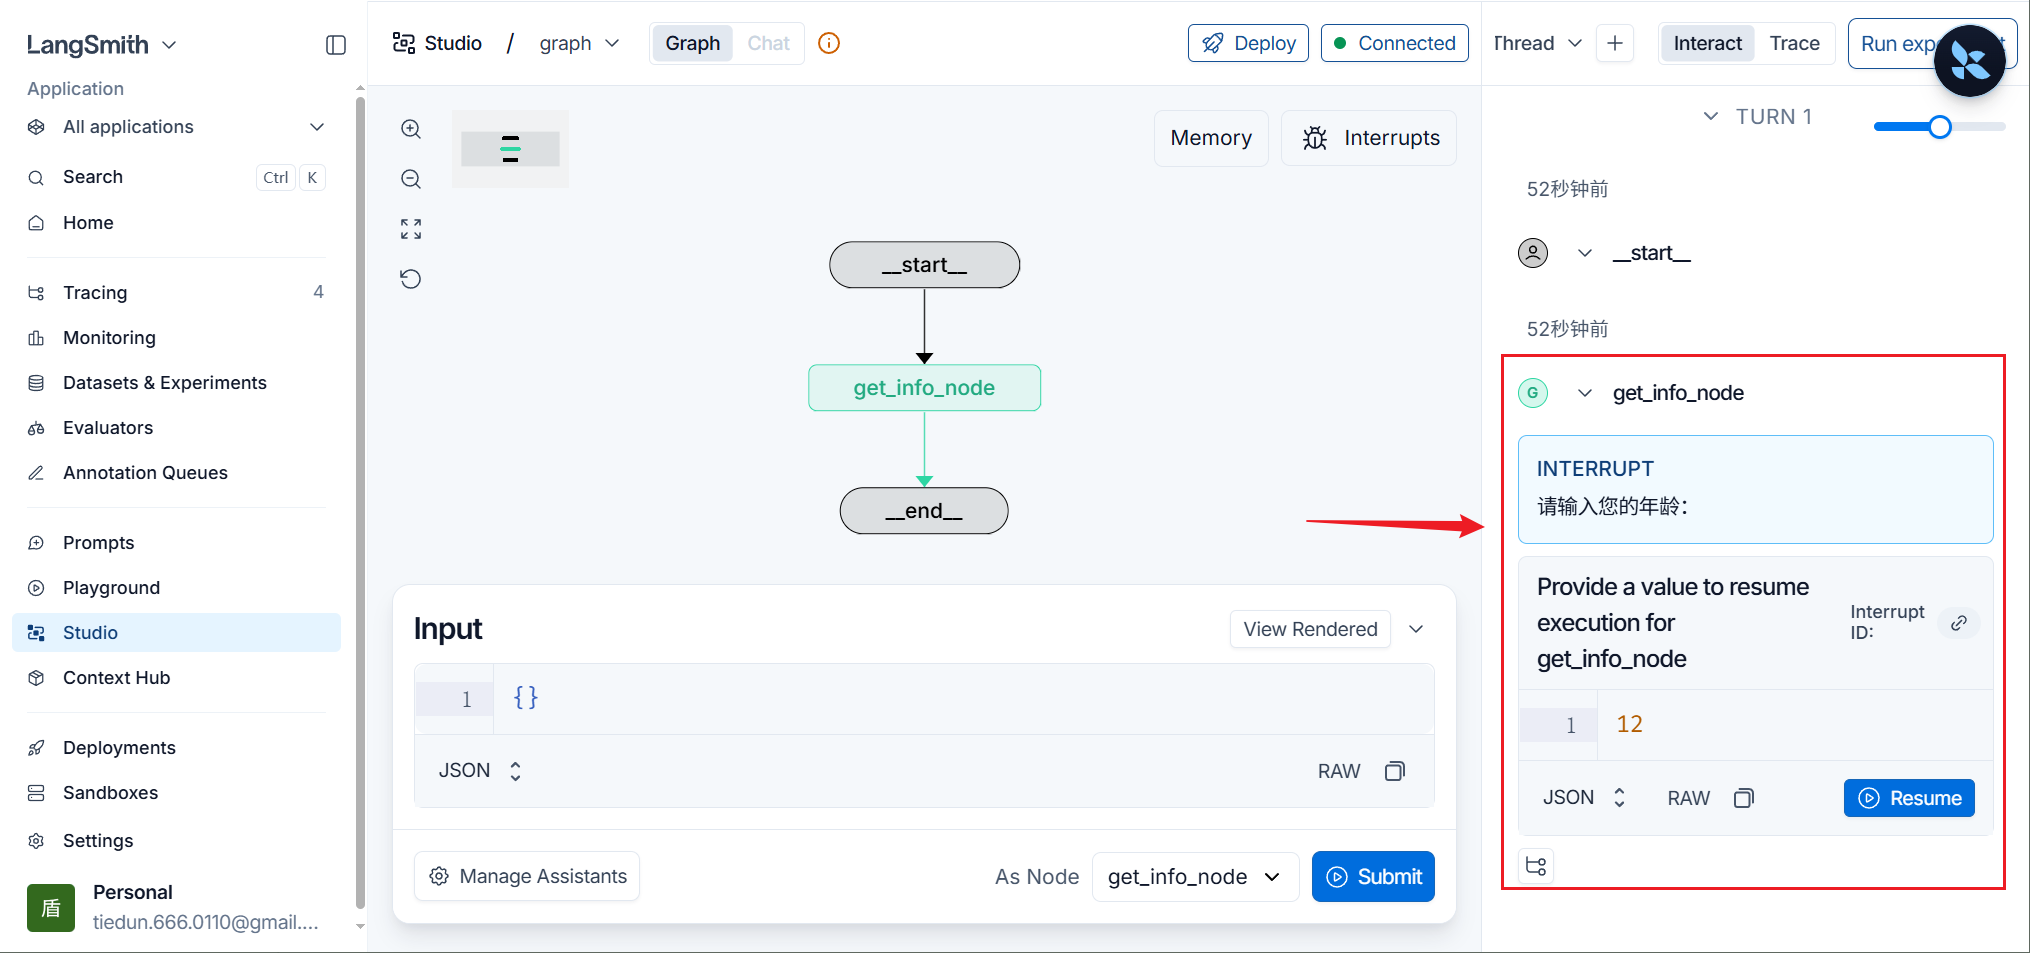

### 9.1.4.4. 第三次恢复运行

输入性别

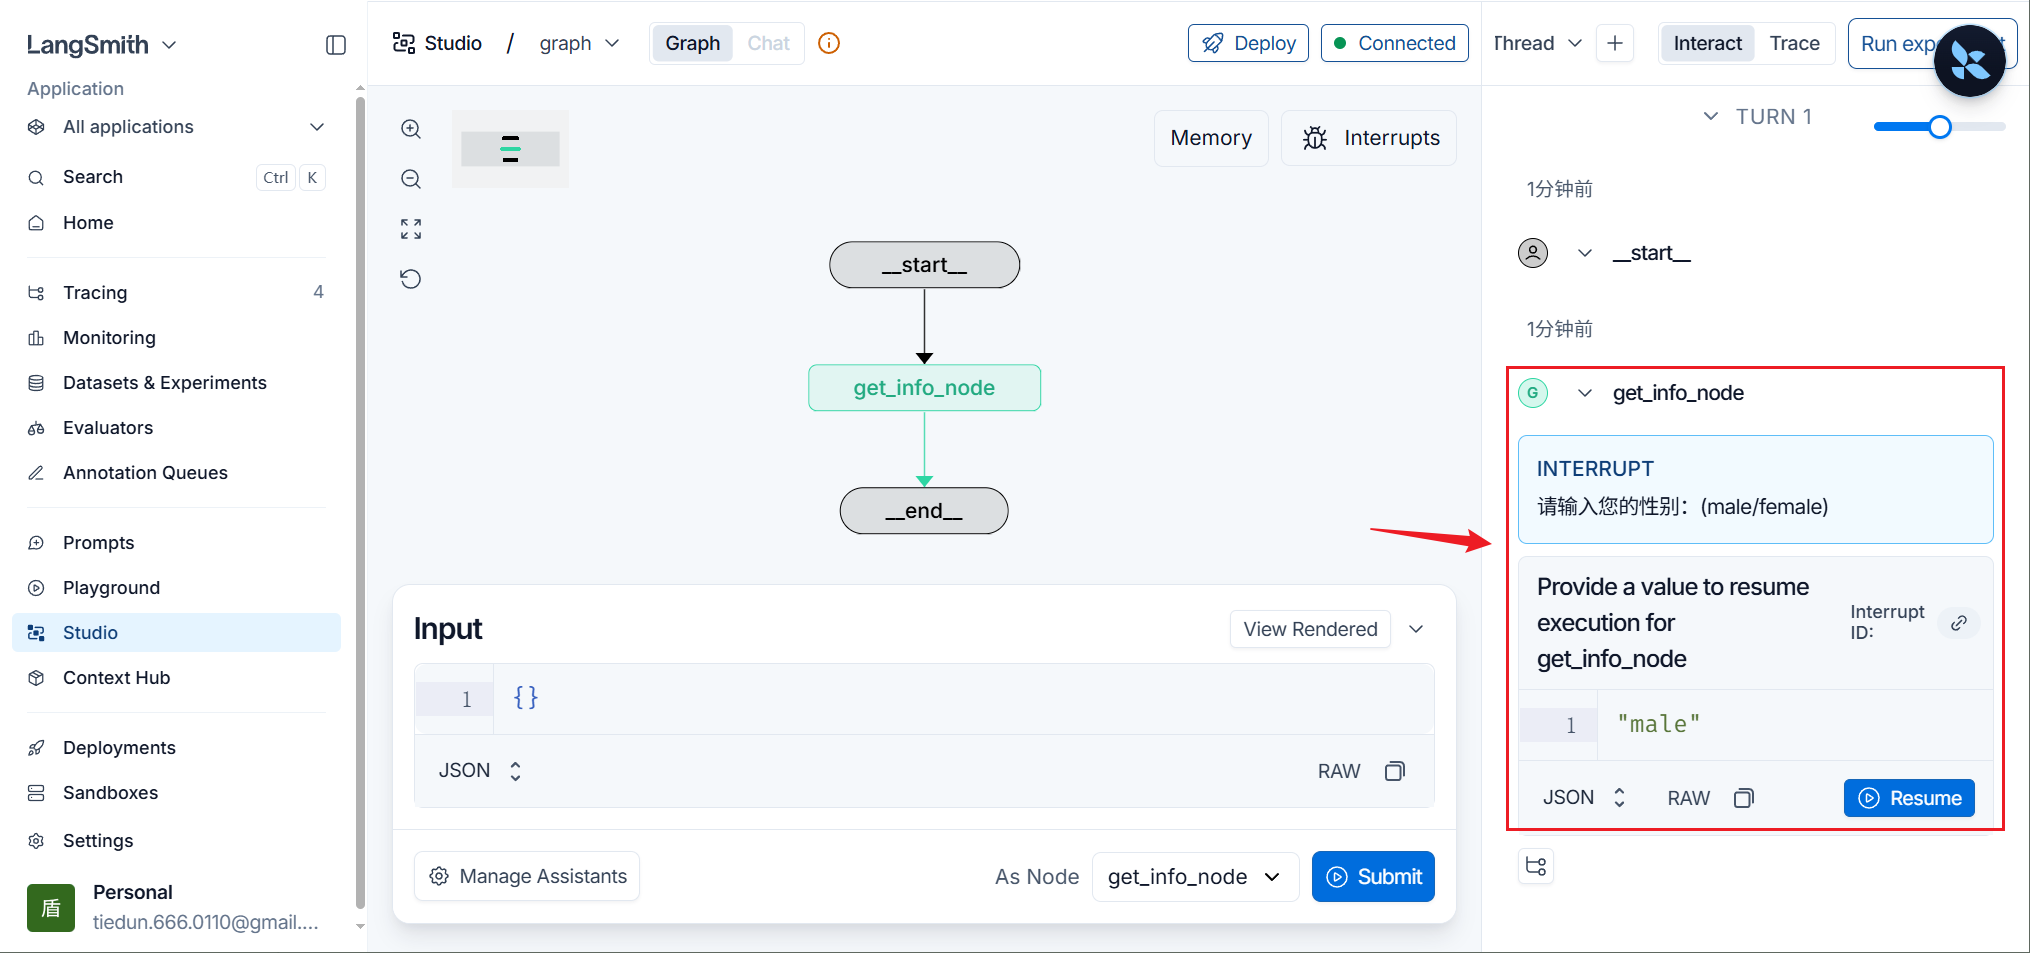

### 9.1.4.5. 最终结果

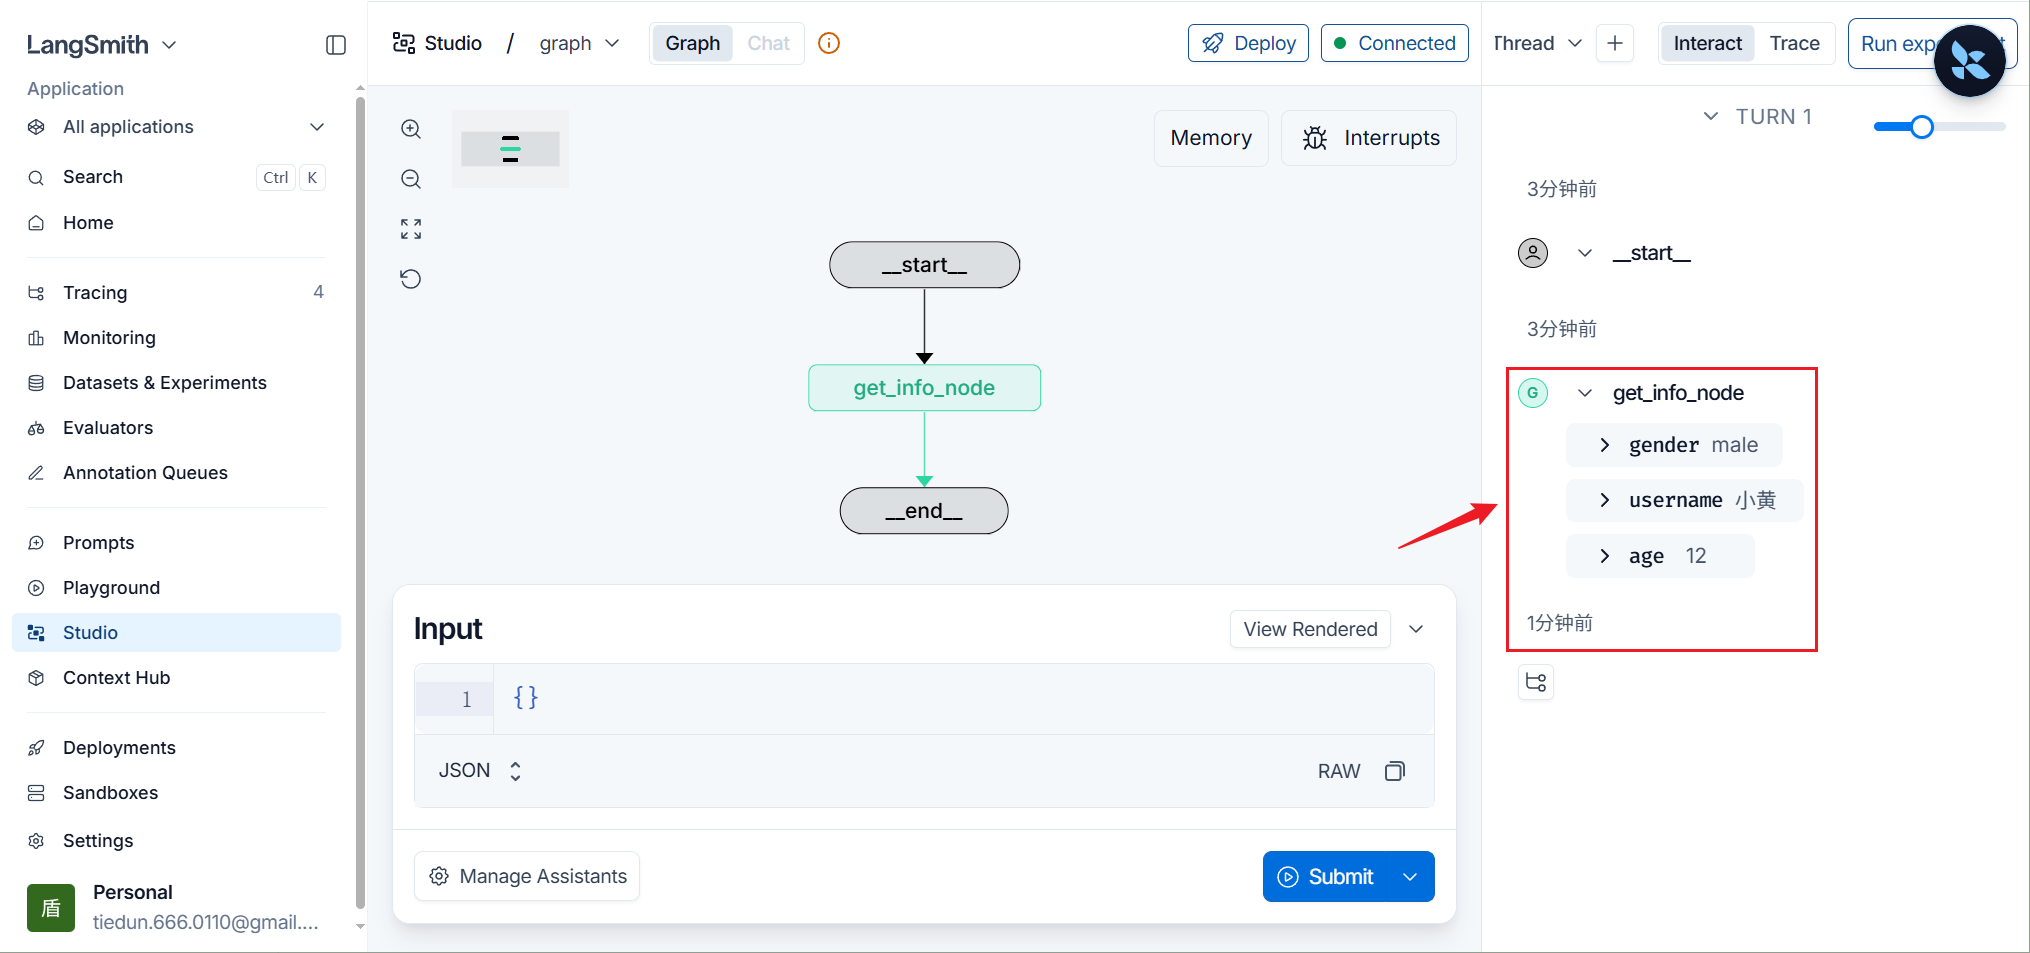


## 9.1.5. 调试时添加静态断点

我们可以在调试时添加静态断点

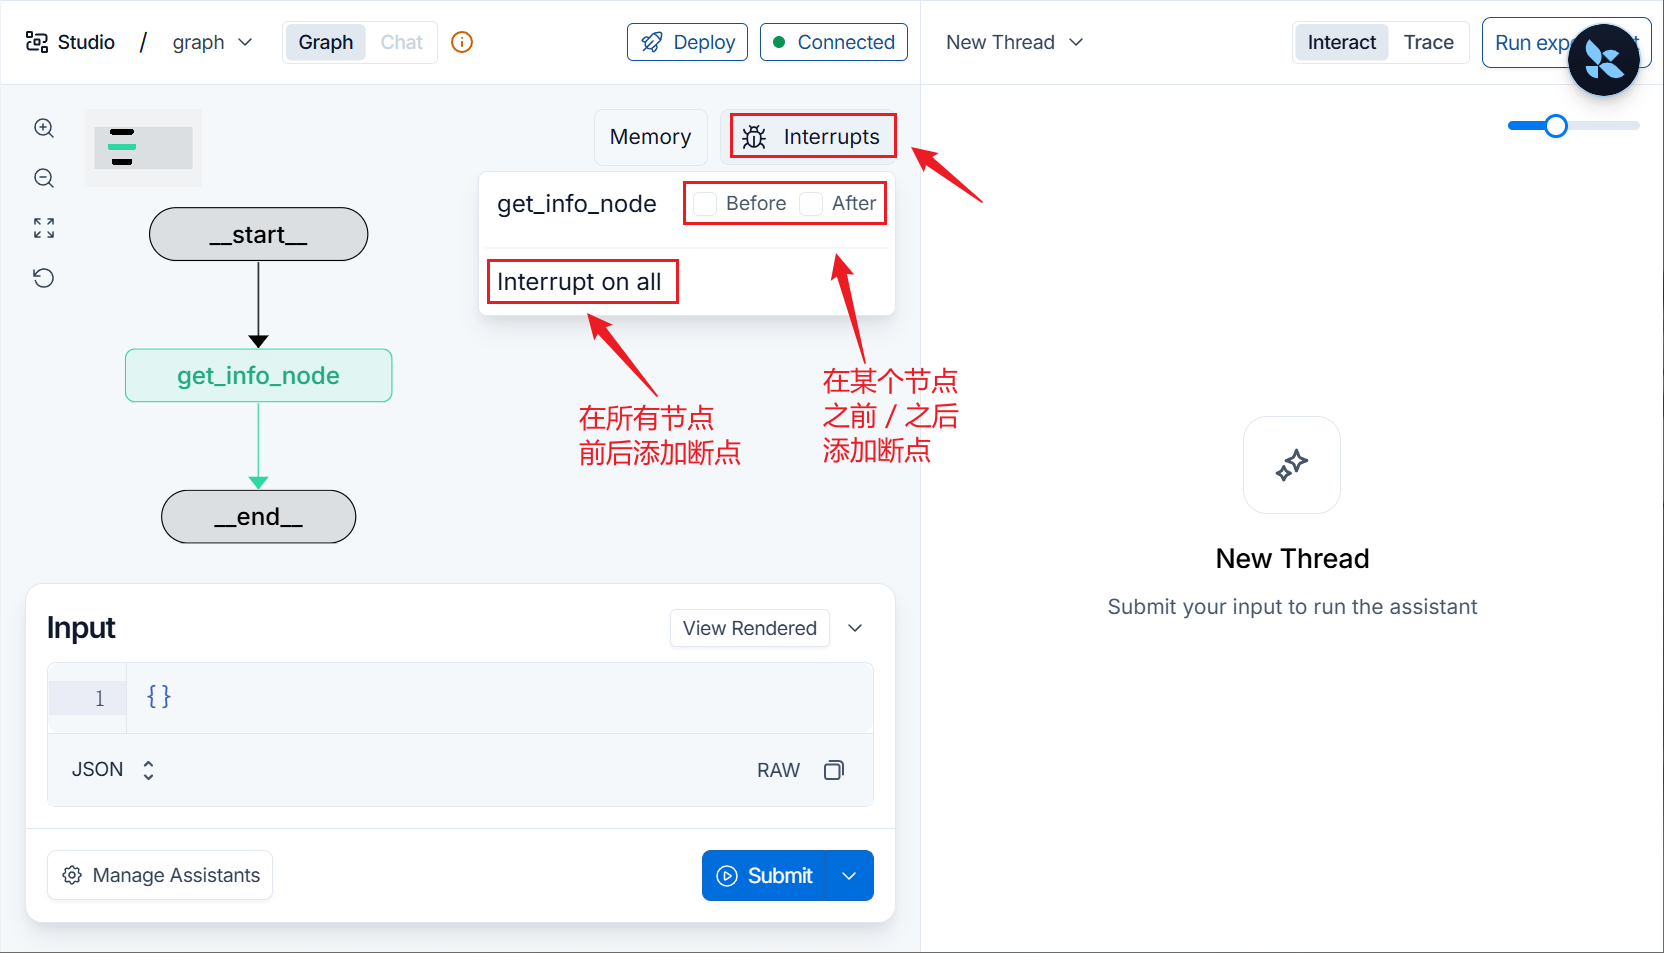

我们在 **`get_info_node`** 之前添加断点

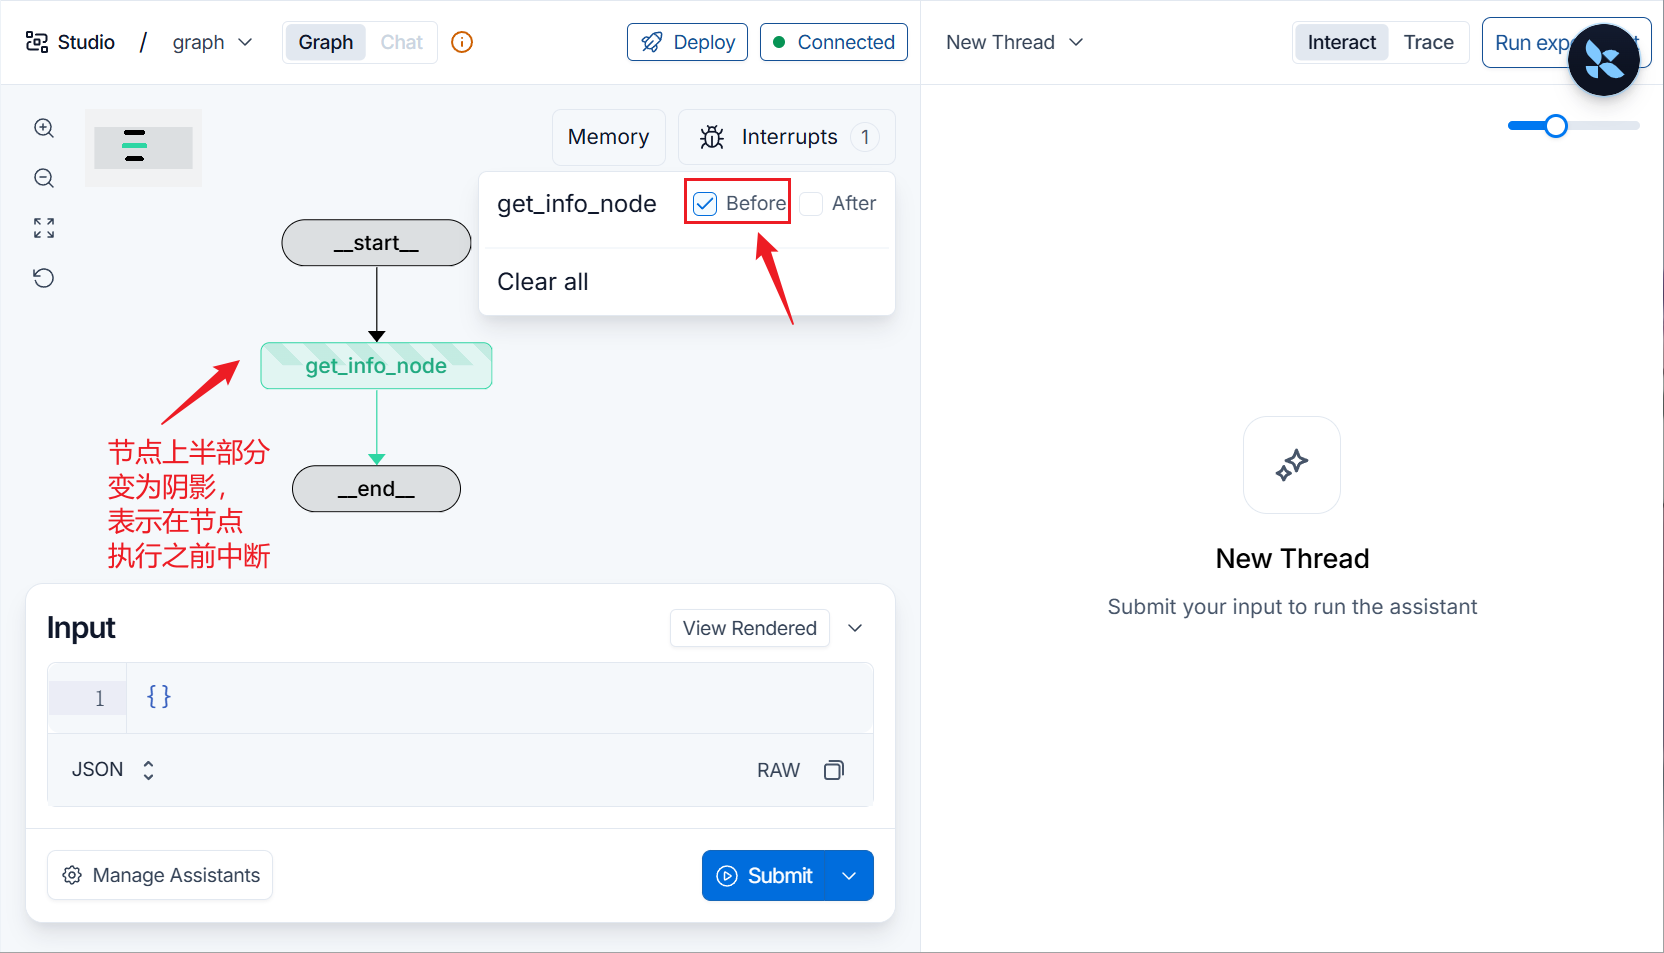

运行

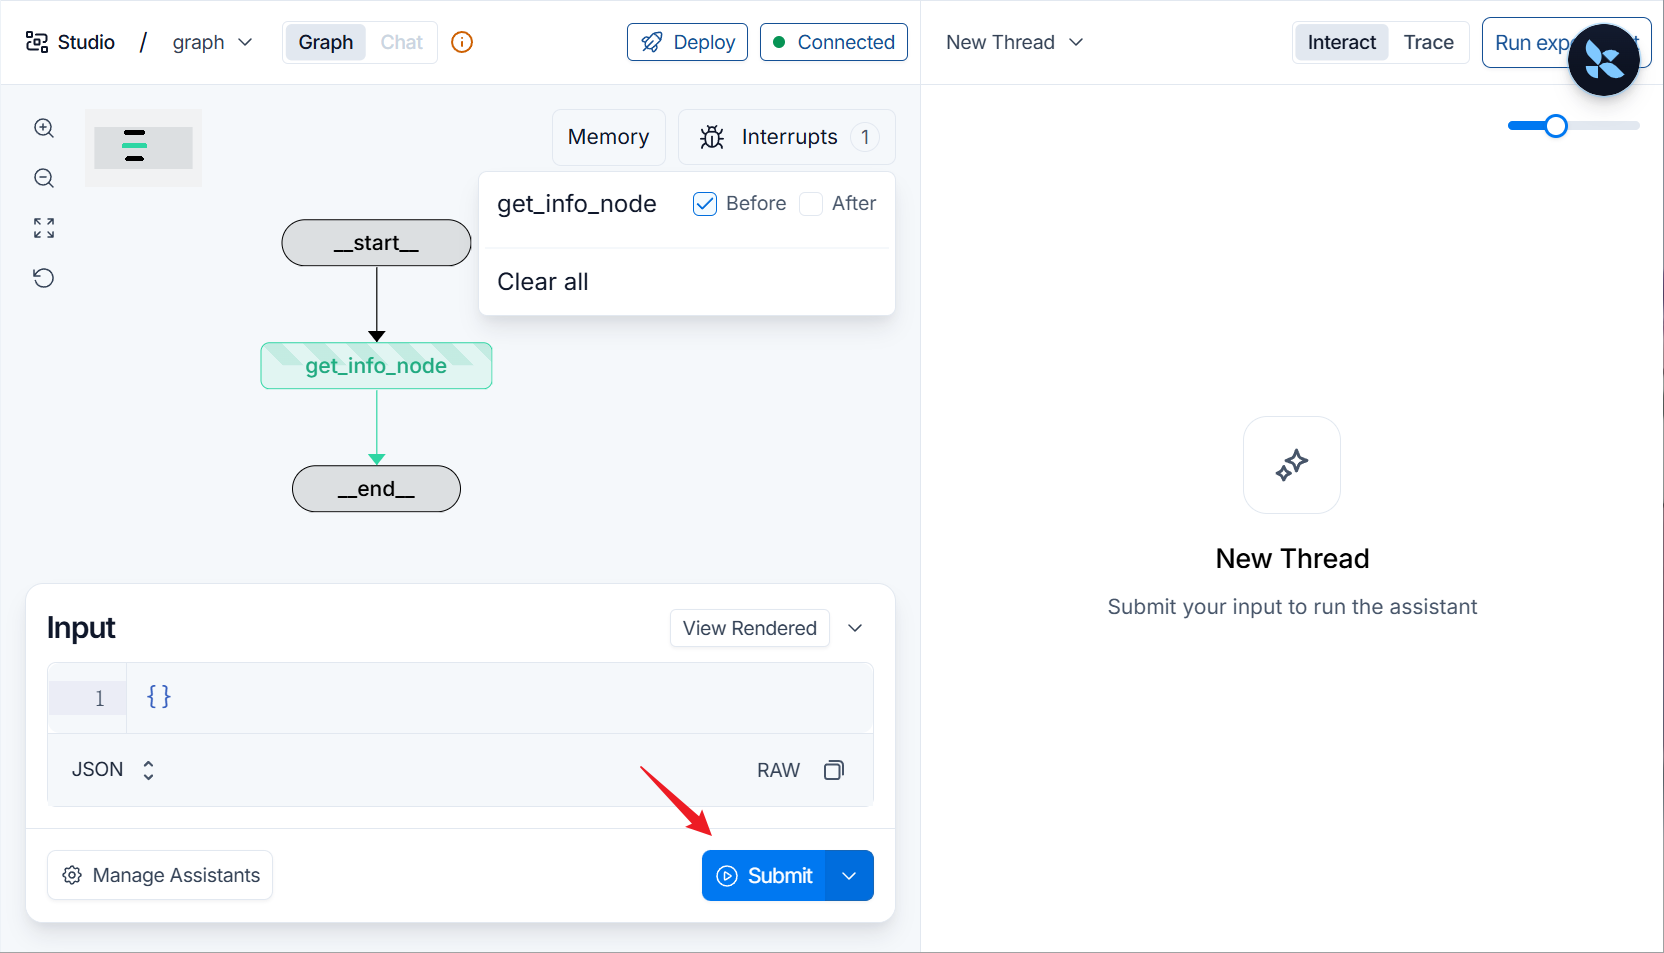

中断后继续

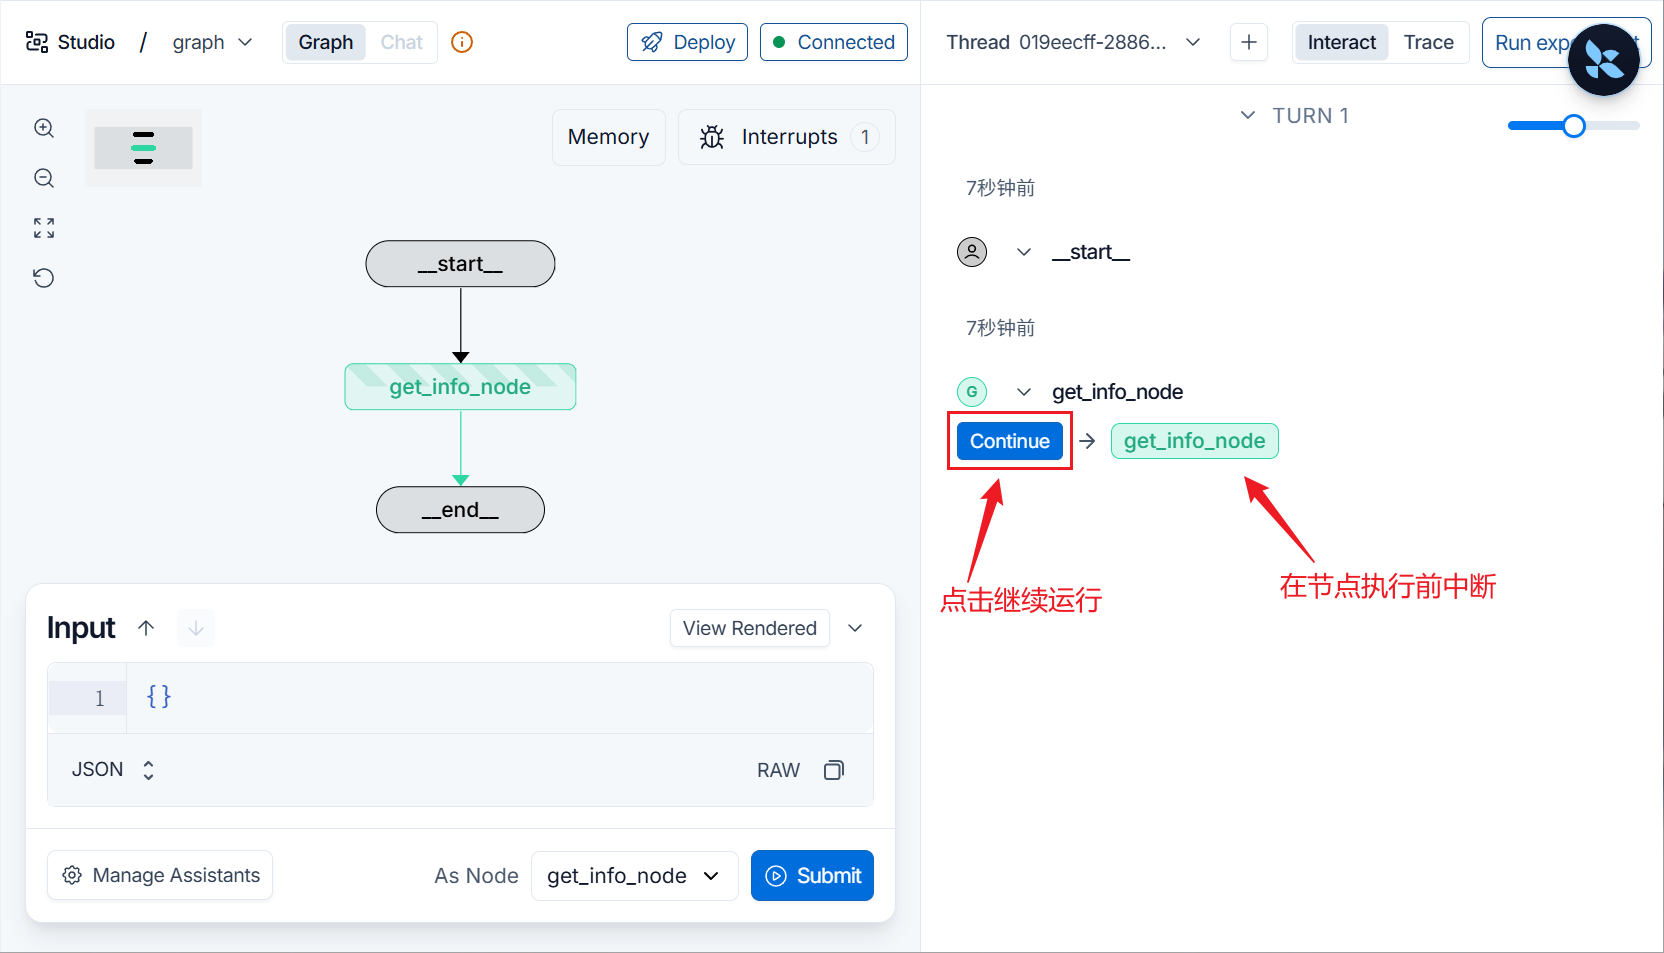

开始执行正常的节点计算逻辑

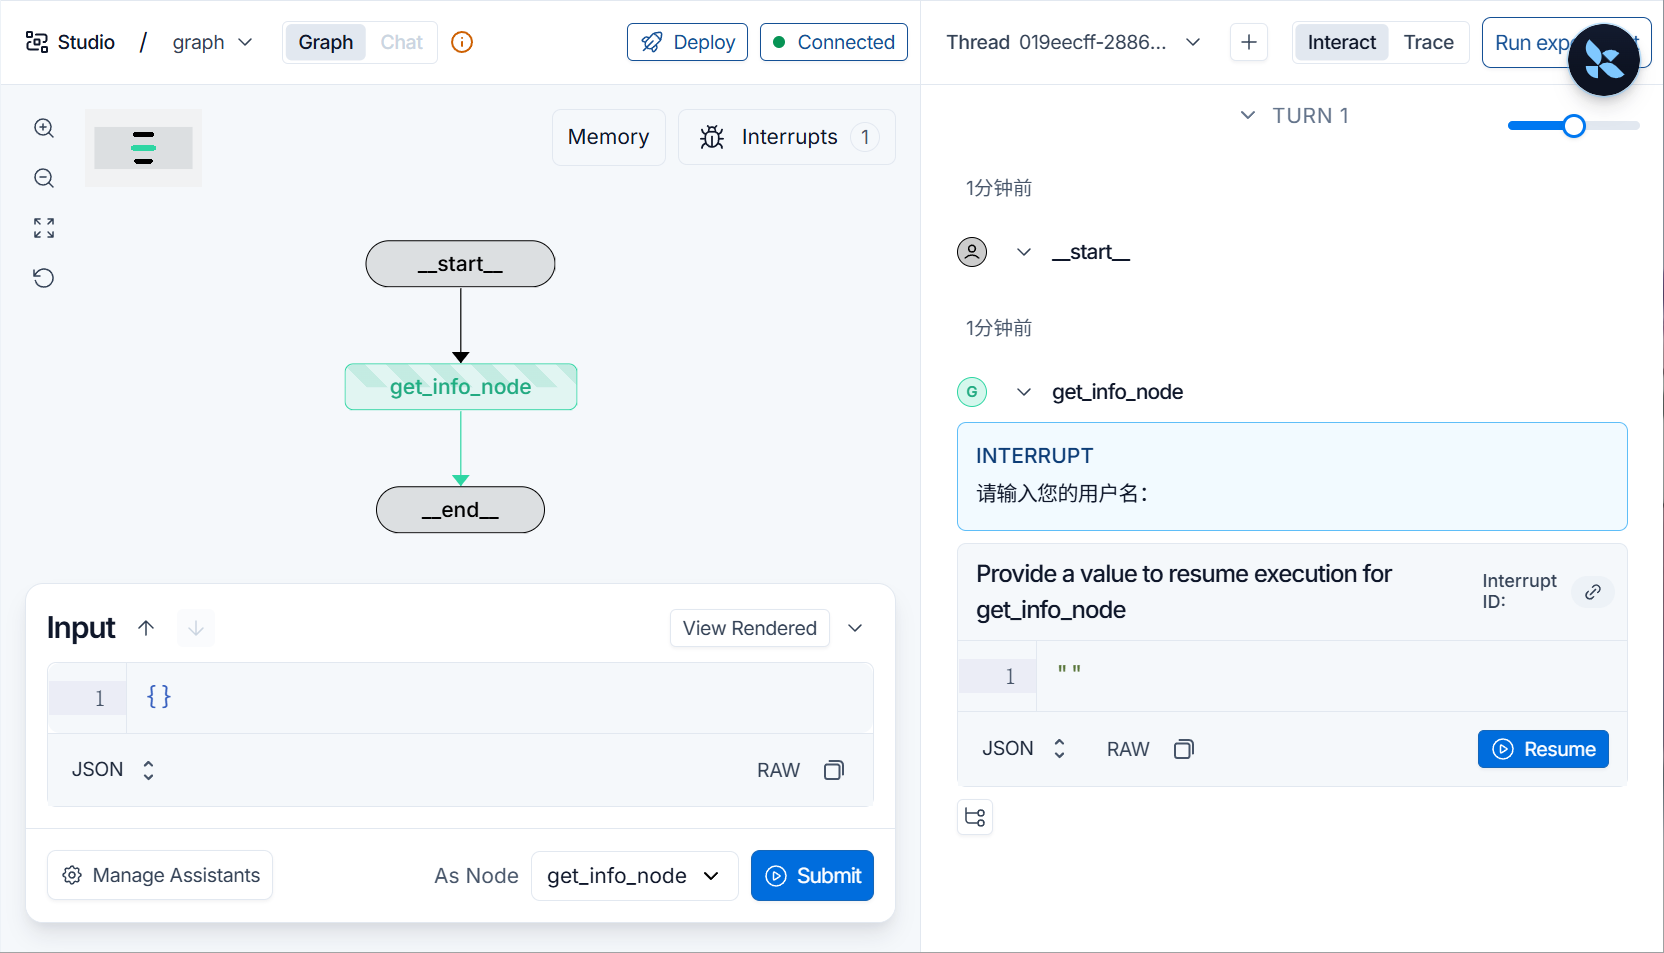


## 9.2. 本地部署并对接`AgentChatUI`

**`AgentChatUI`** 是 **`langchain-ai`** 旗下另一个开源框架，专为带有 **`messages`** 状态字段的计算图或 **`Agent`** 应用提供前端交互页面。

默认情况下，状态中的其它字段可以被后端正常处理，但是不会在前端展示。

**官方仓库地址如下**

> https://github.com/langchain-ai/agent-chat-ui

同样提供了开箱即用的**云服务**

> https://agentchat.vercel.app/


## 9.2.1.1. `chat_agent.py` 


在项目的 **`src`** 目录下新建 **`chat_agent.py`**，写入以下内容


```python
from typing import Literal

from langgraph.graph import MessagesState, StateGraph, START, END
from langgraph.types import interrupt

from langchain.messages import ToolMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    根据城市名称，查询当日天气。

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气很好"

tools = [get_weather]
tools_by_name = {
    current_tool.name: current_tool
    for current_tool in tools
}
model_with_tools = model.bind_tools(tools)

def llm_node(state: MessagesState) -> dict:
    response = model_with_tools.invoke(state["messages"])

    return {
        "messages": [response]
    }

def tool_node(state: MessagesState) -> dict:
    last_message = state["messages"][-1]
    tool_calls = last_message.tool_calls

    # 一次中断，提交所有待审批的工具调用
    resume_value = interrupt({
        "action_requests": [
            {
                "name": tool_call["name"],
                "args": tool_call["args"],
                "description": (
                    f"是否允许调用工具 {tool_call['name']}，"
                    f"参数为 {tool_call['args']}？"
                ),
            }
            for tool_call in tool_calls
        ],
        "review_configs": [
            {
                "action_name": tool_call["name"],
                "allowed_decisions": [
                    "approve",
                    "reject",
                    "edit",
                ],
            }
            for tool_call in tool_calls
        ],
    })

    decisions = resume_value.get("decisions", [])
    tool_messages = []

    for index, tool_call in enumerate(tool_calls):
        decision = (
            decisions[index]
            if index < len(decisions)
            else {"type": "reject"}
        )

        decision_type = decision.get("type")

        if decision_type == "approve":
            selected_tool = tools_by_name[tool_call["name"]]
            result = selected_tool.invoke(tool_call["args"])

        elif decision_type == "edit":
            edited_action = decision["edited_action"]
            edited_args = edited_action["args"]

            selected_tool = tools_by_name[tool_call["name"]]
            result = selected_tool.invoke(edited_args)

        else:
            result = decision.get(
                "message",
                "用户拒绝调用该工具",
            )

        tool_messages.append(
            ToolMessage(
                content=str(result),
                tool_call_id=tool_call["id"],
            )
        )

    return {
        "messages": tool_messages
    }


def router(
    state: MessagesState,
) -> Literal["tool_node", END]:
    last_message = state["messages"][-1]

    if last_message.tool_calls:
        return "tool_node"

    return END


builder = StateGraph(state_schema=MessagesState)

builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)

builder.add_edge(START, "llm_node")

builder.add_conditional_edges(
    "llm_node",
    router,
    ["tool_node", END],
)

builder.add_edge("tool_node", "llm_node")

chat_graph = builder.compile()
```


此处返回的中断信息，遵循 **`AgentChatUI`** 定义的 **`HITL`** 协议，遵循此协议，则前端可以正确渲染中断信息，前端期望的中断信息格式如下：


```json
{
    "action_requests": [
        {
            "name": "get_weather",
            "args": {
                "city": "杭州"
            },
            "description": "是否允许查询杭州天气？"
        }
    ],
    "review_configs": [
        {
            "action_name": "get_weather",
            "allowed_decisions": [
                "approve",
                "reject",
                "edit"
            ]
        }
    ]
}
```


当中断发生时，前端会将中断信息渲染在对话框中，根据用户操作的不同，后端拿到的反馈数据样式如下

- **`approve`**：


```json
  {
      "decisions": [
          {
              "type": "approve"
          }
      ]
  }
```


- **`reject`**：


```text
  {
      "decisions": [
          {
              "type": "reject",
              "message": "不允许执行该操作"
          }
      ]
  }

- **`edit`**：
```

  {
      "decisions": [
          {
              "type": "edit",
              "edited_action": {
                  "name": "get_weather",
                  "args": {
                      "city": "上海"
                  }
              }
          }
      ]
  }


## 9.2.1.2. 更改`langgraph.json`

在 **`graphs`** 中新增条目，如下


```json
{
  "dependencies": ["."],
  "graphs": {
    "graph": "./src/agent.py:graph",
    "chat_graph": "./src/chat_agent.py:chat_graph"
  },
  "env": ".env"
}
```


## 9.2.2. 对接`AgentChatUI`

### 9.2.2.1. 重启本地服务

### 9.2.2.2. 访问云服务

在官方云服务入口页面填入需要的信息

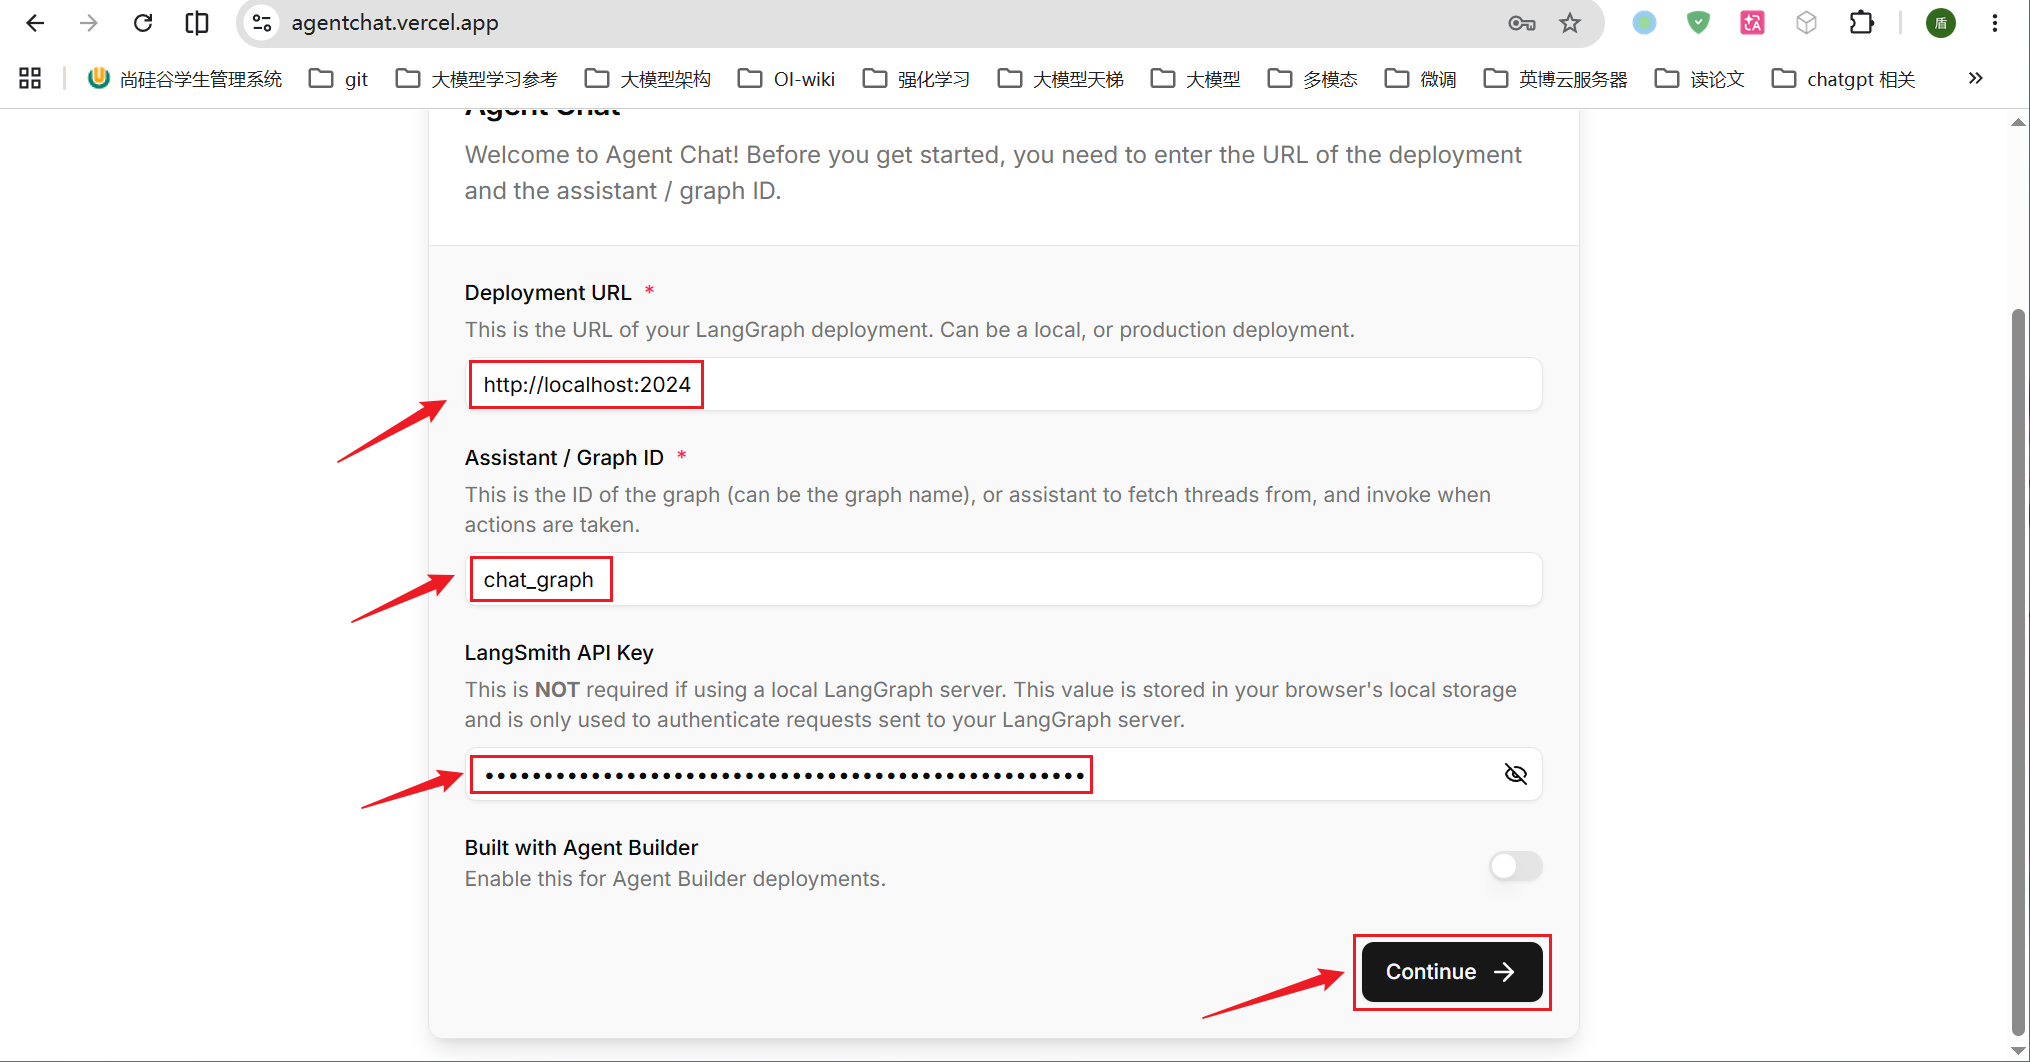

- **`Deployment URL`**：本地服务 **`URL`**
- **`Assistant / Graph ID`**：配置文件中声明的应用名称
- **`LangSmith API Key`**：略

点击 **`Continue`**，如果配置正确，则跳转至以下页面

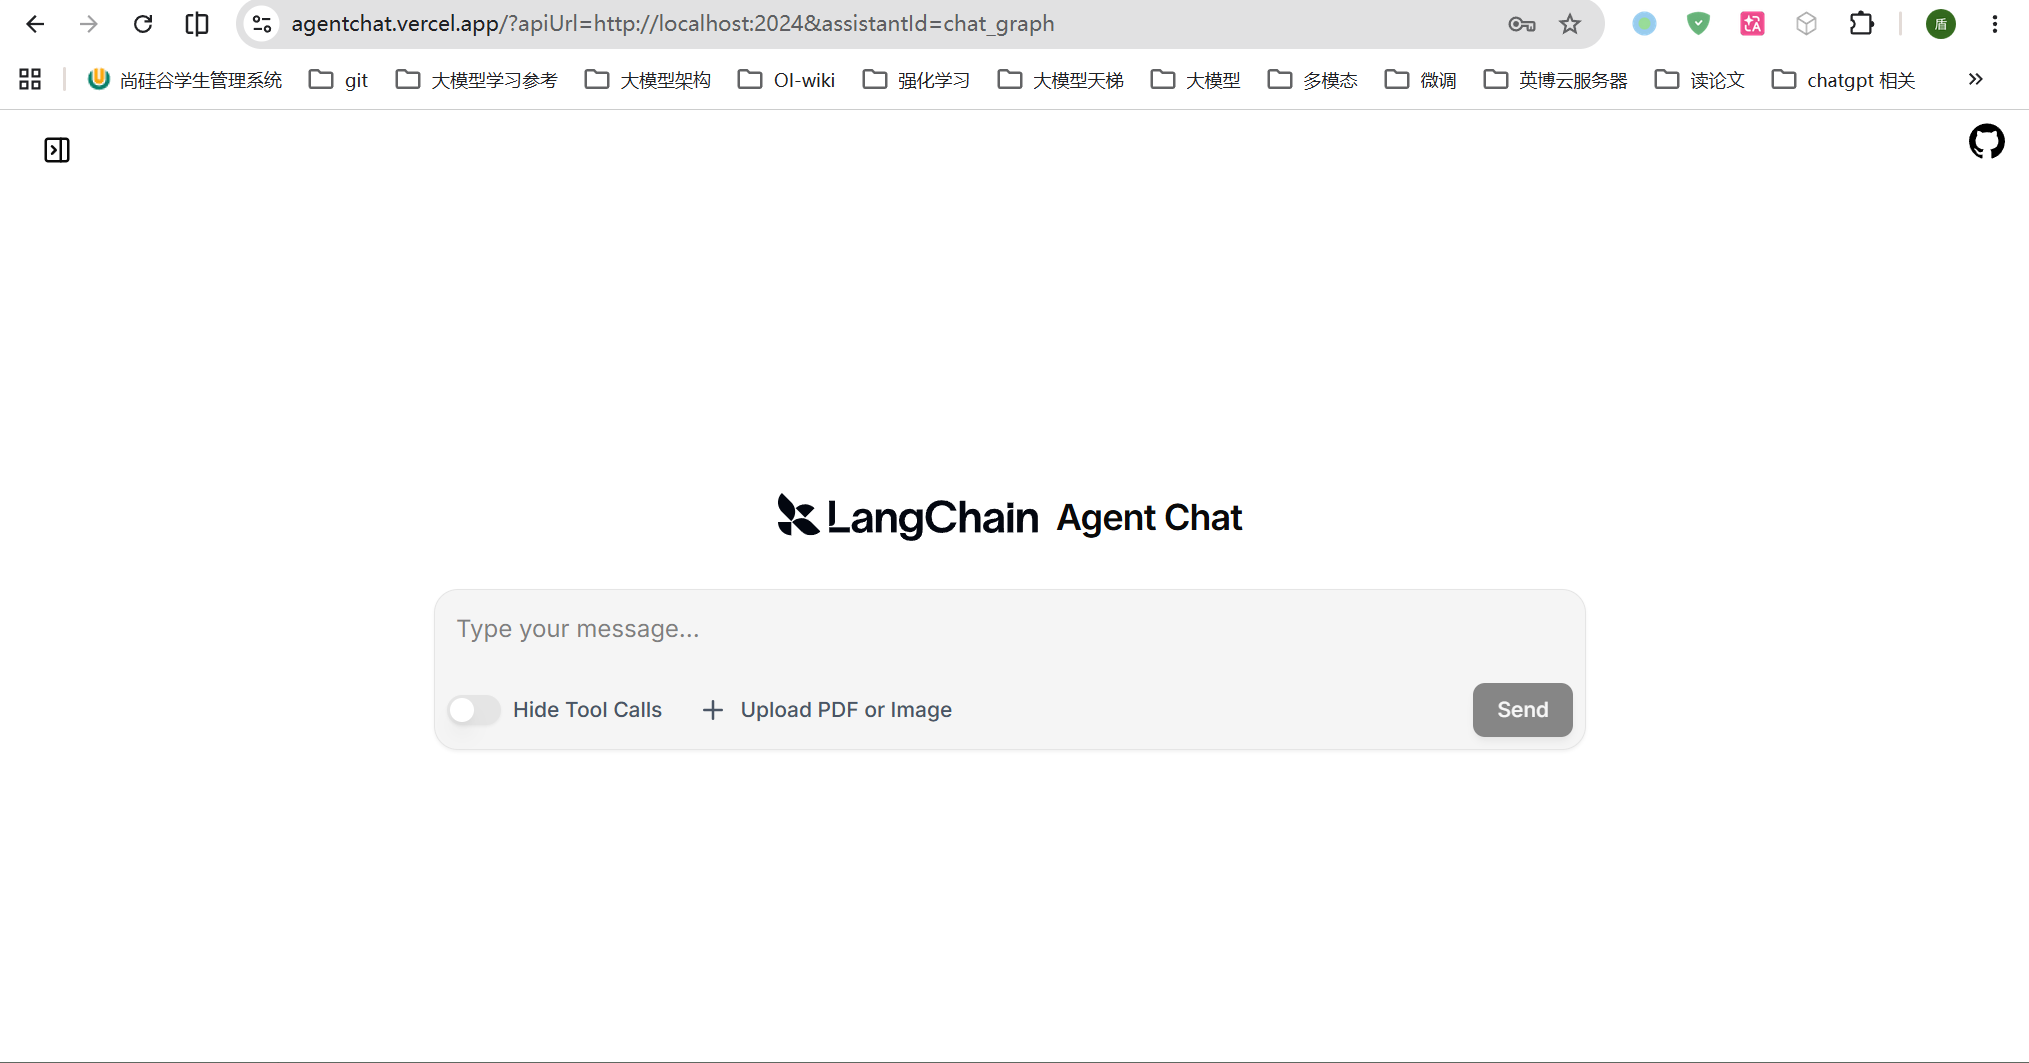


## 9.2.3. 测试

### 9.2.3.1. 对话

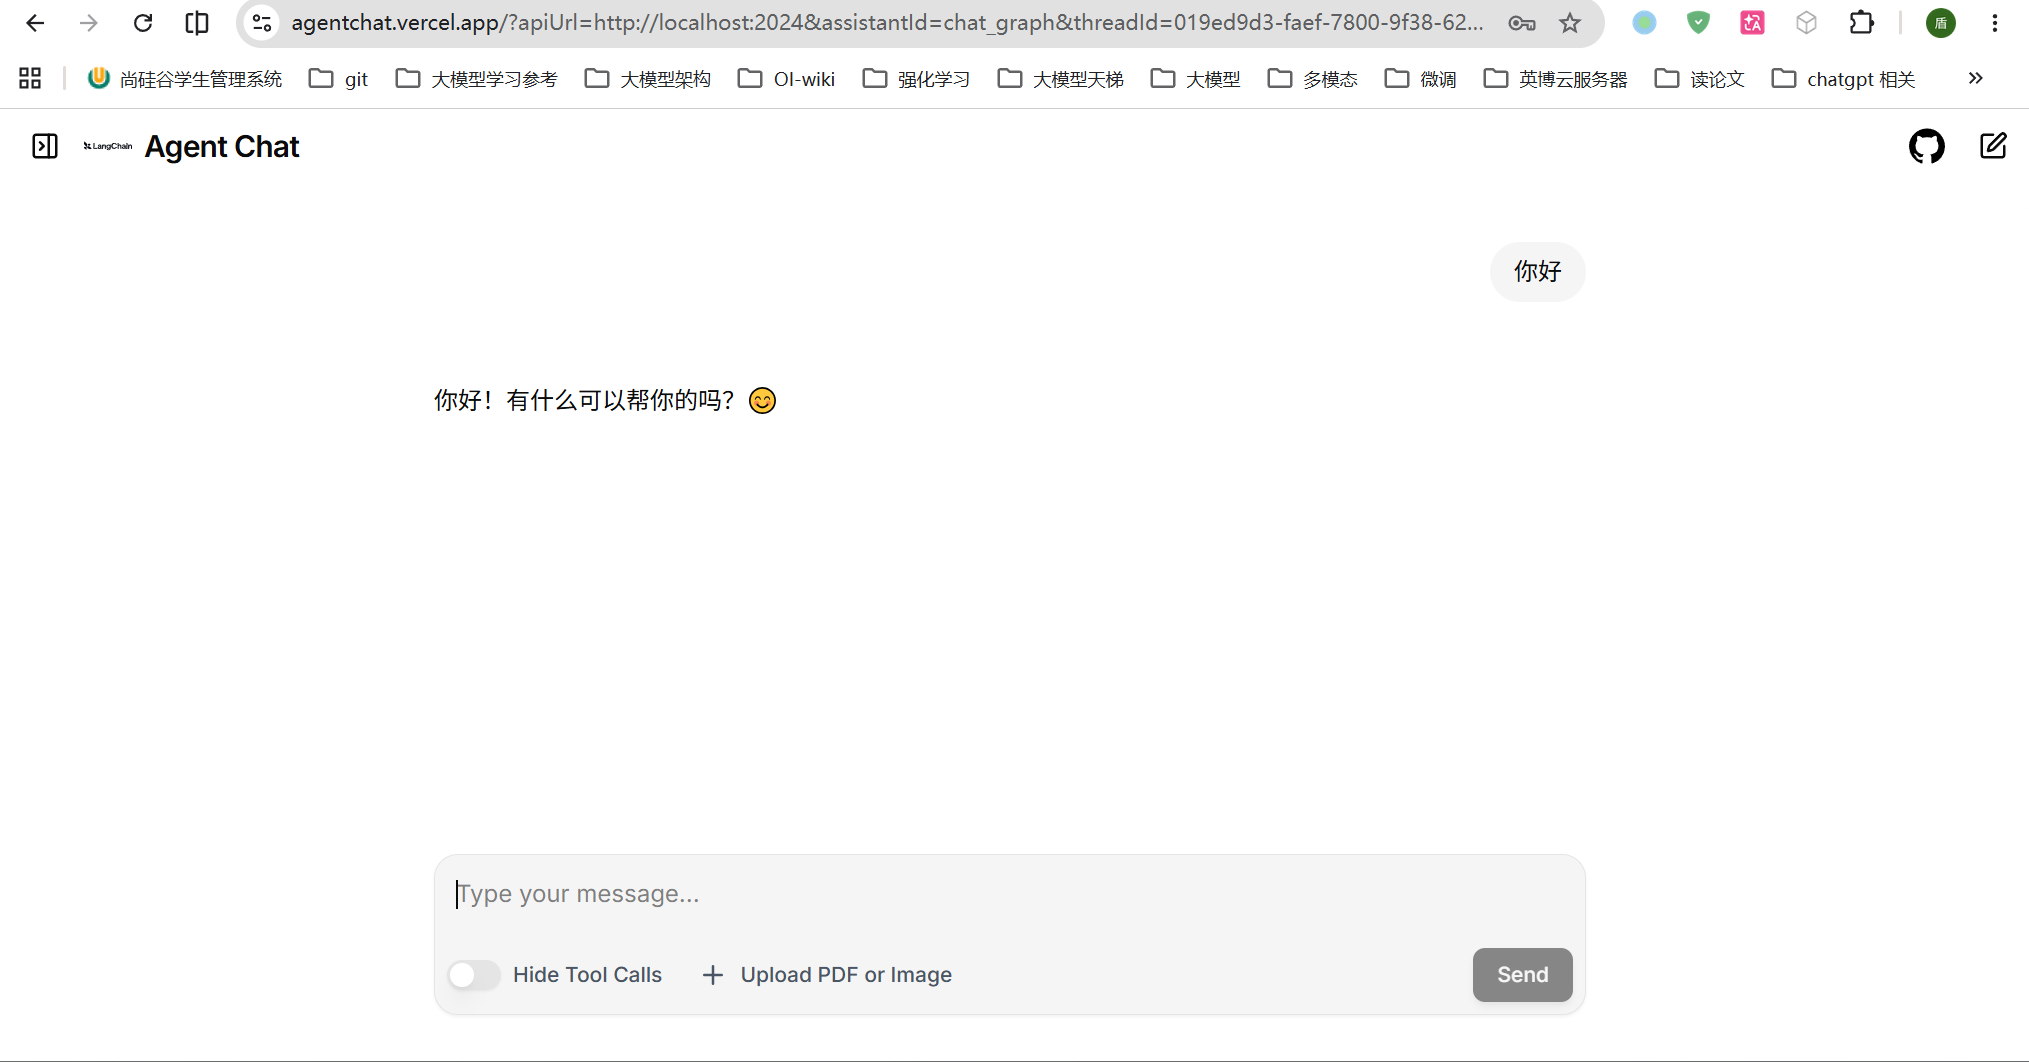

### 9.2.3.2. 工具调用

在工具节点添加了 **`HITL`** 机制，所以调用工具会触发中断

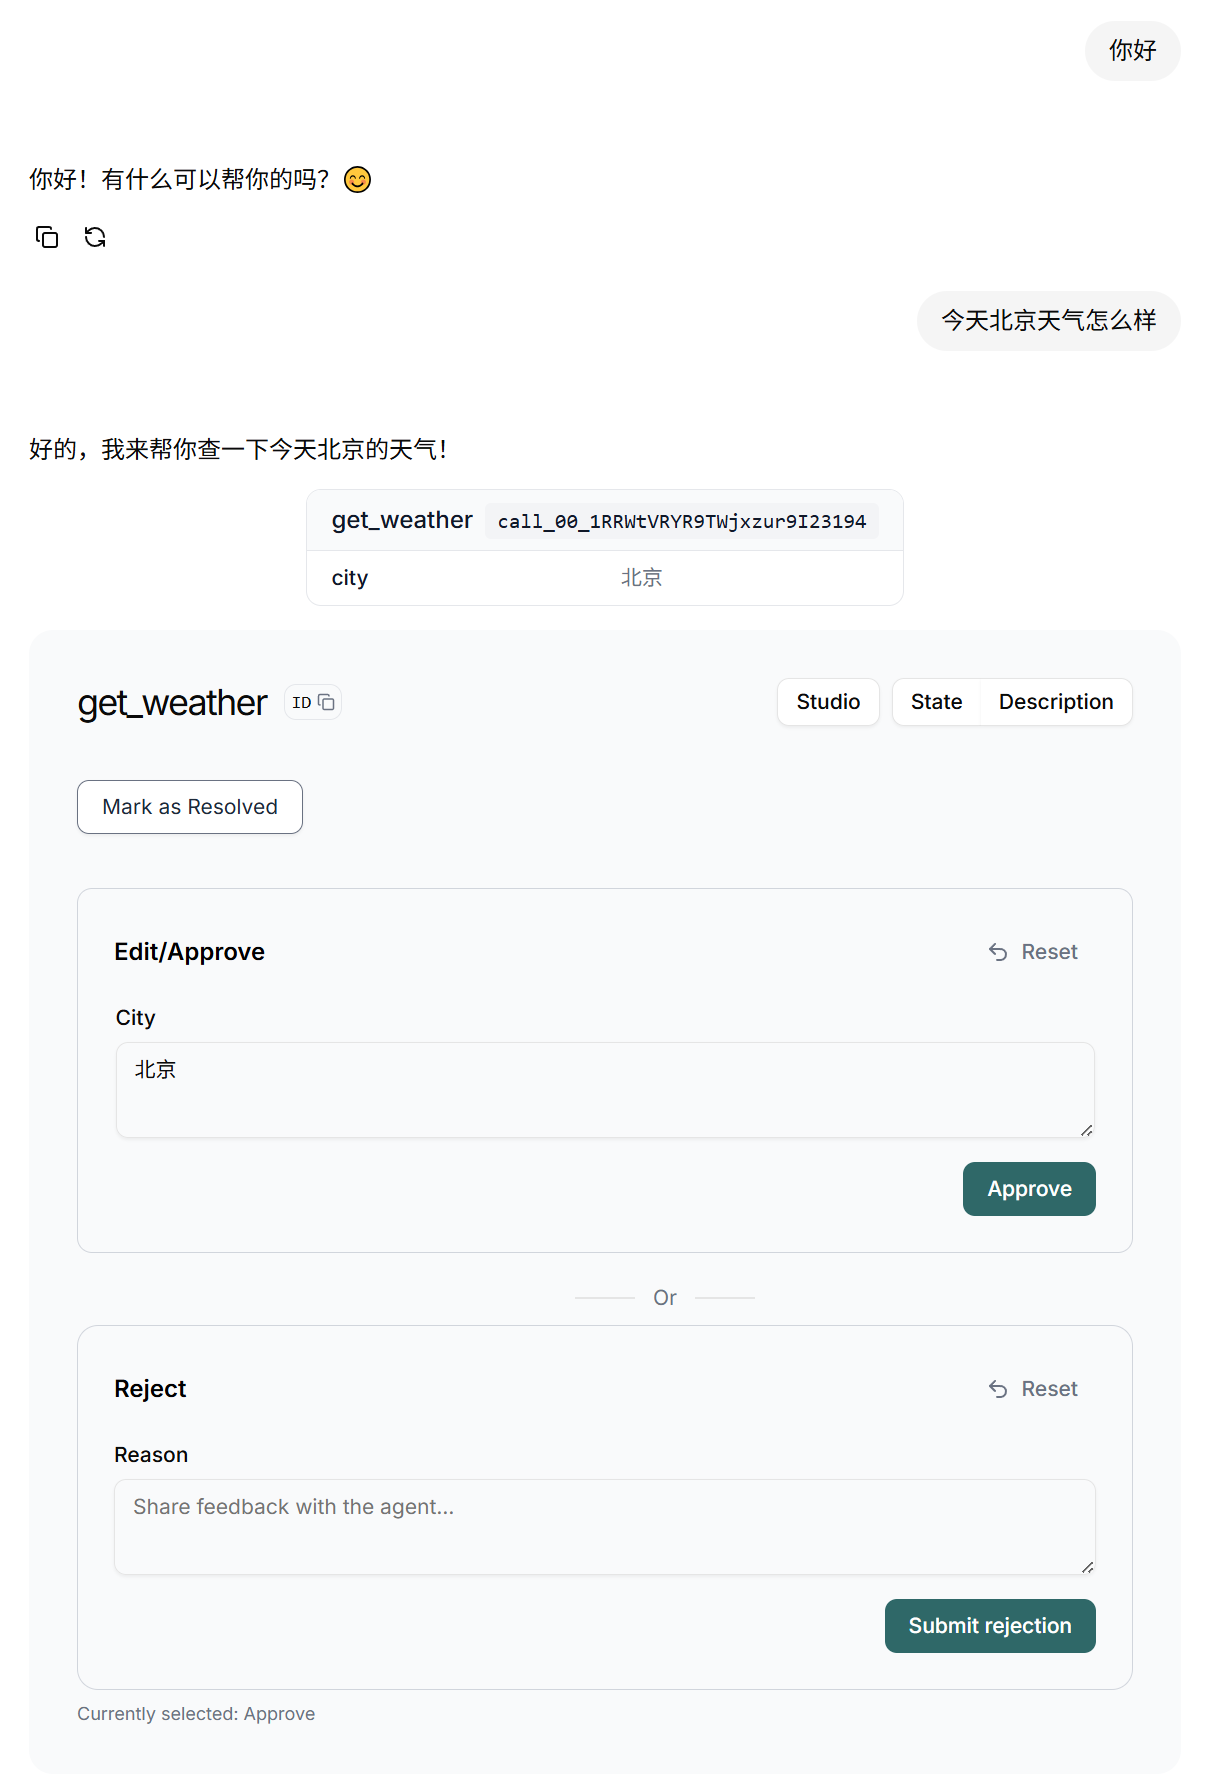

#### 9.2.3.2.1. 同意调用

点击 **`Approve`** 按钮

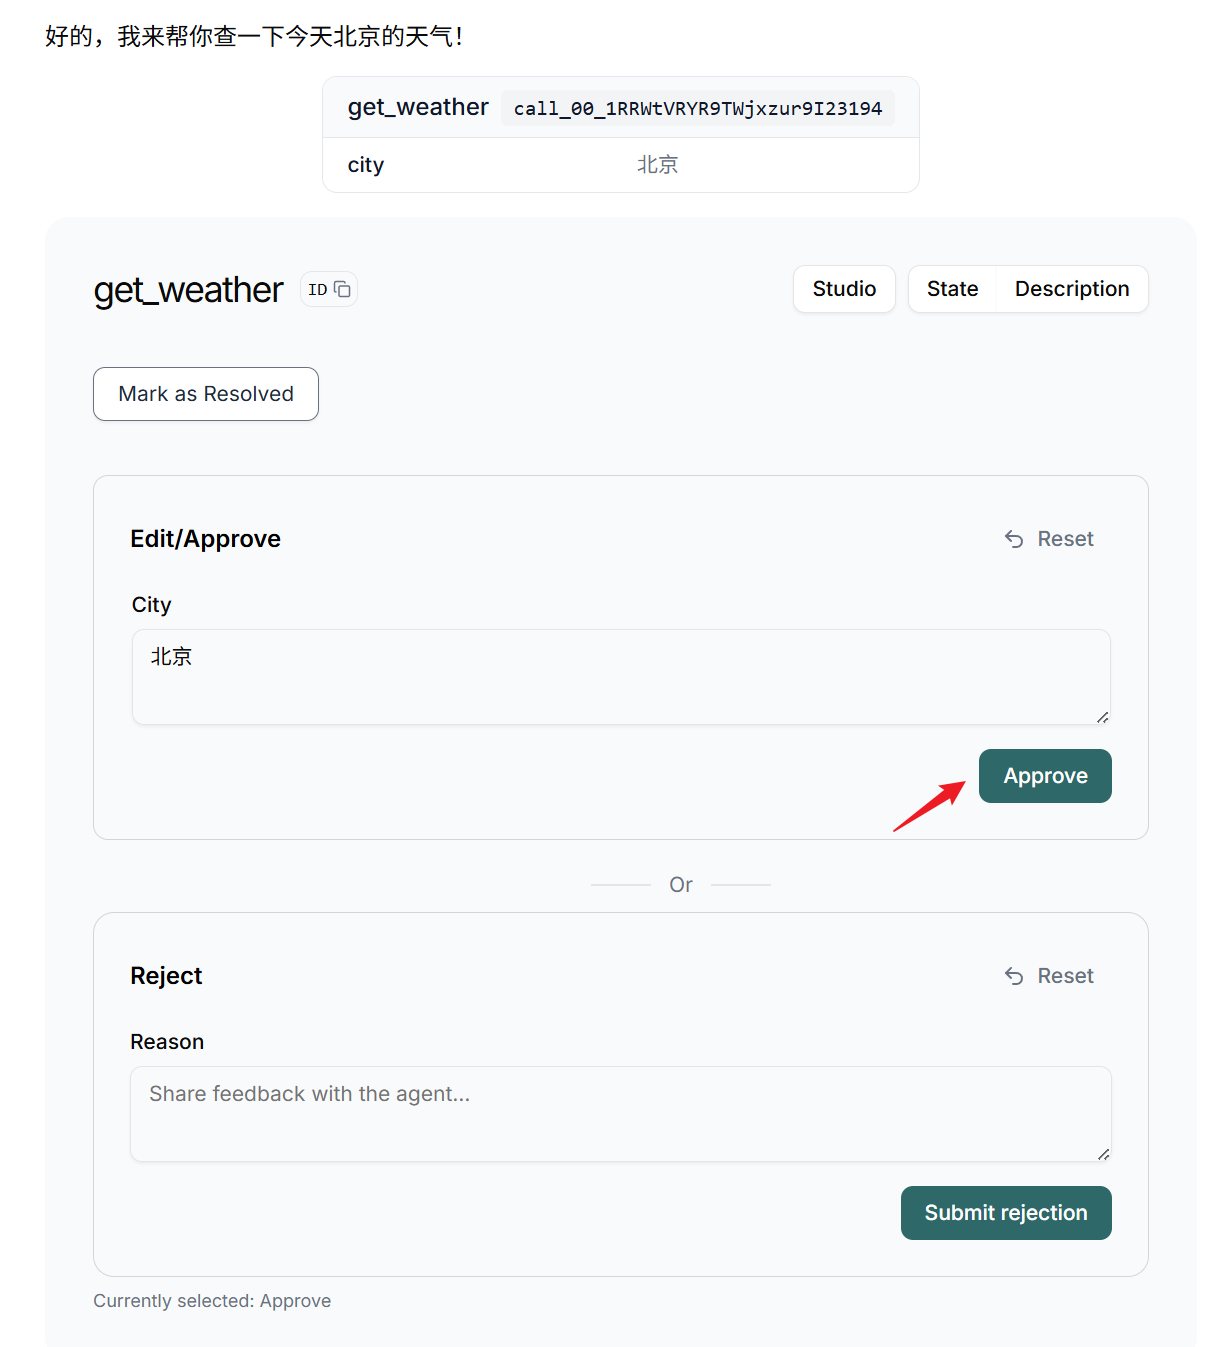

**结果如下**

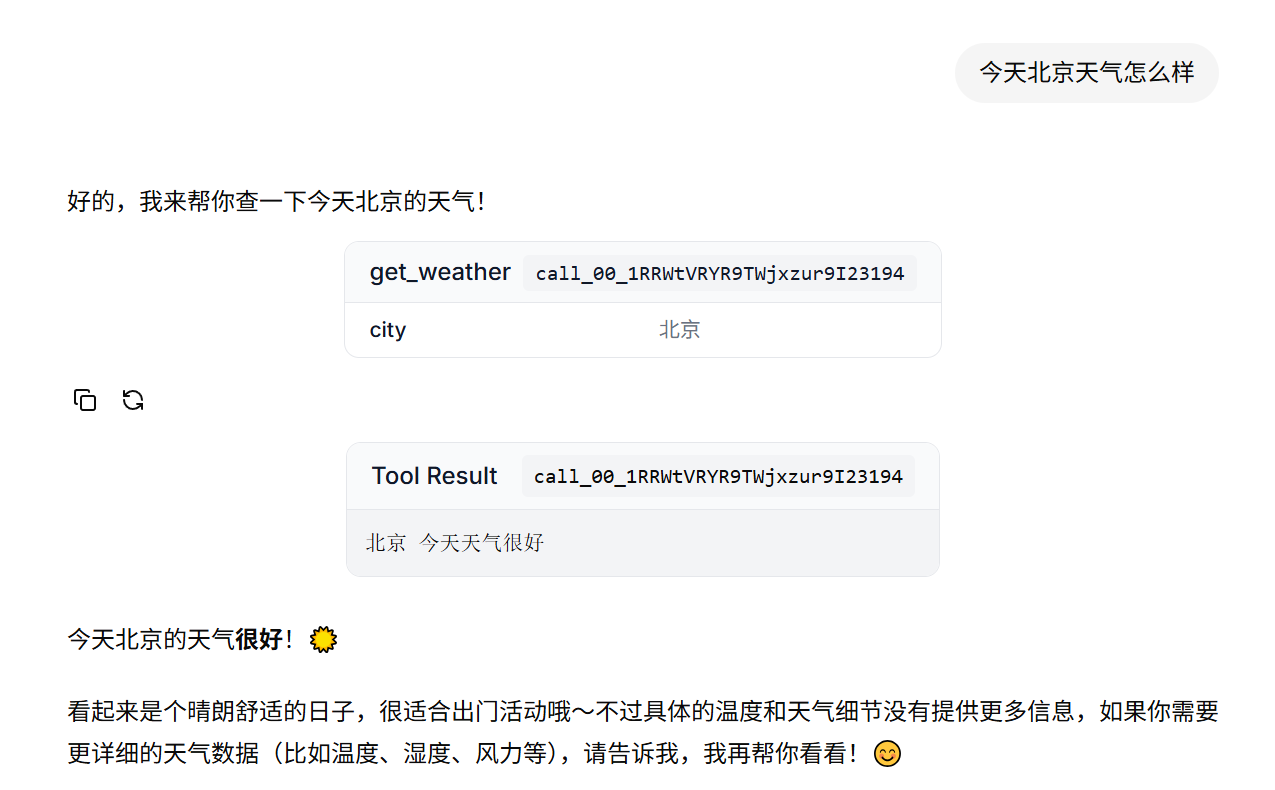

#### 9.2.3.2.2. 修改参数后调用

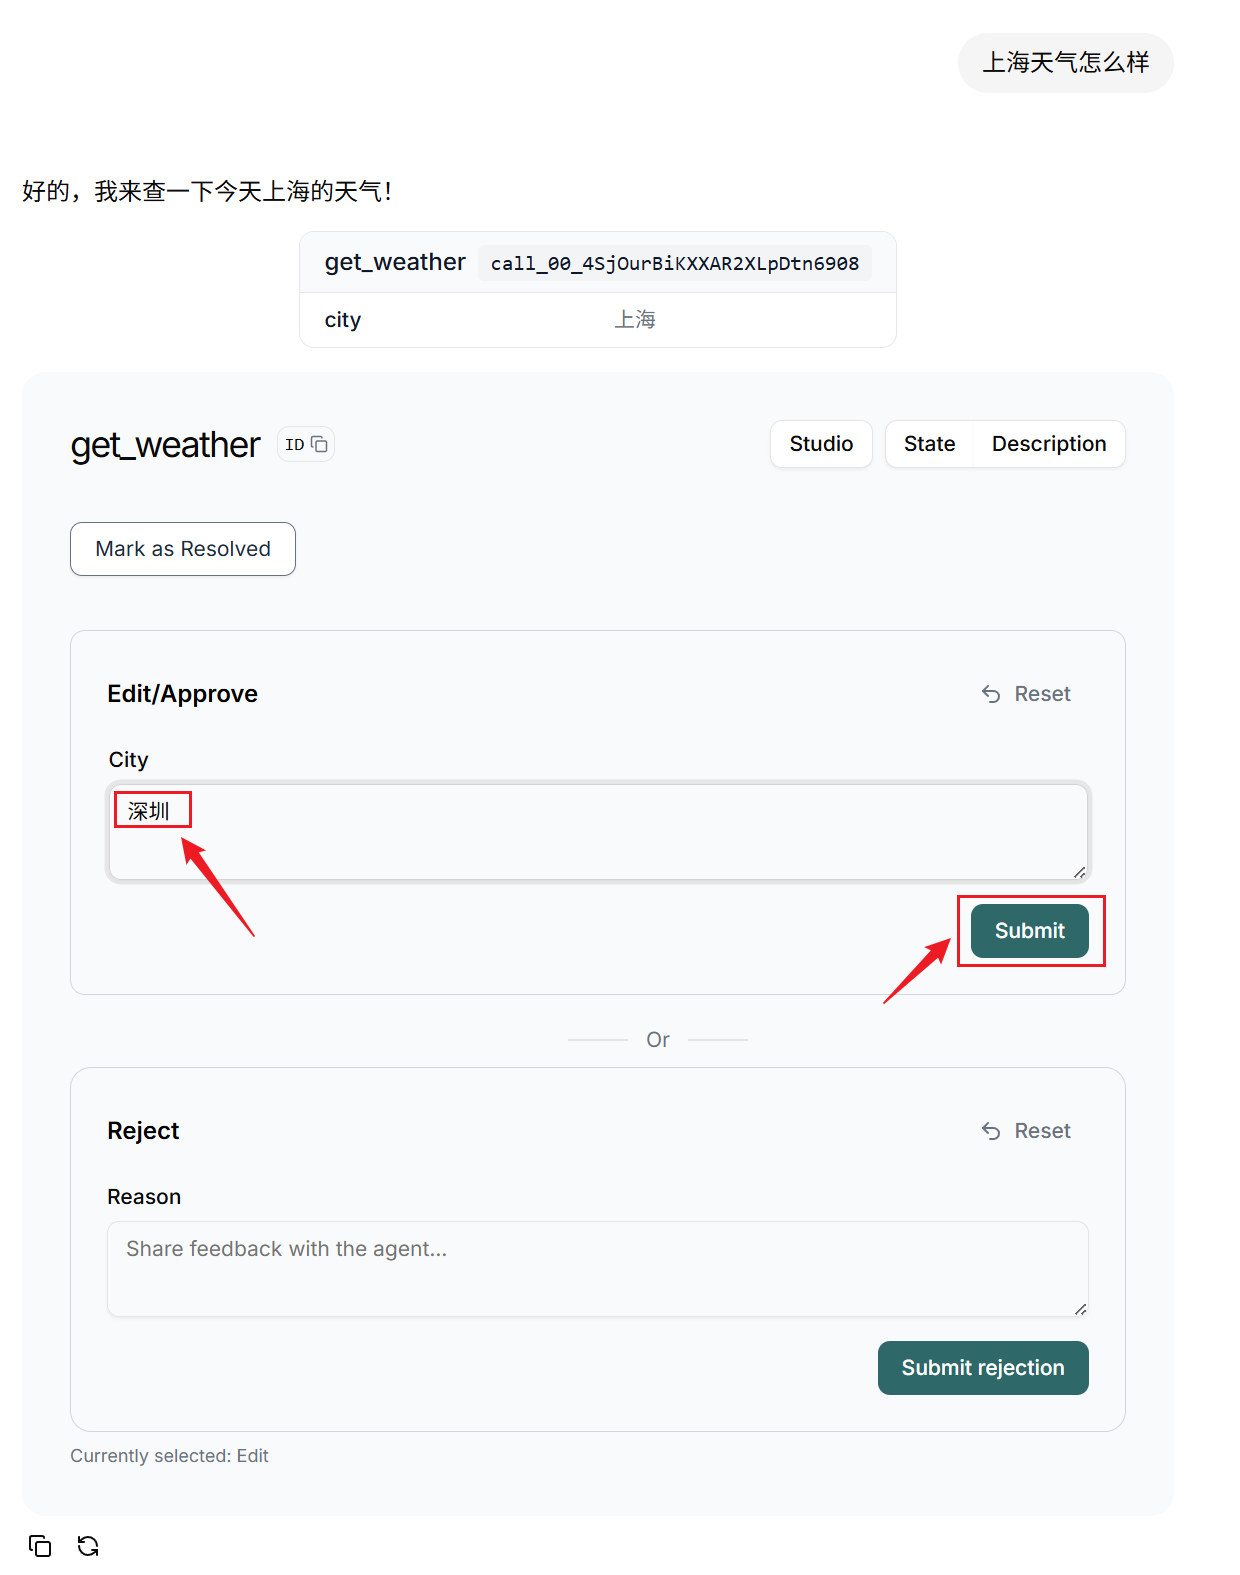

**修改后提交，结果如下**

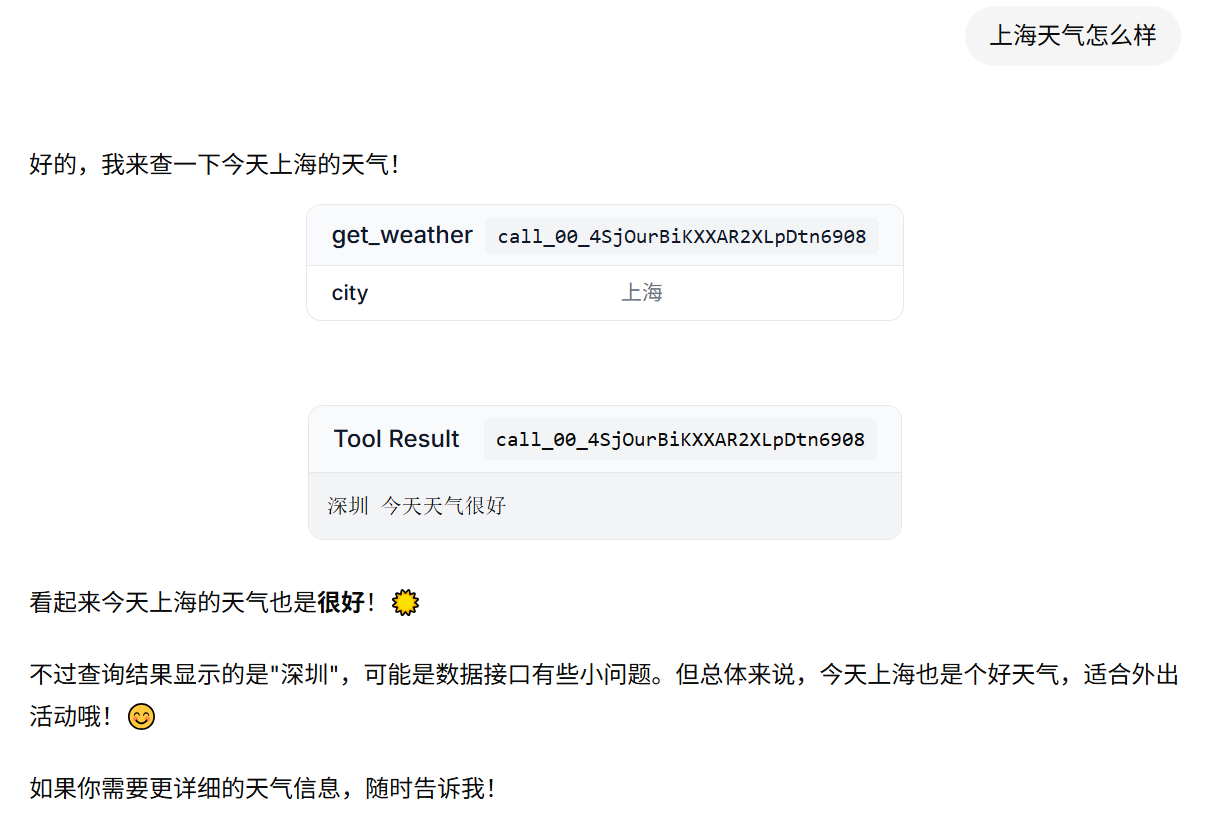

#### 9.2.3.2.3. 拒绝调用

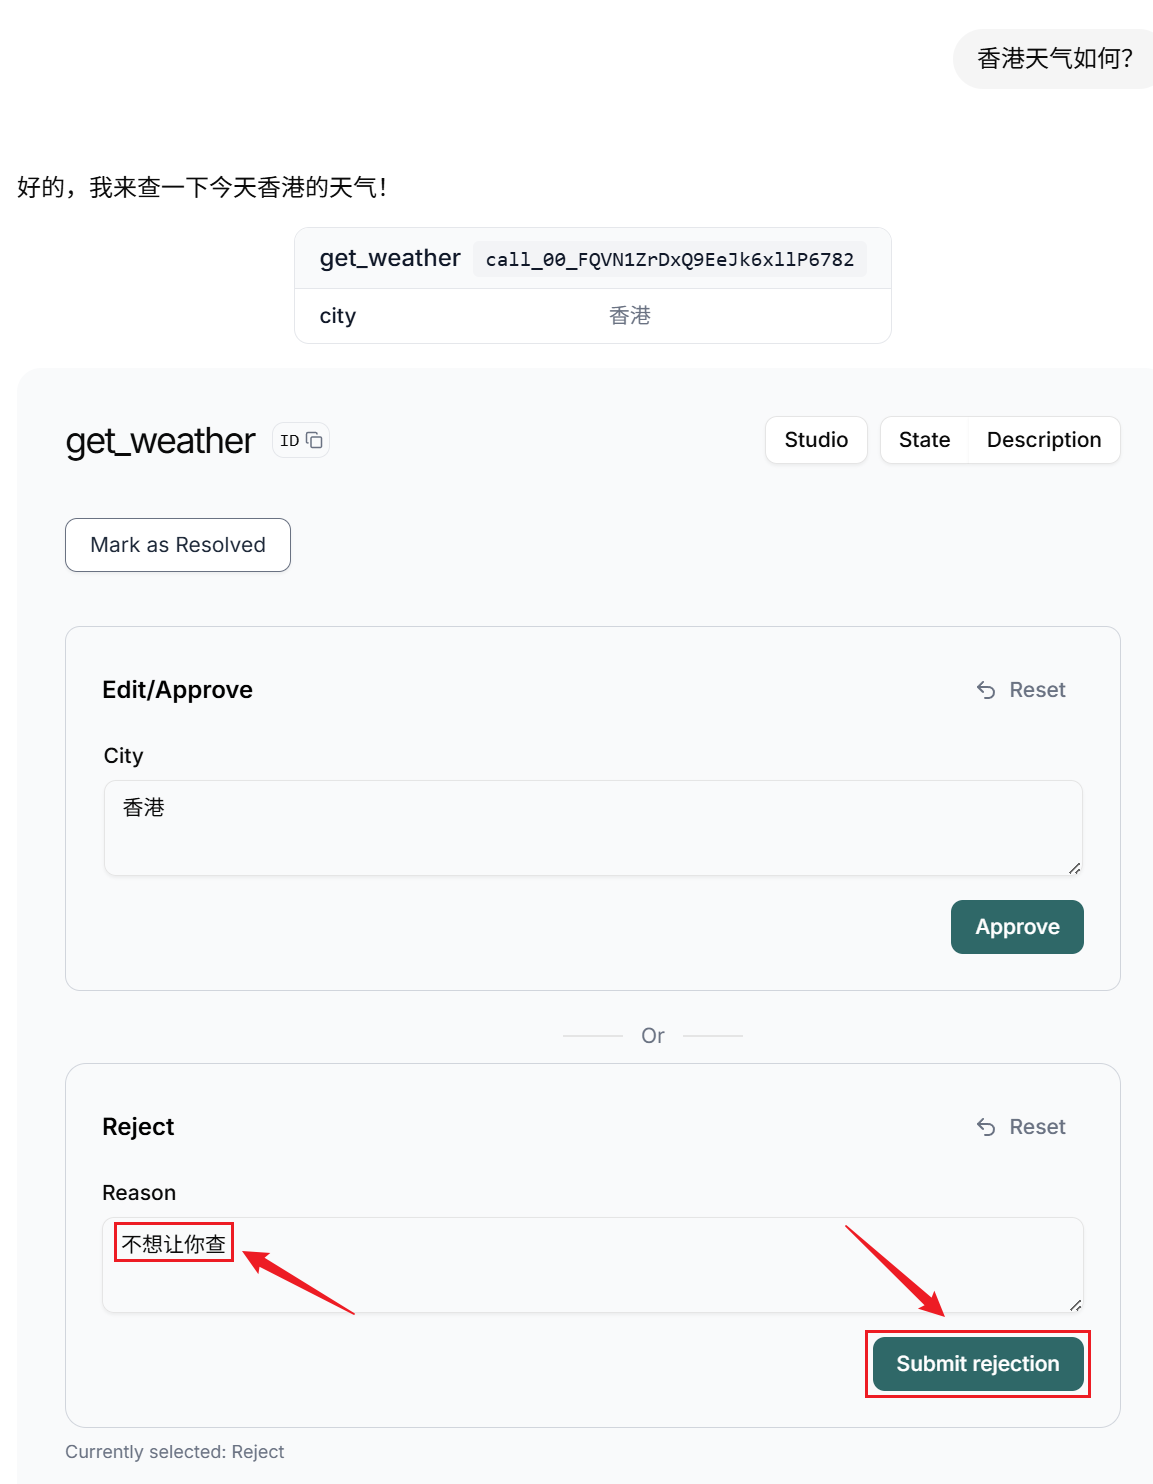

**编辑原因后拒绝，结果如下**

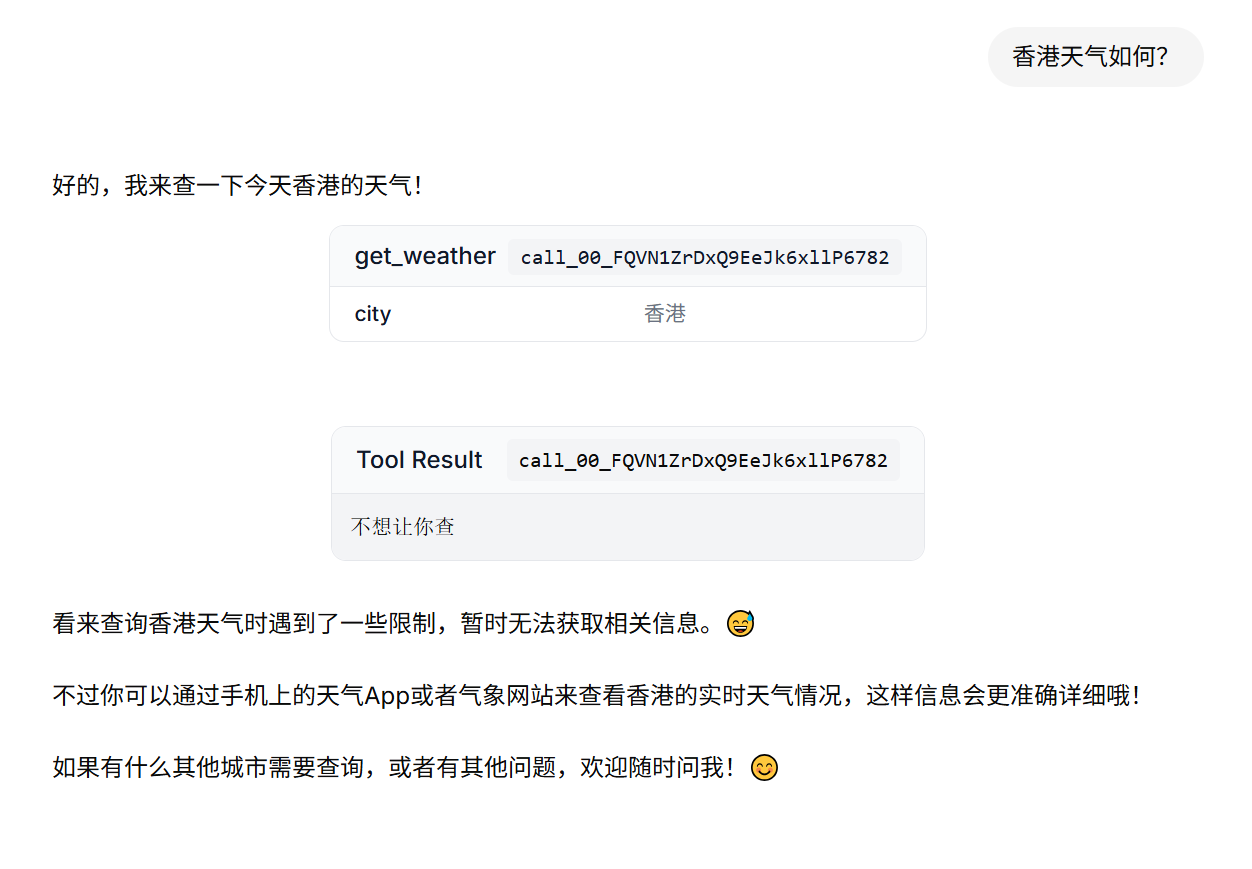

### 9.2.3.3. 查看历史记录

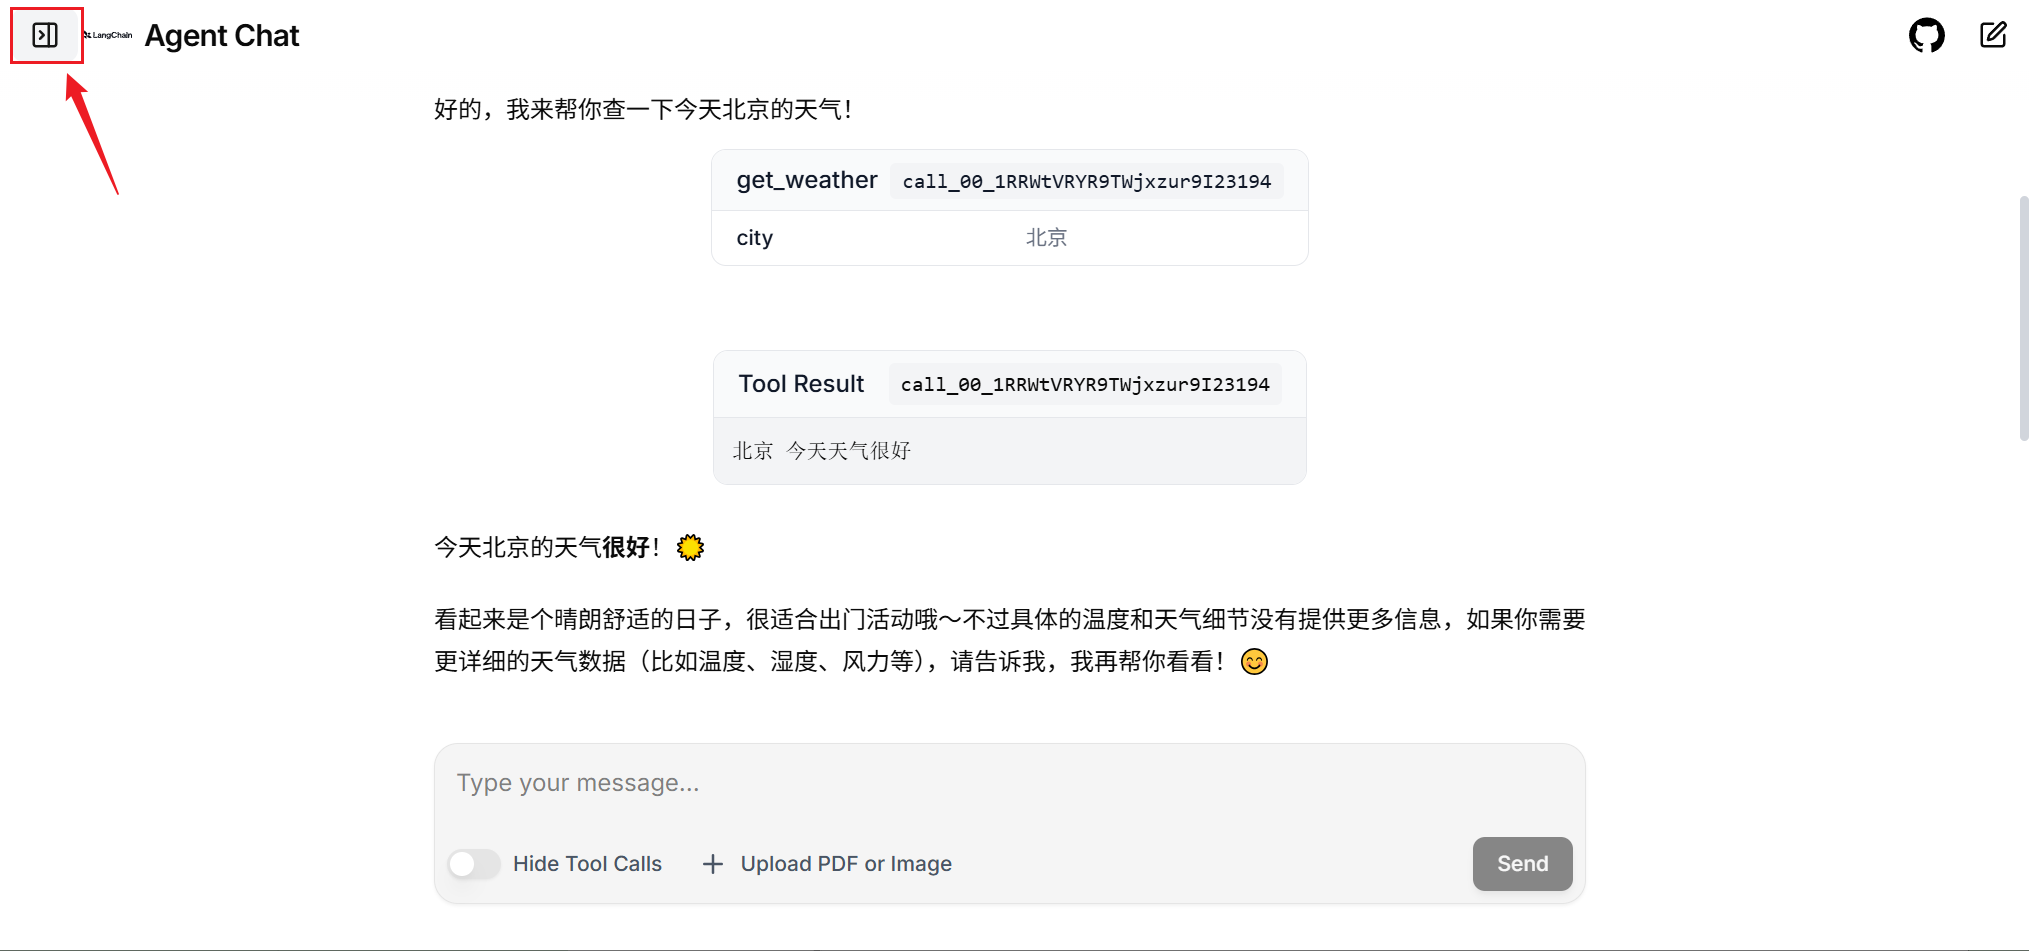

左侧列出了历史会话，点击会话名称即可查看历史会话

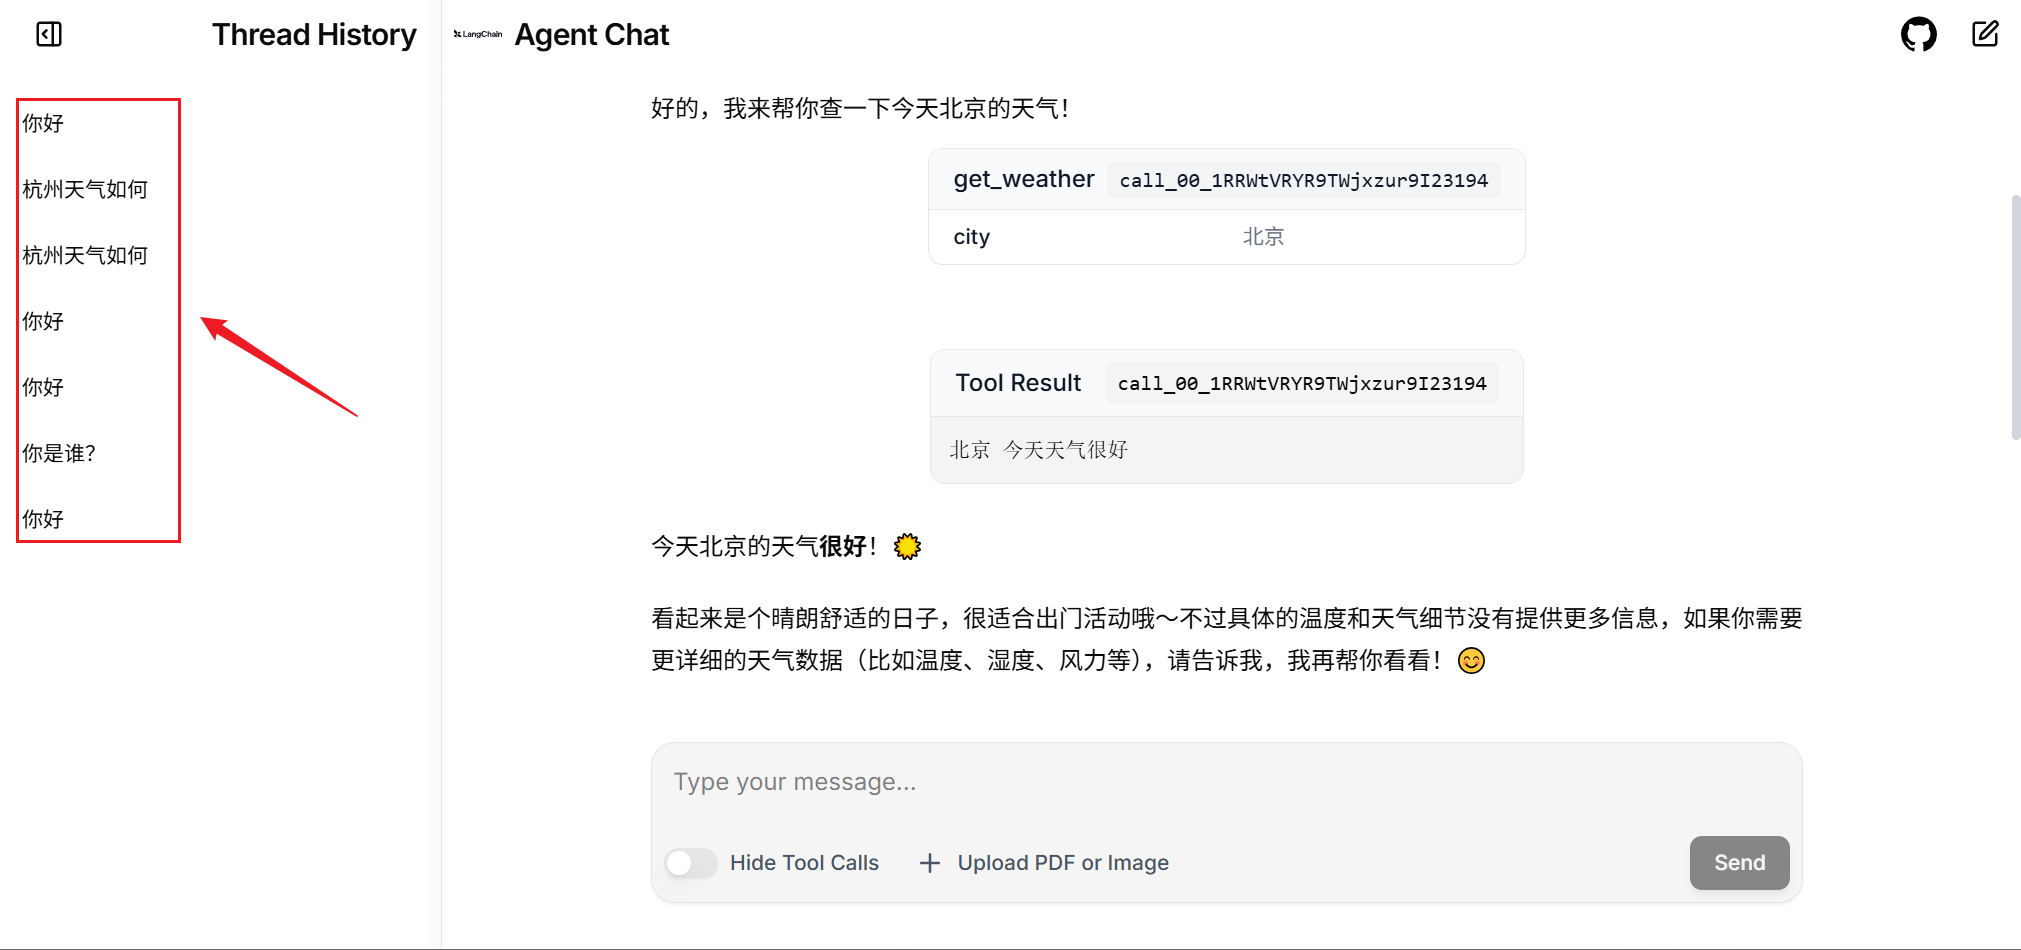

如果配置了 **`LangSmith`** 追踪所需的环境变量，还可以在以下页面追踪调用的详细信息。

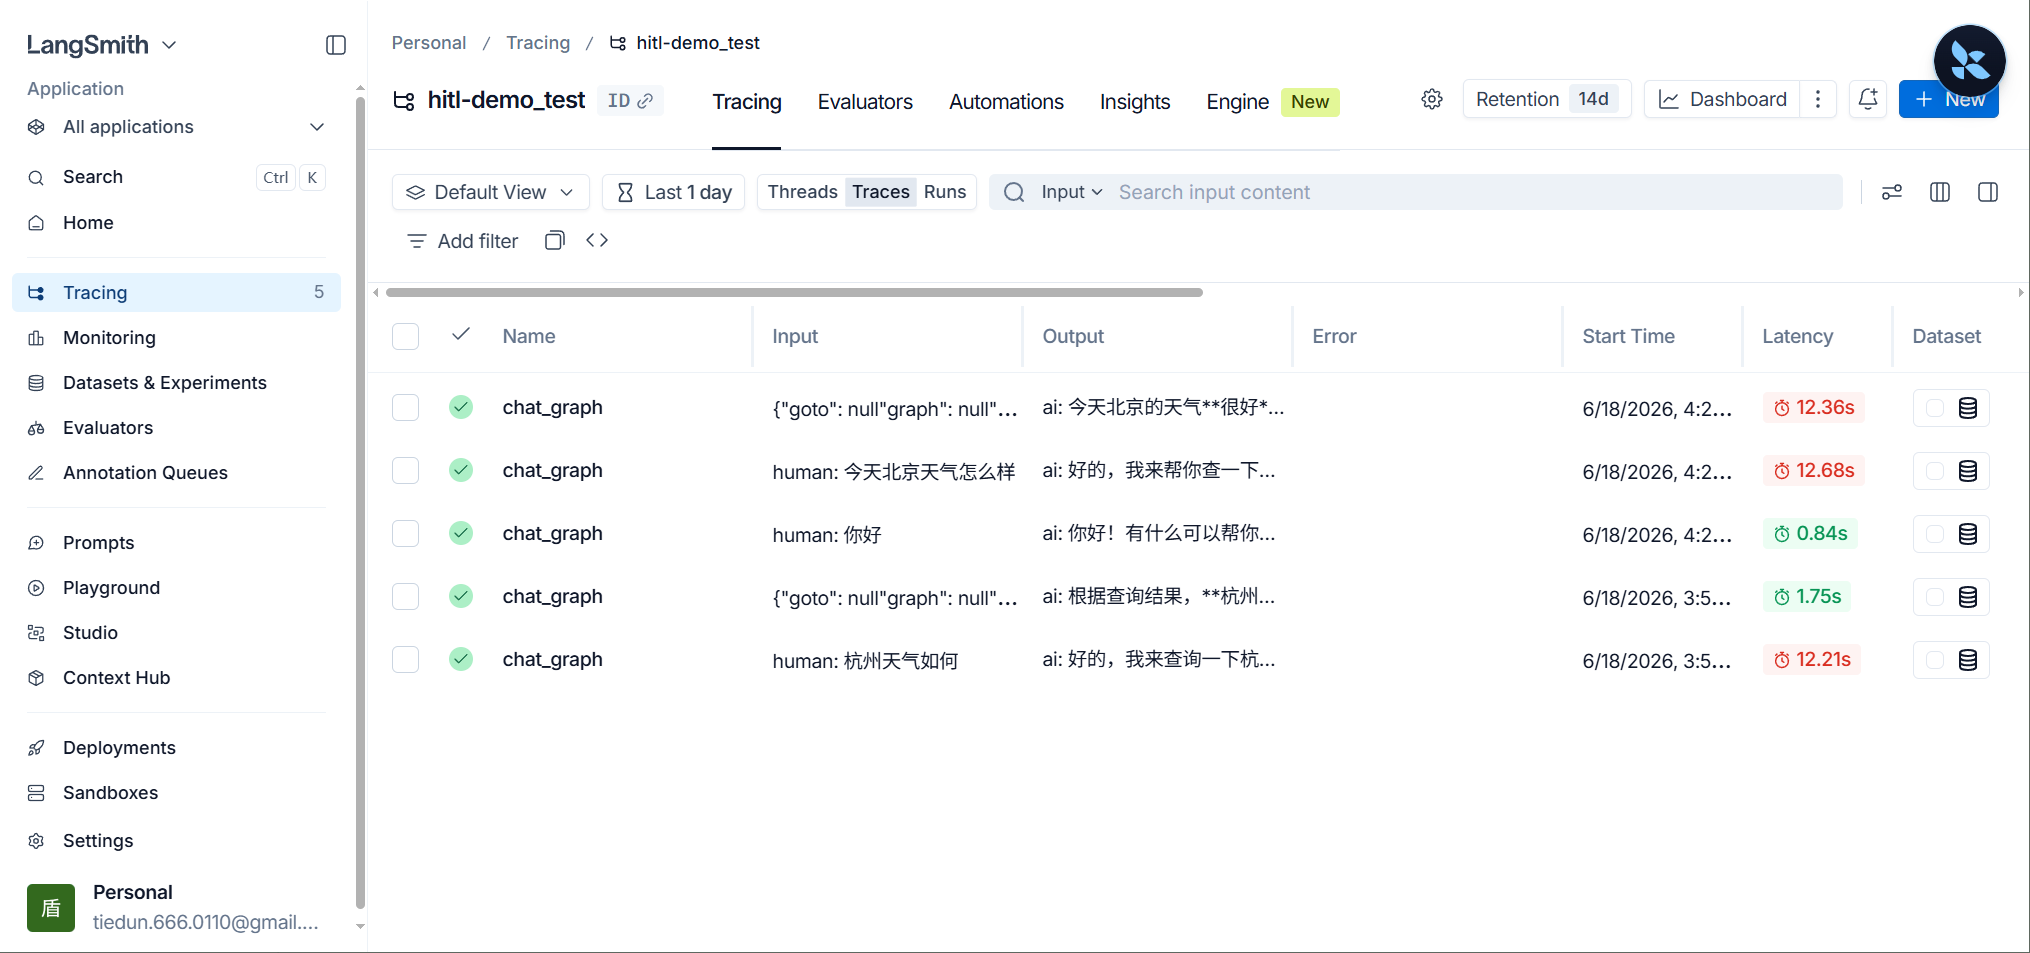


## 10.1. 工具节点的实现


工具是 **`Agent`** 扩展外部能力的重要组件之一。本节以最基础的 **`ReAct` 式工具调用循环**为例，分别介绍手动实现工具节点和使用预构建 **`ToolNode`** 两种方式。

手动实现有助于理解工具调用的基本流程：模型生成工具调用请求，工具节点根据名称查找并执行工具，再将执行结果封装成与原工具调用对应的 **`ToolMessage`**。不过，实际项目还需要处理参数校验、异常处理、运行时注入、并行执行以及 **`Command`** 传播等问题。

**`ToolNode`** 对这些通用逻辑进行了封装，适合在需要自定义图结构和工具调用流程的场景中使用。


## 10.1.1. 手动处理工具调用


```python
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek

from loguru import logger
from dotenv import load_dotenv
load_dotenv(override=True)

@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    查询指定城市的当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气不错"

@tool(parse_docstring=True)
def get_news(home_or_abroad: bool) -> str:
    """
    查询国内外新闻

    Args:
        home_or_abroad: 查询国内还是国外新闻，True: 国内新闻，False：国外新闻
    """
    if home_or_abroad:
        return "Kimi 新模型发布"
    return "Anthropic 暂停新模型访问"

tools_by_name = {
    "get_weather": get_weather,
    "get_news": get_news
}
tools = [get_weather, get_news]

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)
model_with_tools = model.bind_tools(tools=tools)

def llm_node(state: MessagesState) -> MessagesState:
    messages = state['messages']
    response = model_with_tools.invoke(messages)

    return {
        "messages": [response]
    }

def tool_node(state: MessagesState) -> MessagesState:
    last_msg = state['messages'][-1]
    if not last_msg.tool_calls:
        return {}

    tool_msgs = []
    for tool_call in last_msg.tool_calls:
        tool = tools_by_name[tool_call["name"]]
        logger.info("工具 {} 被调用, 对应的 tool_call: {}", tool_call["name"], tool_call)
        tool_res = tool.invoke(tool_call["args"])
        tool_msg = ToolMessage(
            name = tool_call["name"],
            content = tool_res,
            tool_call_id = tool_call["id"]
        )
        tool_msgs.append(tool_msg)

    return {
        "messages": tool_msgs
    }

def router(state: MessagesState) -> Literal["tool_node", END]:
    if state['messages'][-1].tool_calls:
        return "tool_node"
    return END

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", tool_node)
builder.add_edge(START, "llm_node")
builder.add_conditional_edges("llm_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "llm_node")

graph = builder.compile()

from IPython.display import display
display(graph)

res = graph.invoke({"messages": [HumanMessage("今天北京天气如何？国内有哪些新闻")]})
for msg in res['messages']:
    msg.pretty_print()
```


> **注意**
>
> 上面的手动实现会按照 **`tool_calls`** 的顺序串行执行工具，主要用于展示底层流程。**`ToolNode`** 在同步调用中可通过执行器并行处理多个工具调用，在异步调用中则使用 **`asyncio.gather()`** 并发执行。

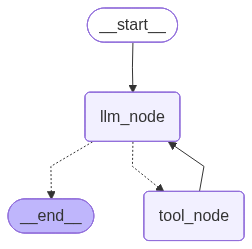


**示例输出（精简）**

```text
================================ Human Message =================================
今天北京天气如何？国内有哪些新闻
================================== Ai Message ==================================
好的，我来查询今天北京的天气和国内新闻。
Tool Calls:
  get_weather (call_00_lpemFmfsKxTtEKjweosB0896)
 Call ID: call_00_lpemFmfsKxTtEKjweosB0896
  Args:
    city: 北京
  get_news (call_01_DDLZCKnovq6EtdrD6XXw2202)
...（中间日志/重复事件省略）...
以下是今天的查询结果：
### 🌤️ 北京天气
今天北京的天气**不错**，适合外出活动哦！
### 📰 国内新闻
目前有一条重要新闻：**Kimi 新模型发布**
如果你想了解更多详情，可以继续问我！
```


## 10.1.2. 用`ToolNode`处理工具调用

上一节的工具节点完成了以下工作：读取最后一条 **`AIMessage`** 中的 **`tool_calls`**，根据工具名称查找并执行对应工具，再把执行结果封装成与原工具调用一一对应的 **`ToolMessage`**。

这种实现适合帮助我们理解工具调用的基本流程，但它只覆盖了最简单的场景。实际项目还需要处理无效工具名、参数校验、异常处理、运行时参数注入、**`Command`** 传播以及多个工具调用的并行执行等问题。

**`LangGraph`** 提供了预构建的 **`ToolNode`**。只需传入工具列表，它便可以完成上述所有操作。


```python
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt.tool_node import ToolNode
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
load_dotenv(override=True)

@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    查询指定城市的当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气不错"

@tool(parse_docstring=True)
def get_news(home_or_abroad: bool) -> str:
    """
    查询国内外新闻

    Args:
        home_or_abroad: 查询国内还是国外新闻，True: 国内新闻，False：国外新闻
    """
    if home_or_abroad:
        return "Kimi 新模型发布"
    return "Anthropic 暂停新模型访问"

tools = [get_weather, get_news]

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)
model_with_tools = model.bind_tools(tools=tools)

def llm_node(state: MessagesState) -> MessagesState:
    messages = state['messages']
    response = model_with_tools.invoke(messages)

    return {
        "messages": [response]
    }

def router(state: MessagesState) -> Literal["tool_node", END]:
    if state['messages'][-1].tool_calls:
        return "tool_node"
    return END

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", ToolNode(tools=tools))
builder.add_edge(START, "llm_node")
builder.add_conditional_edges("llm_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "llm_node")

graph = builder.compile()

from IPython.display import display
display(graph)

res = graph.invoke({"messages": [HumanMessage("今天北京天气如何？国内有哪些新闻？")]})
for msg in res['messages']:
    msg.pretty_print()
```


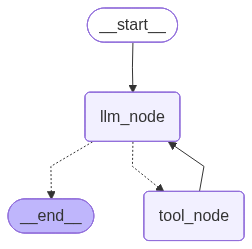


**示例输出（精简）**

```text
================================ Human Message =================================
今天北京天气如何？国内有哪些新闻？
================================== Ai Message ==================================
好的，我来同时查询北京天气和国内新闻。
Tool Calls:
  get_weather (call_00_BBHYjTwSiWbGolSrp7yb9812)
 Call ID: call_00_BBHYjTwSiWbGolSrp7yb9812
  Args:
    city: 北京
  get_news (call_01_3XEu887comx2s1SMtw8h3282)
 Call ID: call_01_3XEu887comx2s1SMtw8h3282
  Args:
...（中间日志/重复事件省略）...
---
### 🌤️ 北京今日天气
北京今天**天气不错**，适合外出活动。
### 📰 国内新闻
今日国内有一条重要新闻：**Kimi 新模型发布**。
如果您想了解更多详细内容，随时可以继续问我！
```


## 10.2.1. `ToolRuntime`介绍


**`ToolRuntime`** 是专门面向工具调用的运行时对象。

按照官方规范：

- 工具函数中存在名为 **`runtime`**
- 并且类型标注为 **`ToolRuntime`** 的参数时

底层运行时会在调用工具前自动注入 **`ToolRuntime`** 实例。根据源码实现，某些不规范的写法也能注入运行时实例，但并不规范，不推荐。

需要注意，**`ToolRuntime`** 与图节点中使用的 **`langgraph.runtime.Runtime`** 并不是同一个类型。前者额外提供了当前图状态、运行配置和工具调用 ID 等工具调用专属信息。

当前版本，**`ToolRuntime`** 的核心定义如下：


```python
@dataclass
class ToolRuntime(_DirectlyInjectedToolArg, Generic[ContextT, StateT]):
    state: StateT
    context: ContextT
    config: RunnableConfig
    stream_writer: StreamWriter
    tool_call_id: str | None
    store: BaseStore | None
```


- **`state`**：图状态，短期记忆
- **`context`**：运行时上下文
- **`config`**：运行时配置，包含元数据
- **`stream_writer`**：自定义流式输出写入器
- **`tool_call_id`**：工具调用 **`ID`**
- **`store`**：长期记忆

借助 **`runtime`**，工具可以访问上述所有资源。


## 10.2.2. 在工具中更新状态

工具不仅可以返回普通结果，还可以返回 **`Command(update=...)`**，将业务结果写入图状态。

当工具由模型发起调用时，消息历史中的 **`AIMessage.tool_calls`** 必须紧跟与之匹配的 **`ToolMessage`**。

当工具返回普通结果时，**`ToolNode`** 会帮我们完成运行结果到 **`ToolMessage`** 的转换，并追加到消息列表。

但工具返回 **`Command`** 时，上述操作需要开发者完成，此时还应在 **`Command.update`** 的消息字段中写入对应的 **`ToolMessage`**。

如果同一轮并行执行的多个工具可能更新同一个普通状态字段，需要为该字段配置合适的归并函数；否则可能出现并发更新冲突。本例中的两个工具分别更新 **`weather_res`** 和 **`news_res`**，因此不存在该问题。


```python
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt.tool_node import ToolNode, ToolRuntime
from langgraph.types import Command
from langgraph.graph.message import MessagesState

from langchain.messages import HumanMessage, ToolMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv
load_dotenv(override=True)

class OverAllState(MessagesState):
    weather_res: str
    news_res: str

@tool(parse_docstring=True)
def get_weather(city: str, runtime: ToolRuntime) -> Command:
    """
    查询指定城市的当日天气

    Args:
        city: 城市名称
    """
    res = f"{city} 今天天气不错"
    tool_call_id = runtime.tool_call_id
    tool_msg = ToolMessage(tool_call_id=tool_call_id, content=res)
    return Command(
        update = {
            "weather_res": res,
            "messages": [tool_msg]
        }
    )

@tool(parse_docstring=True)
def get_news(home_or_abroad: bool, runtime: ToolRuntime) -> Command:
    """
    查询国内外新闻

    Args:
        home_or_abroad: 查询国内还是国外新闻，True: 国内新闻，False：国外新闻
    """
    if home_or_abroad:
        res = "Kimi 新模型发布"
    else:
        res = "Anthropic 暂停新模型访问"
    tool_call_id = runtime.tool_call_id
    tool_msg = ToolMessage(tool_call_id=tool_call_id, content=res)
    return Command(
        update = {
            "news_res": res,
            "messages": [tool_msg]
        }
    )

tools = [get_weather, get_news]

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)
model_with_tools = model.bind_tools(tools=tools)

def llm_node(state: OverAllState) -> OverAllState:
    messages = state['messages']
    response = model_with_tools.invoke(messages)

    return {
        "messages": [response]
    }

def router(state: OverAllState) -> Literal["tool_node", END]:
    if state['messages'][-1].tool_calls:
        return "tool_node"
    return END

builder = StateGraph(state_schema=OverAllState)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", ToolNode(tools=tools))
builder.add_edge(START, "llm_node")
builder.add_conditional_edges("llm_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "llm_node")

graph = builder.compile()

from IPython.display import display
display(graph)

res = graph.invoke({"messages": [HumanMessage("今天北京天气如何？国内有哪些新闻？")]})
print('=' * 30, '-> messages <-', '=' * 30)
for msg in res.pop('messages'):
    msg.pretty_print()

print('=' * 30, '-> res without messages <-', '=' * 30)
print(res)
```


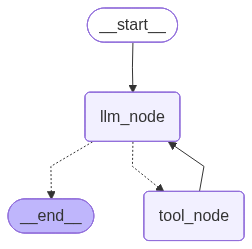


**示例输出（精简）**

```text
============================== -> messages <- ==============================
================================ Human Message =================================
今天北京天气如何？国内有哪些新闻？
================================== Ai Message ==================================
好的，我来同时查询北京天气和国内新闻。
Tool Calls:
  get_weather (call_00_hbEppxygz7DLDwaxg8X19090)
 Call ID: call_00_hbEppxygz7DLDwaxg8X19090
  Args:
    city: 北京
  get_news (call_01_wkG4j5Hjq4wkyTOaxzxT5267)
 Call ID: call_01_wkG4j5Hjq4wkyTOaxzxT5267
...（中间日志/重复事件省略）...
今天北京的天气**不错**，比较适宜出行。
### 📰 国内新闻
- **Kimi 新模型发布** — 国内AI领域又有新动态。
如果您想了解更多详情，可以继续问我！
============================== -> res without messages <- ==============================
{'weather_res': '北京 今天天气不错', 'news_res': 'Kimi 新模型发布'}
```


## 10.2.3. 工具节点执行与容错机制

**`ToolNode`** 提供同步工具调用包装器 **`wrap_tool_call`**，用于在工具执行前后插入自定义逻辑。

它与 **`LangChain Agent`** 中间件 **`wrap_tool_call`** 的核心机制相同：接收当前工具调用请求 **`request`** 和真正执行工具的回调 **`execute`**，可以选择不调用、调用一次或多次 **`execute(request)`**，并最终返回 **`ToolMessage`** 或 **`Command`**。

因此，**`wrap_tool_call`** 可以用于重试、缓存、请求改写、短路返回和自定义控制流等场景。异步工具链路还可以使用对应的 **`awrap_tool_call`**。

此处通过重试和缓存机制的实现，介绍 **`wrap_tool_call`** 的用法。


## 10.2.3.1. 实现重试机制


```python
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt.tool_node import ToolNode
from langgraph.graph.message import MessagesState

from langchain.messages import HumanMessage, ToolMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek

from dataclasses import dataclass
from loguru import logger
from dotenv import load_dotenv
load_dotenv(override=True)

import random

@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    查询指定城市的当日天气

    Args:
        city: 城市名称
    """
    # 70% 概率因网络波动而调用失败
    rand_int = random.randint(1,10)
    if rand_int < 8:
        raise ConnectionError("网络波动失败")
    return f"{city} 今天天气不错"

tools = [get_weather]

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)
model_with_tools = model.bind_tools(tools=tools)

@dataclass
class UserContext:
    max_attempts: int

def llm_node(state: MessagesState) -> MessagesState:
    messages = state['messages']
    response = model_with_tools.invoke(messages)

    return {
        "messages": [response]
    }

def router(state: MessagesState) -> Literal["tool_node", END]:
    if state['messages'][-1].tool_calls:
        return "tool_node"
    return END

def wrap_tool_call(request, execute):
    max_attempts = request.runtime.context.max_attempts
    tool_call_id = request.runtime.tool_call_id

    tool_msg = ""
    for i in range(max_attempts):
        try:
            tool_msg = execute(request)
            break
        except ConnectionError as e:
            logger.info("工具调用失败，当前调用次数: {}, 调用次数上限: {}, 异常信息: {}", i + 1, max_attempts, e)

    if not tool_msg:
        tool_msg = ToolMessage(
            tool_call_id = tool_call_id,
            content = "调用次数到达上限，调用失败"
        )

    return tool_msg

builder = StateGraph(state_schema=MessagesState, context_schema=UserContext)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", ToolNode(tools=tools, wrap_tool_call=wrap_tool_call))
builder.add_edge(START, "llm_node")
builder.add_conditional_edges("llm_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "llm_node")

graph = builder.compile()

from IPython.display import display
display(graph)

res = graph.invoke(
    {"messages": [HumanMessage("今天北京天气如何？")]},
    context = UserContext(max_attempts=3))
for msg in res['messages']:
    msg.pretty_print()
```


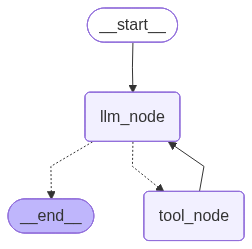

按照当前设计，每次工具调用有 **`70%`** 的概率失败，最多尝试 **`3`** 次。仍然可能最终失败，如下所示。


**示例输出（精简）**

```text
================================ Human Message =================================
今天北京天气如何？
================================== Ai Message ==================================
好的，我来查询一下北京今天的天气情况。
Tool Calls:
  get_weather (call_00_iYUeyQlDB0NuAAkcU1Zy3110)
 Call ID: call_00_iYUeyQlDB0NuAAkcU1Zy3110
  Args:
    city: 北京
================================= Tool Message =================================
调用次数到达上限，调用失败
================================== Ai Message ==================================
抱歉，查询天气的服务暂时遇到了问题，无法获取到北京今天的天气信息。可能是以下原因导致的：
1. **服务暂时不可用** - 可能是天气数据接口出现了临时故障
2. **网络问题** - 查询过程中网络连接不稳定
建议您可以：
- **稍后再试**，看看服务是否恢复
- 通过手机上的天气App或浏览器搜索"北京天气"来获取最新信息
非常抱歉给您带来不便！如果还有其他问题需要帮助，请随时告诉我。
```


也有可能最终成功，如下


```text
2026-06-22 14:03:22.371 | INFO     | __main__:wrap_tool_call:70 - 工具调用失败，当前调用次数: 1, 调用次数上限: 3, 异常信息: 网络波动失败
================================ Human Message =================================

今天北京天气如何？
================================== Ai Message ==================================

好的，我来帮你查询一下今天北京的天气情况。
Tool Calls:
  get_weather (call_00_IXWZ2mg3lxI09gzm9BbZ4314)
 Call ID: call_00_IXWZ2mg3lxI09gzm9BbZ4314
  Args:
    city: 北京
================================= Tool Message =================================
Name: get_weather

北京 今天天气不错
================================== Ai Message ==================================

今天北京的天气**不错**，是个适合外出活动的好日子！☀️

如果你需要更详细的天气信息（比如具体温度、风向等），可以告诉我，我再帮你进一步查询。
```


## 10.2.3.2. 实现缓存机制


```python
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt.tool_node import ToolNode
from langgraph.graph.message import MessagesState

from langchain.messages import HumanMessage, ToolMessage
from langchain.tools import tool
from langchain_deepseek import ChatDeepSeek

from loguru import logger
import json
from dotenv import load_dotenv
load_dotenv(override=True)

@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    查询指定城市的当日天气

    Args:
        city: 城市名称
    """
    return f"{city} 今天天气不错"

tools = [get_weather]

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)
model_with_tools = model.bind_tools(tools=tools)

def llm_node(state: MessagesState) -> MessagesState:
    messages = state['messages']
    response = model_with_tools.invoke(messages)

    return {
        "messages": [response]
    }

def router(state: MessagesState) -> Literal["tool_node", END]:
    if state['messages'][-1].tool_calls:
        return "tool_node"
    return END

global_cache = dict()
def wrap_tool_call(request, execute):
    tool_name = request.tool_call["name"]
    tool_args = json.dumps(request.tool_call["args"])
    tool_call_id = request.runtime.tool_call_id

    cache_key = (tool_name, tool_args)
    cache = global_cache.get(cache_key)

    if cache:
        logger.info("{} 调用命中缓存", tool_name)
        tool_msg = ToolMessage(
            tool_call_id = tool_call_id,
            content = cache
        )
    else:
        tool_msg = execute(request)
        logger.info("将 {} 的调用结果写入缓存", tool_name)
        global_cache[cache_key] = tool_msg.content

    return tool_msg

builder = StateGraph(state_schema=MessagesState)
builder.add_node("llm_node", llm_node)
builder.add_node("tool_node", ToolNode(tools=tools, wrap_tool_call=wrap_tool_call))
builder.add_edge(START, "llm_node")
builder.add_conditional_edges("llm_node", router, path_map=["tool_node", END])
builder.add_edge("tool_node", "llm_node")

graph = builder.compile()

from IPython.display import display
display(graph)

print('=' * 30, '-> 第一次调用 - 北京 <-', '=' * 30)
res = graph.invoke({"messages": [HumanMessage("今天北京天气如何？")]})
for msg in res['messages']:
    msg.pretty_print()

print('=' * 30, '-> 第二次调用 - 北京 <-', '=' * 30)
res = graph.invoke({"messages": [HumanMessage("今天北京天气如何？")]})
for msg in res['messages']:
    msg.pretty_print()

print('=' * 30, '-> 第三次调用 - 杭州 <-', '=' * 30)
res = graph.invoke({"messages": [HumanMessage("今天杭州天气如何？")]})
for msg in res['messages']:
    msg.pretty_print()
```


> **注意**
>
> 这里使用的 **`global_cache`** 只是进程内缓存，主要用于演示：它没有 **`TTL`**、容量限制、并发保护和持久化能力，也只缓存普通 **`ToolMessage`** 的内容。生产环境应根据数据时效性选择 **`Redis`** 等缓存系统，并把用户、权限、地域、工具版本等会影响结果的因素纳入缓存键；具有副作用的工具通常不应直接缓存。

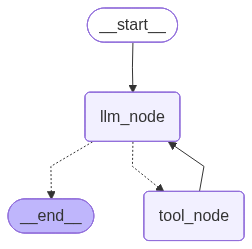


**示例输出（精简）**

```text
============================== -> 第一次调用 - 北京 <- ==============================

================================ Human Message =================================
今天北京天气如何？
================================== Ai Message ==================================
好的，我来查询一下北京今天的天气情况。
Tool Calls:
  get_weather (call_00_RWpYgZGeskrexH2dOWol2713)
 Call ID: call_00_RWpYgZGeskrexH2dOWol2713
  Args:
    city: 北京
================================= Tool Message =================================
...（中间日志/重复事件省略）...
    city: 杭州
================================= Tool Message =================================
Name: get_weather
杭州 今天天气不错
================================== Ai Message ==================================
杭州今天天气不错！☀️ 看起来是一个适合出行或者户外活动的好日子。如果你有出门的计划，可以放心安排哦～不过如果需要更具体的温度、风力等信息，建议可以再查一下实时的天气预报。😊
```


## 复习：工具调用的消息闭环

`AIMessage.tool_calls` 描述要调用的工具及参数；工具执行后的 `ToolMessage` 用 `tool_call_id` 与该请求关联；模型再读取工具结果，决定回答或继续调用。ToolNode 负责执行工具和构造结果消息，模型本身不直接运行 Python 工具函数。

**面试提示**：动态中断恢复时重跑的是整个中断节点，不是只跑 interrupt 后的部分。同节点多个中断按调用顺序匹配恢复值，并行中断则应按中断 ID 提供各自反馈。
